In [1]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = torch.device("cpu")
    print("Using CPU")

PyTorch: 2.13.0+cpu
CUDA available: False
Using CPU


In [3]:
import os

NOTEBOOK_DIR = os.getcwd()
PROJECT_ROOT = os.path.dirname(NOTEBOOK_DIR)
DATASET_ROOT = os.path.join(PROJECT_ROOT, "BP_Dataset")

print("Notebook directory:", NOTEBOOK_DIR)
print("Project root:", PROJECT_ROOT)
print("Dataset root:", DATASET_ROOT)
print("Dataset exists:", os.path.exists(DATASET_ROOT))

Notebook directory: c:\Users\diksh\OneDrive\Desktop\VT_Project\notebooks
Project root: c:\Users\diksh\OneDrive\Desktop\VT_Project
Dataset root: c:\Users\diksh\OneDrive\Desktop\VT_Project\BP_Dataset
Dataset exists: True


In [4]:
from pathlib import Path

DATASET_ROOT = Path(r"C:\Users\diksh\OneDrive\Desktop\VT_Project\BP_Dataset")
TRAIN_IMG = DATASET_ROOT / "train" / "images"
VAL_IMG   = DATASET_ROOT / "val" / "images"
TEST_IMG  = DATASET_ROOT / "test" / "images"

TRAIN_CSV = DATASET_ROOT / "train" / "labels.csv"
VAL_CSV   = DATASET_ROOT / "val" / "labels.csv"
TEST_CSV  = DATASET_ROOT / "test" / "labels.csv"

print("Dataset root:", DATASET_ROOT)
print()

print("Train images:", TRAIN_IMG.exists())
print("Train labels:", TRAIN_CSV.exists())

print("Validation images:", VAL_IMG.exists())
print("Validation labels:", VAL_CSV.exists())

print("Test images:", TEST_IMG.exists())
print("Test labels:", TEST_CSV.exists())

Dataset root: C:\Users\diksh\OneDrive\Desktop\VT_Project\BP_Dataset

Train images: True
Train labels: True
Validation images: True
Validation labels: True
Test images: True
Test labels: True


In [6]:
# ============================================
# CELL 3 — LOAD LABEL FILES
# ============================================

train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)
test_df  = pd.read_csv(TEST_CSV)

print("Train samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

print("\nTrain columns:")
print(train_df.columns.tolist())

print("\nValidation columns:")
print(val_df.columns.tolist())

print("\nTest columns:")
print(test_df.columns.tolist())

print("\nFirst training samples:")
display(train_df.head())

Train samples: 6907
Validation samples: 678
Test samples: 1190

Train columns:
['patient', 'record', 'segment', 'window', 'start_sample', 'end_sample', 'p5', 'p95', 'mean', 'std', 'min', 'max', 'range', 'pulse_pressure', 'fs', 'SBP_label', 'DBP_label', 'valid_fraction']

Validation columns:
['patient', 'record', 'segment', 'window', 'start_sample', 'end_sample', 'p5', 'p95', 'mean', 'std', 'min', 'max', 'range', 'pulse_pressure', 'fs', 'SBP_label', 'DBP_label', 'valid_fraction']

Test columns:
['patient', 'record', 'segment', 'window', 'start_sample', 'end_sample', 'p5', 'p95', 'mean', 'std', 'min', 'max', 'range', 'pulse_pressure', 'fs', 'SBP_label', 'DBP_label', 'valid_fraction']

First training samples:


,patient,record,segment,window,start_sample,end_sample,p5,p95,mean,std,min,max,range,pulse_pressure,fs,SBP_label,DBP_label,valid_fraction
0,p10020306,83404654,83404654_0005,313,195312,195936,68.312500,93.909375,77.374499,7.986579,66.5625,109.8125,43.2500,25.596875,62.4725,29.1875,24.7500,1.0
1,p10020306,83404654,83404654_0005,312,194688,195312,73.143750,104.040625,83.930889,9.371646,70.3750,117.6875,47.3125,30.896875,62.4725,29.1875,24.7500,1.0
2,p10020306,83404654,83404654_0006,83,51792,52416,64.071875,101.781250,77.750000,12.187663,60.5625,129.8125,69.2500,37.709375,62.4725,108.2500,59.1875,1.0
3,p10020306,83404654,83404654_0006,4,2496,3120,74.946875,108.356250,87.303385,10.440222,69.3125,129.0000,59.6875,33.409375,62.4725,108.2500,59.1875,1.0
4,p10020306,83404654,83404654_0006,40,24960,25584,76.268750,115.856250,90.299079,12.470468,70.5625,131.3125,60.7500,39.587500,62.4725,108.2500,59.1875,1.0


In [7]:
# ============================================
# CELL 4 — CORRECT PYTORCH DATASET
# ============================================

class BPScalogramDataset(Dataset):

    def __init__(self, dataframe, image_dir):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)

        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        # --------------------------------
        # Construct image filename
        # --------------------------------
        patient = str(row["patient"])
        record = str(row["record"])
        segment = str(row["segment"])
        window = int(row["window"])

        image_name = (
            f"{patient}_{record}_{segment}_{window}.png"
        )

        image_path = self.image_dir / image_name

        # Check image exists
        if not image_path.exists():
            raise FileNotFoundError(
                f"Image not found:\n{image_path}"
            )

        # --------------------------------
        # Load image
        # --------------------------------
        image = Image.open(image_path).convert("RGB")

        # --------------------------------
        # Transform
        # --------------------------------
        image = self.transform(image)

        # --------------------------------
        # BP labels
        # --------------------------------
        sbp = float(row["SBP_label"])
        dbp = float(row["DBP_label"])

        target = torch.tensor(
            [sbp, dbp],
            dtype=torch.float32
        )

        return image, target

In [8]:
# ============================================
# TEST DATASET
# ============================================

train_dataset = BPScalogramDataset(
    train_df,
    TRAIN_IMG
)

val_dataset = BPScalogramDataset(
    val_df,
    VAL_IMG
)

test_dataset = BPScalogramDataset(
    test_df,
    TEST_IMG
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

# Load first sample
image, target = train_dataset[0]

print("\nImage shape:", image.shape)
print("Target:", target)
print("SBP:", target[0].item())
print("DBP:", target[1].item())
print(
    "Image range:",
    image.min().item(),
    "to",
    image.max().item()
)

Train dataset: 6907
Validation dataset: 678
Test dataset: 1190

Image shape: torch.Size([3, 224, 224])
Target: tensor([29.1875, 24.7500])
SBP: 29.1875
DBP: 24.75
Image range: -2.1179039478302 to 2.640000104904175


In [9]:
# ============================================================
# DATA LOADERS — SAFE COLAB VERSION
# ============================================================

from torch.utils.data import DataLoader

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("=" * 60)
print("DATA LOADERS CREATED")
print("=" * 60)

print("Batch size :", BATCH_SIZE)
print("Workers    :", 0)

print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))
print("Test batches :", len(test_loader))

DATA LOADERS CREATED
Batch size : 16
Workers    : 0
Train batches: 432
Val batches  : 43
Test batches : 75


In [10]:
# ============================================
# TEST ONE BATCH
# ============================================

images, targets = next(iter(train_loader))

print("Images shape :", images.shape)
print("Targets shape:", targets.shape)

print("Images dtype :", images.dtype)
print("Targets dtype:", targets.dtype)

images = images.to(DEVICE)
targets = targets.to(DEVICE)

print("\nImages device :", images.device)
print("Targets device:", targets.device)

Images shape : torch.Size([16, 3, 224, 224])
Targets shape: torch.Size([16, 2])
Images dtype : torch.float32
Targets dtype: torch.float32

Images device : cuda:0
Targets device: cuda:0


In [11]:
# ============================================
# CELL 6 — VISION TRANSFORMER FOR BP ESTIMATION
# ============================================

class BPTransformer(nn.Module):

    def __init__(
        self,
        image_size=224,
        patch_size=16,
        in_channels=3,
        embed_dim=256,
        num_heads=8,
        num_layers=6,
        dropout=0.1
    ):
        super().__init__()

        # Number of patches
        self.num_patches = (image_size // patch_size) ** 2

        # Convert image patches into embeddings
        self.patch_embedding = nn.Conv2d(
            in_channels=in_channels,
            out_channels=embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        # CLS token
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, embed_dim)
        )

        # Positional embeddings
        self.pos_embedding = nn.Parameter(
            torch.zeros(
                1,
                self.num_patches + 1,
                embed_dim
            )
        )

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # Final normalization
        self.norm = nn.LayerNorm(embed_dim)

        # BP regression head
        self.regressor = nn.Sequential(
            nn.Linear(embed_dim, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, 2)
        )

        # Initialization
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embedding, std=0.02)

    def forward(self, x):

        # x:
        # [batch, 3, 224, 224]

        x = self.patch_embedding(x)

        # [batch, embed_dim, 14, 14]

        x = x.flatten(2)

        # [batch, embed_dim, 196]

        x = x.transpose(1, 2)

        # [batch, 196, embed_dim]

        batch_size = x.size(0)

        # Create CLS token for this batch
        cls_tokens = self.cls_token.expand(
            batch_size,
            -1,
            -1
        )

        # Add CLS token
        x = torch.cat(
            [cls_tokens, x],
            dim=1
        )

        # Add positional information
        x = x + self.pos_embedding

        # Transformer
        x = self.transformer(x)

        # Take CLS token
        x = x[:, 0]

        # Normalize
        x = self.norm(x)

        # Predict SBP and DBP
        output = self.regressor(x)

        return output

In [12]:
# ============================================
# CELL 7 — INITIALIZE MODEL
# ============================================

model = BPTransformer(
    image_size=224,
    patch_size=16,
    in_channels=3,
    embed_dim=256,
    num_heads=8,
    num_layers=6,
    dropout=0.1
)

model = model.to(DEVICE)

print(model)

print("\nDevice:", DEVICE)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTotal parameters:", total_params)
print("Trainable parameters:", trainable_params)

BPTransformer(
  (patch_embedding): Conv2d(3, 256, kernel_size=(16, 16), stride=(16, 16))
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-5): 6 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
        )
        (linear1): Linear(in_features=256, out_features=1024, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=1024, out_features=256, bias=True)
        (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (norm): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
  (regressor): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): GELU(approximate='none')
    (2): Dro

/tmp/ipykernel_4281/2874884261.py:55: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


In [13]:
# ============================================
# CELL 12 — TARGET NORMALIZATION
# ============================================

# Calculate statistics ONLY from training data
SBP_MEAN = train_df["SBP_label"].mean()
SBP_STD  = train_df["SBP_label"].std()

DBP_MEAN = train_df["DBP_label"].mean()
DBP_STD  = train_df["DBP_label"].std()

print("SBP mean:", SBP_MEAN)
print("SBP std :", SBP_STD)

print("DBP mean:", DBP_MEAN)
print("DBP std :", DBP_STD)

SBP mean: 122.30485693861299
SBP std : 21.051077265426123
DBP mean: 52.26174578326336
DBP std : 11.949080997790393


In [14]:
# ============================================
# CELL 13 — NORMALIZED TARGET DATASET
# ============================================

from torch.utils.data import Dataset, DataLoader

class NormalizedBPDataset(Dataset):

    def __init__(self, base_dataset, sbp_mean, sbp_std, dbp_mean, dbp_std):
        self.base_dataset = base_dataset

        self.sbp_mean = sbp_mean
        self.sbp_std = sbp_std

        self.dbp_mean = dbp_mean
        self.dbp_std = dbp_std

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):

        image, target = self.base_dataset[idx]

        sbp = target[0]
        dbp = target[1]

        # Normalize SBP and DBP
        sbp_normalized = (sbp - self.sbp_mean) / self.sbp_std
        dbp_normalized = (dbp - self.dbp_mean) / self.dbp_std

        normalized_target = torch.tensor(
            [sbp_normalized, dbp_normalized],
            dtype=torch.float32
        )

        return image, normalized_target


# Create normalized datasets
train_dataset_norm = NormalizedBPDataset(
    train_dataset,
    SBP_MEAN,
    SBP_STD,
    DBP_MEAN,
    DBP_STD
)

val_dataset_norm = NormalizedBPDataset(
    val_dataset,
    SBP_MEAN,
    SBP_STD,
    DBP_MEAN,
    DBP_STD
)

test_dataset_norm = NormalizedBPDataset(
    test_dataset,
    SBP_MEAN,
    SBP_STD,
    DBP_MEAN,
    DBP_STD
)


print("Normalized datasets created successfully.")

print("Train:", len(train_dataset_norm))
print("Validation:", len(val_dataset_norm))
print("Test:", len(test_dataset_norm))

Normalized datasets created successfully.
Train: 6907
Validation: 678
Test: 1190


In [15]:
# ============================================
# CELL 14 — NORMALIZED DATALOADERS
# ============================================

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset_norm,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset_norm,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset_norm,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("DataLoaders created.")

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

DataLoaders created.
Train batches: 216
Validation batches: 22
Test batches: 38


In [16]:
# ============================================
# CELL 15 — VERIFY NORMALIZED TARGETS
# ============================================

images, targets = next(iter(train_loader))

print("Image shape :", images.shape)
print("Target shape:", targets.shape)

print("\nNormalized targets:")
print(targets[:5])

print("\nTarget mean approximately:")
print(targets.mean(dim=0))

print("\nTarget std approximately:")
print(targets.std(dim=0))

Image shape : torch.Size([32, 3, 224, 224])
Target shape: torch.Size([32, 2])

Normalized targets:
tensor([[ 0.2379,  1.7042],
        [ 1.7431, -1.5806],
        [-0.6766, -0.2050],
        [-0.3440,  0.0984],
        [-0.2847,  0.8934]])

Target mean approximately:
tensor([-0.1251, -0.1703])

Target std approximately:
tensor([0.7739, 1.0962])


In [17]:
# ============================================
# CELL 16 — MODEL FORWARD PASS CHECK
# ============================================

model.eval()

with torch.no_grad():

    images, targets = next(iter(train_loader))

    images = images.to(DEVICE)
    targets = targets.to(DEVICE)

    predictions = model(images)

print("Input shape      :", images.shape)
print("Target shape     :", targets.shape)
print("Prediction shape :", predictions.shape)

print("\nPredictions:")
print(predictions[:5])

print("\nTargets:")
print(targets[:5])

Input shape      : torch.Size([32, 3, 224, 224])
Target shape     : torch.Size([32, 2])
Prediction shape : torch.Size([32, 2])

Predictions:
tensor([[-0.0162, -0.0685],
        [ 0.0770, -0.1013],
        [-0.0530, -0.0282],
        [ 0.0485, -0.0613],
        [-0.1413,  0.0252]], device='cuda:0')

Targets:
tensor([[ 0.4606,  0.4018],
        [-0.8102,  0.5482],
        [ 1.4284,  1.0085],
        [-0.3233, -1.3557],
        [ 0.5259, -0.2050]], device='cuda:0')


In [18]:
# ============================================================
# V1 TRANSFORMER — TRAINING
# ============================================================

import copy
import time
import torch
import torch.nn as nn
import torch.optim as optim

from tqdm.auto import tqdm


# ============================================================
# LOSS
# ============================================================

criterion = nn.SmoothL1Loss(
    beta=0.5
)


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)


# ============================================================
# LEARNING RATE SCHEDULER
# ============================================================

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)


# ============================================================
# TRAINING SETTINGS
# ============================================================

EPOCHS = 50
PATIENCE = 10

best_val_loss = float("inf")
best_model_state = None

epochs_without_improvement = 0

train_losses = []
val_losses = []


# ============================================================
# MIXED PRECISION
# ============================================================

use_amp = torch.cuda.is_available()

if use_amp:
    scaler = torch.amp.GradScaler("cuda")
else:
    scaler = None


print("=" * 70)
print("V1 TRANSFORMER TRAINING")
print("=" * 70)

print("Device:", DEVICE)
print("Epochs:", EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Learning rate:", 1e-4)
print("Mixed precision:", use_amp)


# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(EPOCHS):

    epoch_start = time.time()


    # ========================================================
    # TRAIN
    # ========================================================

    model.train()

    running_train_loss = 0.0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS} [TRAIN]"
    )


    for images, targets in train_bar:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        targets = targets.to(
            DEVICE,
            non_blocking=True
        )


        # IMPORTANT:
        # train_loader already returns NORMALIZED targets

        optimizer.zero_grad(
            set_to_none=True
        )


        # ====================================================
        # FORWARD + LOSS
        # ====================================================

        if use_amp:

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                predictions = model(images)

                loss = criterion(
                    predictions,
                    targets
                )


            scaler.scale(loss).backward()

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            scaler.step(optimizer)

            scaler.update()

        else:

            predictions = model(images)

            loss = criterion(
                predictions,
                targets
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()


        running_train_loss += (
            loss.item() * images.size(0)
        )

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )


    train_loss = (
        running_train_loss /
        len(train_loader.dataset)
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    running_val_loss = 0.0


    with torch.no_grad():

        val_bar = tqdm(
            val_loader,
            desc=f"Epoch {epoch+1}/{EPOCHS} [VAL]"
        )


        for images, targets in val_bar:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            targets = targets.to(
                DEVICE,
                non_blocking=True
            )


            if use_amp:

                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16
                ):

                    predictions = model(images)

                    loss = criterion(
                        predictions,
                        targets
                    )

            else:

                predictions = model(images)

                loss = criterion(
                    predictions,
                    targets
                )


            running_val_loss += (
                loss.item() * images.size(0)
            )

            val_bar.set_postfix(
                loss=f"{loss.item():.4f}"
            )


    val_loss = (
        running_val_loss /
        len(val_loader.dataset)
    )


    # ========================================================
    # SCHEDULER
    # ========================================================

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]


    # ========================================================
    # SAVE HISTORY
    # ========================================================

    train_losses.append(train_loss)
    val_losses.append(val_loss)


    epoch_time = (
        time.time() - epoch_start
    ) / 60


    # ========================================================
    # PRINT
    # ========================================================

    print("\n" + "=" * 70)

    print(
        f"Epoch {epoch+1}/{EPOCHS}"
    )

    print(
        f"Train Loss    : {train_loss:.6f}"
    )

    print(
        f"Val Loss      : {val_loss:.6f}"
    )

    print(
        f"Learning Rate : {current_lr:.8f}"
    )

    print(
        f"Epoch Time    : {epoch_time:.2f} min"
    )


    # ========================================================
    # BEST MODEL
    # ========================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

        print("✓ NEW BEST MODEL")

    else:

        epochs_without_improvement += 1

        print(
            f"No improvement: "
            f"{epochs_without_improvement}/{PATIENCE}"
        )


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if epochs_without_improvement >= PATIENCE:

        print("\n" + "=" * 70)
        print("EARLY STOPPING")
        print("=" * 70)

        break


# ============================================================
# RESTORE BEST MODEL
# ============================================================

if best_model_state is not None:

    model.load_state_dict(
        best_model_state
    )


print("\n" + "=" * 70)
print("V1 TRAINING COMPLETE")
print("=" * 70)

print(
    "Best validation loss:",
    best_val_loss
)

print(
    "Best model state is ready."
)

V1 TRANSFORMER TRAINING
Device: cuda
Epochs: 50
Early stopping patience: 10
Learning rate: 0.0001
Mixed precision: True


Epoch 1/50 [TRAIN]:   0%|          | 0/216 [00:00<?, ?it/s]

Epoch 1/50 [VAL]:   0%|          | 0/22 [00:00<?, ?it/s]


Epoch 1/50
Train Loss    : 0.502763
Val Loss      : 0.537736
Learning Rate : 0.00010000
Epoch Time    : 4.22 min
✓ NEW BEST MODEL


Epoch 2/50 [TRAIN]:   0%|          | 0/216 [00:00<?, ?it/s]

...

Epoch 19/50 [VAL]:   0%|          | 0/22 [00:00<?, ?it/s]


Epoch 19/50
Train Loss    : 0.326799
Val Loss      : 0.528451
Learning Rate : 0.00002500
Epoch Time    : 0.88 min
No improvement: 9/10


Epoch 20/50 [TRAIN]:   0%|          | 0/216 [00:00<?, ?it/s]

Epoch 20/50 [VAL]:   0%|          | 0/22 [00:00<?, ?it/s]


Epoch 20/50
Train Loss    : 0.319706
Val Loss      : 0.532848
Learning Rate : 0.00002500
Epoch Time    : 0.88 min
No improvement: 10/10

EARLY STOPPING

V1 TRAINING COMPLETE
Best validation loss: 0.48459905939819536
Best model state is ready.


In [ ]:
# ============================================================
# SAVE THE CURRENT BEST TRANSFORMER CHECKPOINT
# ============================================================

import os
import torch

print("Checking Transformer state...")

print("model exists:", "model" in globals())
print("best_model_state exists:", "best_model_state" in globals())

if "best_model_state" in globals() and best_model_state is not None:

    # The best_model_state already contains the state_dict of the best model
    # No need to load it into the current 'model' object before saving,
    # especially since the current 'model' might have a different architecture.
    checkpoint = {
        "model_state_dict": best_model_state, # Use best_model_state directly
        "SBP_MEAN": SBP_MEAN,
        "SBP_STD": SBP_STD,
        "DBP_MEAN": DBP_MEAN,
        "DBP_STD": DBP_STD,
        "val_loss": best_val_loss
    }

    SAVE_PATH = r"C:\Users\diksh\OneDrive\Desktop\VT_Project\models\best_transformer_bp_model.pth"

    torch.save(
        checkpoint,
        SAVE_PATH
    )

    print("\n✓ Best Transformer saved successfully!")
    print("Path:", SAVE_PATH)
    print("File exists:", os.path.exists(SAVE_PATH))

else:

    print("\n⚠️ Best model state is NOT in memory.")

    if "model" in globals():
        print("The Transformer model itself is still in memory.")
        print("We may be able to save the current model.")
    else:
        print("The model is not in memory.")
        print("We will need to retrain.")

Checking Transformer state...
model exists: True
best_model_state exists: True

✓ Best Transformer saved successfully!
Path: /content/best_transformer_bp_model.pth
File exists: True


In [20]:
# ============================================================
# STEP 23 — CORRECT TRANSFORMER TEST EVALUATION
# ============================================================

import numpy as np
import torch

from tqdm.auto import tqdm
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.stats import pearsonr



# ============================================================
# LOAD BEST V1 TRANSFORMER CHECKPOINT
# ============================================================

BEST_MODEL_PATH = "/content/best_transformer_bp_model.pth"

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

print("=" * 70)
print("BEST V1 TRANSFORMER LOADED")
print("=" * 70)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", checkpoint.keys())

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.to(DEVICE)
model.eval()


print("=" * 70)
print("BEST TRANSFORMER LOADED")
print("=" * 70)

print(
    "Best validation loss:",
    checkpoint["val_loss"]
)


# ============================================================
# TEST
# ============================================================

all_predictions = []
all_targets_norm = []


with torch.no_grad():

    test_bar = tqdm(
        test_loader,
        desc="Testing Transformer"
    )

    for images, targets in test_bar:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        predictions = model(images)

        all_predictions.append(
            predictions.cpu().numpy()
        )

        # IMPORTANT:
        # These targets are NORMALIZED
        all_targets_norm.append(
            targets.numpy()
        )


# ============================================================
# COMBINE
# ============================================================

predictions_norm = np.concatenate(
    all_predictions,
    axis=0
)

targets_norm = np.concatenate(
    all_targets_norm,
    axis=0
)


# ============================================================
# DENORMALIZE PREDICTIONS
# ============================================================

predictions_actual = predictions_norm.copy()

predictions_actual[:, 0] = (
    predictions_norm[:, 0] * SBP_STD
    + SBP_MEAN
)

predictions_actual[:, 1] = (
    predictions_norm[:, 1] * DBP_STD
    + DBP_MEAN
)


# ============================================================
# DENORMALIZE ACTUAL TARGETS
# ============================================================

targets_actual = targets_norm.copy()

targets_actual[:, 0] = (
    targets_norm[:, 0] * SBP_STD
    + SBP_MEAN
)

targets_actual[:, 1] = (
    targets_norm[:, 1] * DBP_STD
    + DBP_MEAN
)


# ============================================================
# SEPARATE SBP / DBP
# ============================================================

actual_sbp = targets_actual[:, 0]
actual_dbp = targets_actual[:, 1]

pred_sbp = predictions_actual[:, 0]
pred_dbp = predictions_actual[:, 1]


# ============================================================
# METRICS
# ============================================================

def calculate_metrics(actual, predicted):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    r = pearsonr(
        actual,
        predicted
    )[0]

    bias = np.mean(
        predicted - actual
    )

    return mae, rmse, r, bias


sbp_mae, sbp_rmse, sbp_r, sbp_bias = calculate_metrics(
    actual_sbp,
    pred_sbp
)

dbp_mae, dbp_rmse, dbp_r, dbp_bias = calculate_metrics(
    actual_dbp,
    pred_dbp
)


# ============================================================
# RESULTS
# ============================================================

print("\n" + "=" * 70)
print("CORRECT TRANSFORMER TEST RESULTS")
print("=" * 70)


print("\nSBP RESULTS")
print("-" * 45)

print(
    f"MAE         : {sbp_mae:.3f} mmHg"
)

print(
    f"RMSE        : {sbp_rmse:.3f} mmHg"
)

print(
    f"Correlation : {sbp_r:.4f}"
)

print(
    f"Bias        : {sbp_bias:.3f} mmHg"
)


print("\nDBP RESULTS")
print("-" * 45)

print(
    f"MAE         : {dbp_mae:.3f} mmHg"
)

print(
    f"RMSE        : {dbp_rmse:.3f} mmHg"
)

print(
    f"Correlation : {dbp_r:.4f}"
)

print(
    f"Bias        : {dbp_bias:.3f} mmHg"
)


# ============================================================
# RANGES
# ============================================================

print("\n" + "=" * 70)
print("ACTUAL VS PREDICTED RANGES")
print("=" * 70)

print(
    f"\nActual SBP      : "
    f"{actual_sbp.min():.2f} → {actual_sbp.max():.2f}"
)

print(
    f"Predicted SBP   : "
    f"{pred_sbp.min():.2f} → {pred_sbp.max():.2f}"
)

print(
    f"\nActual DBP      : "
    f"{actual_dbp.min():.2f} → {actual_dbp.max():.2f}"
)

print(
    f"Predicted DBP   : "
    f"{pred_dbp.min():.2f} → {pred_dbp.max():.2f}"
)


# ============================================================
# VARIABILITY
# ============================================================

print("\n" + "=" * 70)
print("PREDICTION VARIABILITY")
print("=" * 70)

sbp_std_ratio = (
    pred_sbp.std() /
    actual_sbp.std()
)

dbp_std_ratio = (
    pred_dbp.std() /
    actual_dbp.std()
)

print(
    f"\nSBP actual std    : "
    f"{actual_sbp.std():.3f}"
)

print(
    f"SBP predicted std : "
    f"{pred_sbp.std():.3f}"
)

print(
    f"SBP std ratio     : "
    f"{sbp_std_ratio:.3f}"
)

print(
    f"\nDBP actual std    : "
    f"{actual_dbp.std():.3f}"
)

print(
    f"DBP predicted std : "
    f"{pred_dbp.std():.3f}"
)

print(
    f"DBP std ratio     : "
    f"{dbp_std_ratio:.3f}"
)


print("\n" + "=" * 70)
print("CORRECT EVALUATION COMPLETE")
print("=" * 70)

BEST V1 TRANSFORMER LOADED
Checkpoint type: <class 'dict'>
Checkpoint keys: dict_keys(['model_state_dict', 'SBP_MEAN', 'SBP_STD', 'DBP_MEAN', 'DBP_STD', 'val_loss'])
BEST TRANSFORMER LOADED
Best validation loss: 0.48459905939819536


Testing Transformer:   0%|          | 0/38 [00:00<?, ?it/s]


CORRECT TRANSFORMER TEST RESULTS

SBP RESULTS
---------------------------------------------
MAE         : 12.284 mmHg
RMSE        : 15.947 mmHg
Correlation : 0.1738
Bias        : -0.925 mmHg

DBP RESULTS
---------------------------------------------
MAE         : 7.509 mmHg
RMSE        : 9.302 mmHg
Correlation : -0.1891
Bias        : -0.038 mmHg

ACTUAL VS PREDICTED RANGES

Actual SBP      : 91.26 → 160.94
Predicted SBP   : 88.46 → 137.09

Actual DBP      : 27.31 → 76.37
Predicted DBP   : 31.44 → 64.13

PREDICTION VARIABILITY

SBP actual std    : 15.369
SBP predicted std : 7.609
SBP std ratio     : 0.495

DBP actual std    : 7.980
DBP predicted std : 3.504
DBP std ratio     : 0.439

CORRECT EVALUATION COMPLETE


Normalized predictions shape: (1190, 2)
Normalized targets shape: (1190, 2)


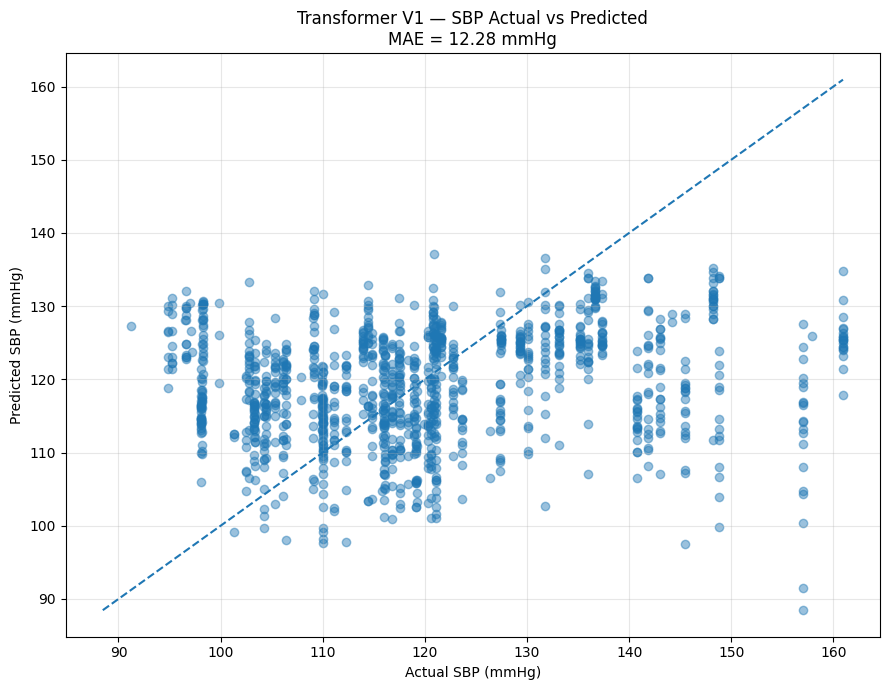

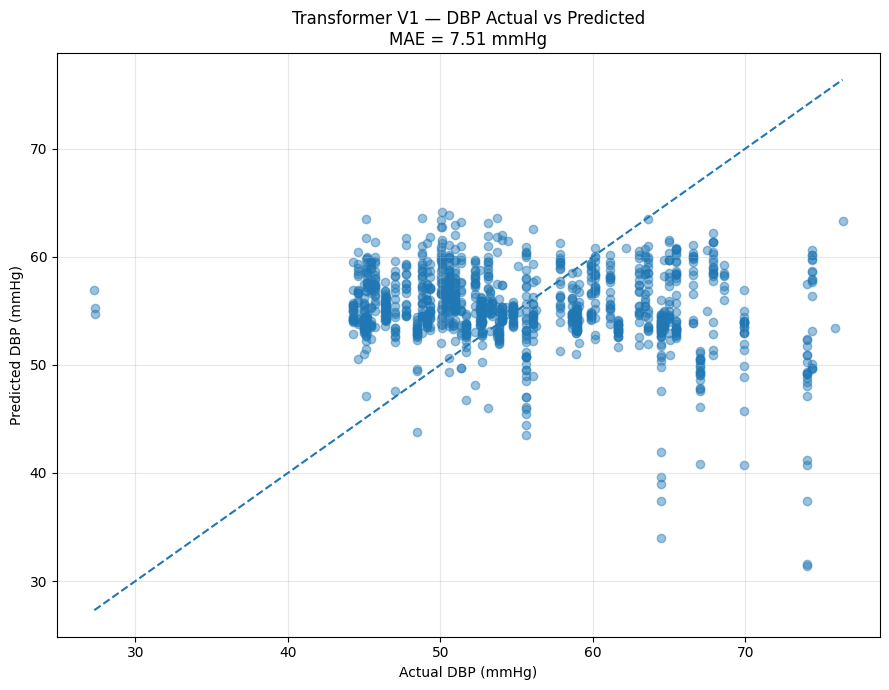

V1 PLOT DATA SUMMARY
SBP MAE : 12.284 mmHg
DBP MAE : 7.509 mmHg
SBP actual range     : 91.26 → 160.94
SBP predicted range  : 88.46 → 137.09
DBP actual range     : 27.31 → 76.37
DBP predicted range  : 31.44 → 64.13


In [21]:
# ============================================================
# V1 — ACTUAL VS PREDICTED PLOTS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error


# ============================================================
# COLLECT TEST PREDICTIONS AGAIN
# ============================================================

model.eval()

all_predictions = []
all_targets = []

with torch.no_grad():

    for images, targets in test_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        predictions = model(images)

        all_predictions.append(
            predictions.cpu().numpy()
        )

        all_targets.append(
            targets.cpu().numpy()
        )


# ============================================================
# COMBINE BATCHES
# ============================================================

predictions_norm = np.concatenate(
    all_predictions,
    axis=0
)

targets_norm = np.concatenate(
    all_targets,
    axis=0
)


print("Normalized predictions shape:",
      predictions_norm.shape)

print("Normalized targets shape:",
      targets_norm.shape)


# ============================================================
# DENORMALIZE USING TRAINING STATISTICS
# ============================================================

predictions_real = predictions_norm.copy()
targets_real = targets_norm.copy()


predictions_real[:, 0] = (
    predictions_norm[:, 0] * checkpoint["SBP_STD"]
    + checkpoint["SBP_MEAN"]
)

predictions_real[:, 1] = (
    predictions_norm[:, 1] * checkpoint["DBP_STD"]
    + checkpoint["DBP_MEAN"]
)


targets_real[:, 0] = (
    targets_norm[:, 0] * checkpoint["SBP_STD"]
    + checkpoint["SBP_MEAN"]
)

targets_real[:, 1] = (
    targets_norm[:, 1] * checkpoint["DBP_STD"]
    + checkpoint["DBP_MEAN"]
)


# ============================================================
# EXTRACT SBP / DBP
# ============================================================

actual_sbp = targets_real[:, 0]
predicted_sbp = predictions_real[:, 0]

actual_dbp = targets_real[:, 1]
predicted_dbp = predictions_real[:, 1]


# ============================================================
# MAE
# ============================================================

sbp_mae = mean_absolute_error(
    actual_sbp,
    predicted_sbp
)

dbp_mae = mean_absolute_error(
    actual_dbp,
    predicted_dbp
)


# ============================================================
# SBP PLOT
# ============================================================

plt.figure(figsize=(9, 7))

plt.scatter(
    actual_sbp,
    predicted_sbp,
    alpha=0.45
)

minimum = min(
    actual_sbp.min(),
    predicted_sbp.min()
)

maximum = max(
    actual_sbp.max(),
    predicted_sbp.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel(
    "Actual SBP (mmHg)"
)

plt.ylabel(
    "Predicted SBP (mmHg)"
)

plt.title(
    f"Transformer V1 — SBP Actual vs Predicted\n"
    f"MAE = {sbp_mae:.2f} mmHg"
)

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()


# ============================================================
# DBP PLOT
# ============================================================

plt.figure(figsize=(9, 7))

plt.scatter(
    actual_dbp,
    predicted_dbp,
    alpha=0.45
)

minimum = min(
    actual_dbp.min(),
    predicted_dbp.min()
)

maximum = max(
    actual_dbp.max(),
    predicted_dbp.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel(
    "Actual DBP (mmHg)"
)

plt.ylabel(
    "Predicted DBP (mmHg)"
)

plt.title(
    f"Transformer V1 — DBP Actual vs Predicted\n"
    f"MAE = {dbp_mae:.2f} mmHg"
)

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

print("=" * 70)
print("V1 PLOT DATA SUMMARY")
print("=" * 70)

print(
    f"SBP MAE : {sbp_mae:.3f} mmHg"
)

print(
    f"DBP MAE : {dbp_mae:.3f} mmHg"
)

print(
    f"SBP actual range     : "
    f"{actual_sbp.min():.2f} → {actual_sbp.max():.2f}"
)

print(
    f"SBP predicted range  : "
    f"{predicted_sbp.min():.2f} → {predicted_sbp.max():.2f}"
)

print(
    f"DBP actual range     : "
    f"{actual_dbp.min():.2f} → {actual_dbp.max():.2f}"
)

print(
    f"DBP predicted range  : "
    f"{predicted_dbp.min():.2f} → {predicted_dbp.max():.2f}"
)

In [22]:
# ============================================
# CELL 6 — VISION TRANSFORMER FOR BP ESTIMATION
# ============================================

class BPTransformer(nn.Module):

    def __init__(
        self,
        image_size=224,
        patch_size=16,
        in_channels=3,
        embed_dim=256,
        num_heads=8,
        num_layers=6,
        dropout=0.1
    ):
        super().__init__()

        # Number of patches
        self.num_patches = (image_size // patch_size) ** 2

        # Convert image patches into embeddings
        self.patch_embedding = nn.Conv2d(
            in_channels=in_channels,
            out_channels=embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        # CLS token
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, embed_dim)
        )

        # Positional embeddings
        self.pos_embedding = nn.Parameter(
            torch.zeros(
                1,
                self.num_patches + 1,
                embed_dim
            )
        )

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # Final normalization
        self.norm = nn.LayerNorm(embed_dim)

        # BP regression head
        self.regressor = nn.Sequential(
            nn.Linear(embed_dim, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, 2)
        )

        # Initialization
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embedding, std=0.02)

    def forward(self, x):

        # x:
        # [batch, 3, 224, 224]

        x = self.patch_embedding(x)

        # [batch, embed_dim, 14, 14]

        x = x.flatten(2)

        # [batch, embed_dim, 196]

        x = x.transpose(1, 2)

        # [batch, 196, embed_dim]

        batch_size = x.size(0)

        # Create CLS token for this batch
        cls_tokens = self.cls_token.expand(
            batch_size,
            -1,
            -1
        )

        # Add CLS token
        x = torch.cat(
            [cls_tokens, x],
            dim=1
        )

        # Add positional information
        x = x + self.pos_embedding

        # Transformer
        x = self.transformer(x)

        # Take CLS token
        x = x[:, 0]

        # Normalize
        x = self.norm(x)

        # Predict SBP and DBP
        output = self.regressor(x)

        return output

In [23]:
# ============================================================
# CELL 8 — ATTENTION ROLLOUT
# ============================================================

def attention_rollout(attentions):

    # Start with identity matrix
    num_tokens = attentions[0].shape[-1]

    rollout = torch.eye(num_tokens)

    for attention in attentions:

        # Average across attention heads
        attention = attention.mean(dim=1)[0]

        # Add residual connection
        attention = attention + torch.eye(
            num_tokens
        )

        # Normalize rows
        attention = attention / attention.sum(
            dim=-1,
            keepdim=True
        )

        # Multiply attention matrices
        rollout = torch.matmul(
            attention,
            rollout
        )

    return rollout


print("Attention rollout function ready.")

Attention rollout function ready.


In [24]:
# ============================================================
# CELL 9 — SELECT TEST IMAGE
# ============================================================

model.eval()

images, targets = next(iter(test_loader))

images = images.to(
    DEVICE,
    non_blocking=True
)

targets = targets.to(
    DEVICE,
    non_blocking=True
)

print("Image shape :", images.shape)
print("Target shape:", targets.shape)
print("Device      :", images.device)

Image shape : torch.Size([32, 3, 224, 224])
Target shape: torch.Size([32, 2])
Device      : cuda:0


In [25]:
# ============================================================
# XAI CELL — TRANSFORMER ATTENTION EXTRACTION
# ============================================================

def get_transformer_attention(model, x):

    model.eval()

    attentions = []

    # We need gradients OFF because this is only
    # extracting attention weights.
    with torch.no_grad():

        # ----------------------------------------------------
        # 1. Patch embedding
        # ----------------------------------------------------

        x = model.patch_embedding(x)

        # [B, 256, 14, 14]

        x = x.flatten(2)

        # [B, 256, 196]

        x = x.transpose(1, 2)

        # [B, 196, 256]

        batch_size = x.size(0)

        # ----------------------------------------------------
        # 2. CLS token
        # ----------------------------------------------------

        cls_tokens = model.cls_token.expand(
            batch_size,
            -1,
            -1
        )

        x = torch.cat(
            [cls_tokens, x],
            dim=1
        )

        # [B, 197, 256]

        # ----------------------------------------------------
        # 3. Positional embedding
        # ----------------------------------------------------

        x = x + model.pos_embedding

        # ----------------------------------------------------
        # 4. Extract attention from all 6 layers
        # ----------------------------------------------------

        for layer in model.transformer.layers:

            # Your model uses norm_first=True
            x_norm = layer.norm1(x)

            attn_output, attn_weights = layer.self_attn(
                x_norm,
                x_norm,
                x_norm,
                need_weights=True,
                average_attn_weights=False
            )

            # Shape:
            # [B, 8, 197, 197]

            attentions.append(
                attn_weights.detach().cpu()
            )

            # ------------------------------------------------
            # Residual connection
            # ------------------------------------------------

            x = x + layer.dropout1(attn_output)

            # ------------------------------------------------
            # Feed-forward network
            # ------------------------------------------------

            x_norm = layer.norm2(x)

            ff_output = layer.linear2(
                layer.dropout(
                    layer.activation(
                        layer.linear1(x_norm)
                    )
                )
            )

            x = x + layer.dropout2(ff_output)

    return attentions


print("=" * 60)
print("TRANSFORMER ATTENTION FUNCTION READY")
print("=" * 60)

TRANSFORMER ATTENTION FUNCTION READY


In [26]:
# ============================================================
# XAI CELL — GENERATE TRANSFORMER ATTENTION
# ============================================================

model.eval()

# First test image
sample_image = images[0:1]

sample_target_norm = (
    targets[0]
    .detach()
    .cpu()
    .numpy()
)

# ------------------------------------------------------------
# Prediction
# ------------------------------------------------------------

with torch.no_grad():

    sample_prediction_norm = model(
        sample_image
    )

sample_prediction_norm = (
    sample_prediction_norm[0]
    .detach()
    .cpu()
    .numpy()
)

# ------------------------------------------------------------
# Convert normalized values back to mmHg
# ------------------------------------------------------------

actual_sbp = (
    sample_target_norm[0] *
    checkpoint["SBP_STD"]
    + checkpoint["SBP_MEAN"]
)

actual_dbp = (
    sample_target_norm[1] *
    checkpoint["DBP_STD"]
    + checkpoint["DBP_MEAN"]
)

predicted_sbp = (
    sample_prediction_norm[0] *
    checkpoint["SBP_STD"]
    + checkpoint["SBP_MEAN"]
)

predicted_dbp = (
    sample_prediction_norm[1] *
    checkpoint["DBP_STD"]
    + checkpoint["DBP_MEAN"]
)

print("=" * 60)
print("SAMPLE BP PREDICTION")
print("=" * 60)

print(f"Actual SBP    : {actual_sbp:.2f} mmHg")
print(f"Predicted SBP : {predicted_sbp:.2f} mmHg")

print()

print(f"Actual DBP    : {actual_dbp:.2f} mmHg")
print(f"Predicted DBP : {predicted_dbp:.2f} mmHg")


# ------------------------------------------------------------
# Extract Transformer attention
# ------------------------------------------------------------

attentions = get_transformer_attention(
    model,
    sample_image
)

print()
print("=" * 60)
print("TRANSFORMER ATTENTION")
print("=" * 60)

print(
    "Number of Transformer layers:",
    len(attentions)
)

print(
    "Attention shape:",
    attentions[0].shape
)

SAMPLE BP PREDICTION
Actual SBP    : 105.31 mmHg
Predicted SBP : 119.14 mmHg

Actual DBP    : 54.06 mmHg
Predicted DBP : 55.36 mmHg

TRANSFORMER ATTENTION
Number of Transformer layers: 6
Attention shape: torch.Size([1, 8, 197, 197])


In [27]:
# ============================================================
# XAI CELL — ATTENTION ROLLOUT
# ============================================================

def attention_rollout(attentions):

    # Number of tokens
    num_tokens = attentions[0].shape[-1]

    # Start with identity matrix
    rollout = torch.eye(
        num_tokens,
        dtype=torch.float32
    )

    # Process every Transformer layer
    for attention in attentions:

        # Average attention across 8 heads
        attention = attention.mean(
            dim=1
        )[0]

        # Add residual connection
        attention = (
            attention +
            torch.eye(
                num_tokens,
                dtype=attention.dtype
            )
        )

        # Normalize each row
        attention = attention / (
            attention.sum(
                dim=-1,
                keepdim=True
            ) + 1e-8
        )

        # Combine with previous layers
        rollout = torch.matmul(
            attention,
            rollout
        )

    return rollout


# ============================================================
# GENERATE ROLLOUT
# ============================================================

rollout = attention_rollout(
    attentions
)

print("=" * 60)
print("ATTENTION ROLLOUT")
print("=" * 60)

print(
    "Rollout shape:",
    rollout.shape
)

# CLS token → image patches
cls_attention = rollout[0, 1:]

print(
    "CLS attention shape:",
    cls_attention.shape
)

# 196 patches = 14 × 14
attention_map = cls_attention.reshape(
    14,
    14
).numpy()

# Normalize to 0–1
attention_map = (
    attention_map -
    attention_map.min()
)

attention_map = (
    attention_map /
    (attention_map.max() + 1e-8)
)

print(
    "Attention map shape:",
    attention_map.shape
)

print(
    "Attention range:",
    f"{attention_map.min():.4f}",
    "→",
    f"{attention_map.max():.4f}"
)

ATTENTION ROLLOUT
Rollout shape: torch.Size([197, 197])
CLS attention shape: torch.Size([196])
Attention map shape: (14, 14)
Attention range: 0.0000 → 1.0000


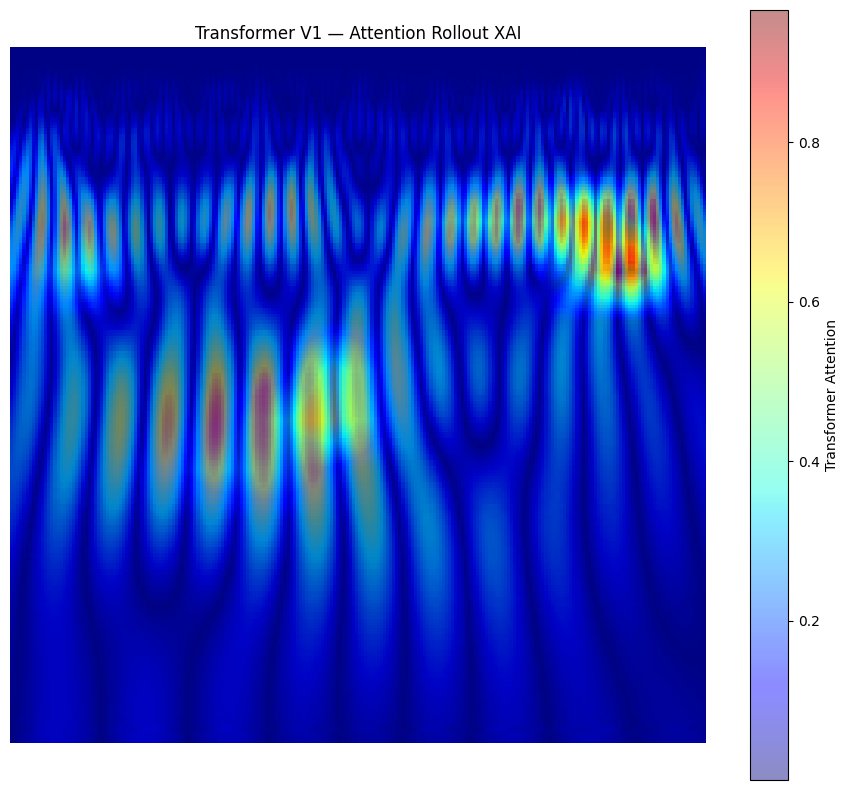

In [28]:
# ============================================================
# XAI CELL — TRANSFORMER ATTENTION HEATMAP
# ============================================================

import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np


# ------------------------------------------------------------
# Resize 14 × 14 attention map → 224 × 224
# ------------------------------------------------------------

attention_tensor = torch.tensor(
    attention_map,
    dtype=torch.float32
).unsqueeze(0).unsqueeze(0)

attention_resized = F.interpolate(
    attention_tensor,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

attention_resized = (
    attention_resized[0, 0]
    .numpy()
)


# ------------------------------------------------------------
# Prepare original scalogram image
# ------------------------------------------------------------

image_np = (
    sample_image[0]
    .detach()
    .cpu()
    .permute(1, 2, 0)
    .numpy()
)

# Normalize image only for visualization
image_np = (
    image_np - image_np.min()
)

image_np = (
    image_np /
    (image_np.max() + 1e-8)
)


# ------------------------------------------------------------
# Create overlay
# ------------------------------------------------------------

plt.figure(figsize=(9, 8))

plt.imshow(
    image_np
)

plt.imshow(
    attention_resized,
    cmap="jet",
    alpha=0.45
)

plt.colorbar(
    label="Transformer Attention"
)

plt.title(
    "Transformer V1 — Attention Rollout XAI"
)

plt.axis("off")

plt.tight_layout()

plt.show()

In [29]:
# ============================================================
# XAI — SBP / DBP OUTPUT-SPECIFIC GRADIENT MAP
# ============================================================

model.eval()

# Make a copy that allows gradients
xai_image = sample_image.clone().detach()
xai_image.requires_grad_(True)

# Forward pass
output = model(xai_image)

# ------------------------------------------------------------
# SBP attribution
# ------------------------------------------------------------

model.zero_grad()

sbp_output = output[0, 0]

sbp_output.backward(
    retain_graph=True
)

sbp_gradient = xai_image.grad.detach().clone()

# Reset gradients
xai_image.grad.zero_()

# ------------------------------------------------------------
# DBP attribution
# ------------------------------------------------------------

dbp_output = output[0, 1]

dbp_output.backward()

dbp_gradient = xai_image.grad.detach().clone()


# ============================================================
# CONVERT GRADIENTS INTO SPATIAL IMPORTANCE
# ============================================================

# Average absolute gradient across RGB channels

sbp_map = sbp_gradient.abs().mean(
    dim=1
)[0]

dbp_map = dbp_gradient.abs().mean(
    dim=1
)[0]


# Normalize
sbp_map = (
    sbp_map -
    sbp_map.min()
) / (
    sbp_map.max() -
    sbp_map.min() +
    1e-8
)

dbp_map = (
    dbp_map -
    dbp_map.min()
) / (
    dbp_map.max() -
    dbp_map.min() +
    1e-8
)


print("=" * 60)
print("OUTPUT-SPECIFIC XAI")
print("=" * 60)

print("SBP attribution shape:", sbp_map.shape)
print("DBP attribution shape:", dbp_map.shape)

OUTPUT-SPECIFIC XAI
SBP attribution shape: torch.Size([224, 224])
DBP attribution shape: torch.Size([224, 224])


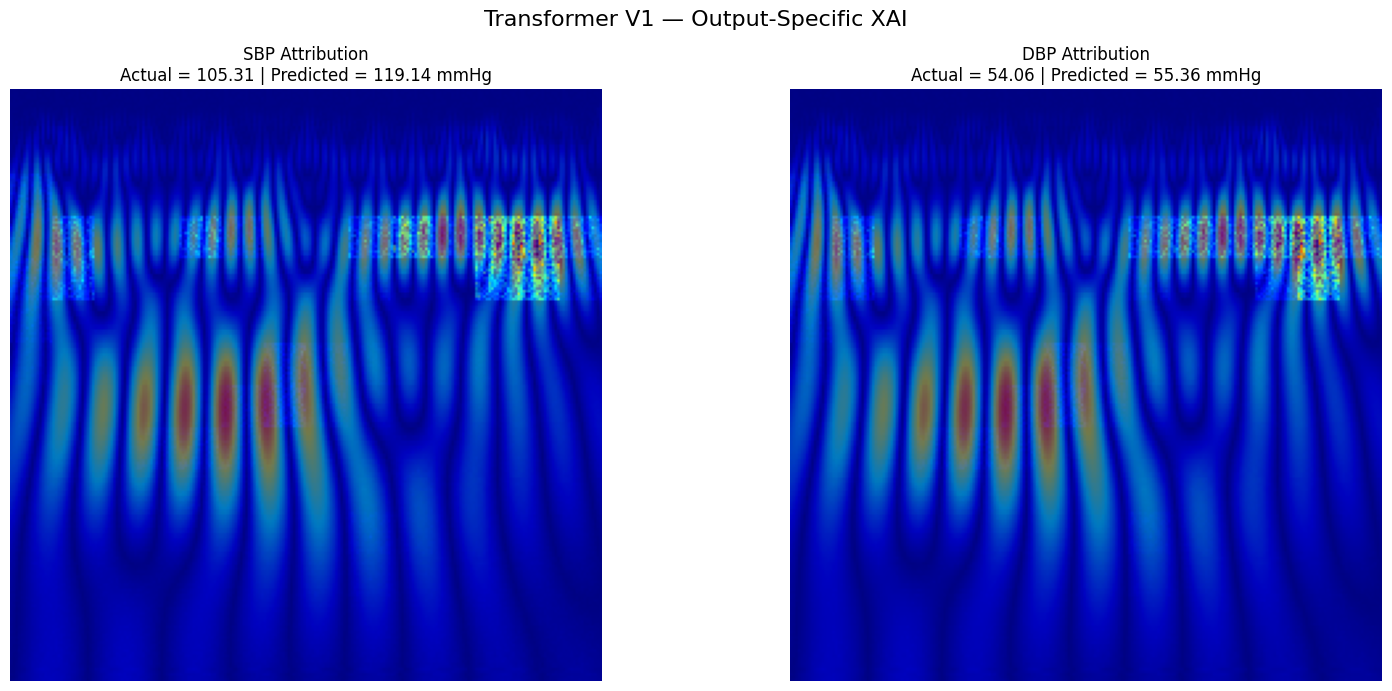

In [30]:
# ============================================================
# XAI — SBP vs DBP ATTRIBUTION MAPS
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 7)
)

# ------------------------------------------------------------
# SBP
# ------------------------------------------------------------

axes[0].imshow(
    image_np
)

axes[0].imshow(
    sbp_map.detach().cpu().numpy(),
    cmap="jet",
    alpha=0.50
)

axes[0].set_title(
    f"SBP Attribution\n"
    f"Actual = {actual_sbp:.2f} | "
    f"Predicted = {predicted_sbp:.2f} mmHg"
)

axes[0].axis("off")


# ------------------------------------------------------------
# DBP
# ------------------------------------------------------------

axes[1].imshow(
    image_np
)

axes[1].imshow(
    dbp_map.detach().cpu().numpy(),
    cmap="jet",
    alpha=0.50
)

axes[1].set_title(
    f"DBP Attribution\n"
    f"Actual = {actual_dbp:.2f} | "
    f"Predicted = {predicted_dbp:.2f} mmHg"
)

axes[1].axis("off")


plt.suptitle(
    "Transformer V1 — Output-Specific XAI",
    fontsize=16
)

plt.tight_layout()

plt.show()

In [31]:
# ============================================================
# V1 — SAVE FINAL TRANSFORMER + CONFIGURATION
# ============================================================

import os
import json
import torch

SAVE_DIR = "/content/drive/MyDrive/BP_Project/V1_Final"

os.makedirs(SAVE_DIR, exist_ok=True)

# ------------------------------------------------------------
# Save model checkpoint
# ------------------------------------------------------------

v1_checkpoint = {
    "model_state_dict": model.state_dict(),

    "SBP_MEAN": float(checkpoint["SBP_MEAN"]),
    "SBP_STD": float(checkpoint["SBP_STD"]),

    "DBP_MEAN": float(checkpoint["DBP_MEAN"]),
    "DBP_STD": float(checkpoint["DBP_STD"]),

    "val_loss": float(checkpoint["val_loss"]),

    "model_config": {
        "image_size": 224,
        "patch_size": 16,
        "in_channels": 3,
        "embed_dim": 256,
        "num_heads": 8,
        "num_layers": 6,
        "dropout": 0.1
    }
}

MODEL_PATH = os.path.join(
    SAVE_DIR,
    "transformer_v1_final.pth"
)

torch.save(
    v1_checkpoint,
    MODEL_PATH
)


# ------------------------------------------------------------
# Save configuration separately
# ------------------------------------------------------------

CONFIG_PATH = os.path.join(
    SAVE_DIR,
    "transformer_v1_config.json"
)

with open(CONFIG_PATH, "w") as f:

    json.dump(
        v1_checkpoint["model_config"],
        f,
        indent=4
    )


print("=" * 60)
print("TRANSFORMER V1 SAVED")
print("=" * 60)

print("Model:")
print(MODEL_PATH)

print()

print("Configuration:")
print(CONFIG_PATH)

print()

print("SBP mean :", v1_checkpoint["SBP_MEAN"])
print("SBP std  :", v1_checkpoint["SBP_STD"])

print("DBP mean :", v1_checkpoint["DBP_MEAN"])
print("DBP std  :", v1_checkpoint["DBP_STD"])

print()

print("Validation loss:",
      v1_checkpoint["val_loss"])

TRANSFORMER V1 SAVED
Model:
/content/drive/MyDrive/BP_Project/V1_Final/transformer_v1_final.pth

Configuration:
/content/drive/MyDrive/BP_Project/V1_Final/transformer_v1_config.json

SBP mean : 122.30485693861299
SBP std  : 21.051077265426123
DBP mean : 52.26174578326336
DBP std  : 11.949080997790393

Validation loss: 0.48459905939819536


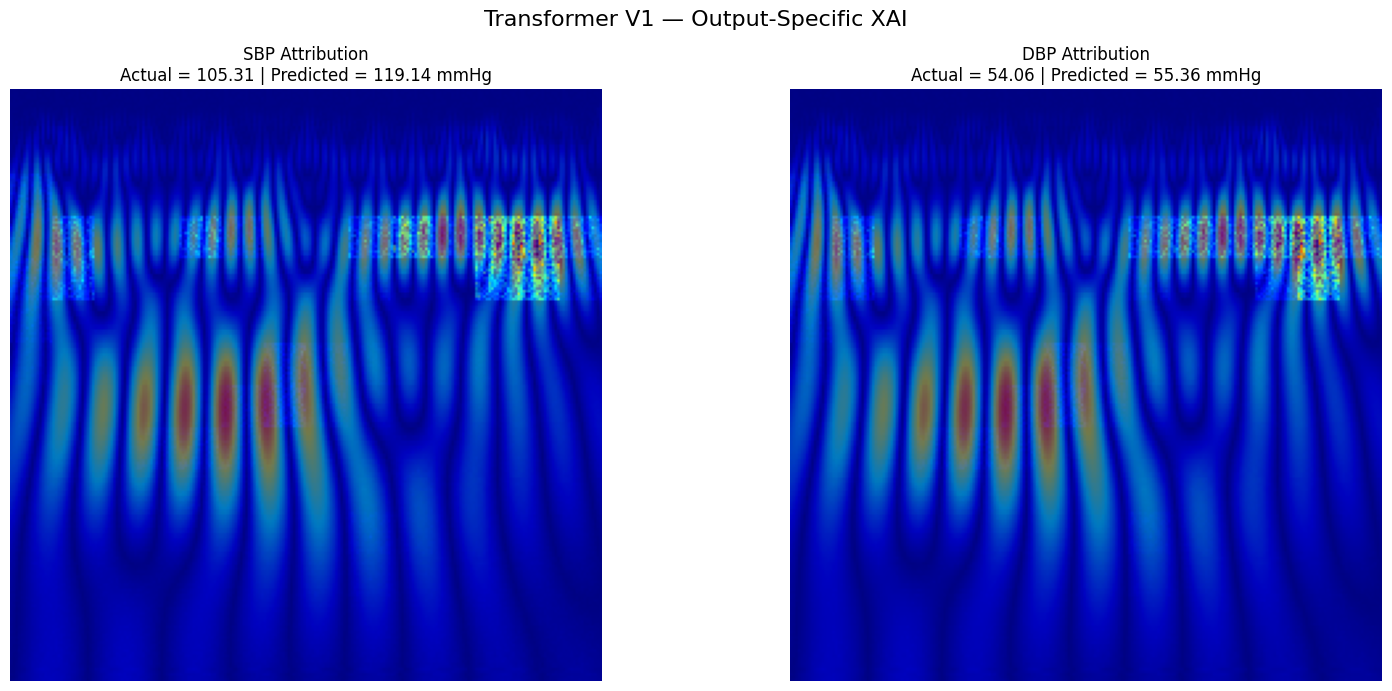

V1 RESULTS + XAI ARTIFACTS SAVED

Results:
/content/drive/MyDrive/BP_Project/V1_Final/transformer_v1_results.json

Attention rollout:
/content/drive/MyDrive/BP_Project/V1_Final/transformer_v1_attention_rollout.npy

SBP XAI:
/content/drive/MyDrive/BP_Project/V1_Final/transformer_v1_sbp_xai.npy

DBP XAI:
/content/drive/MyDrive/BP_Project/V1_Final/transformer_v1_dbp_xai.npy

XAI visualization:
/content/drive/MyDrive/BP_Project/V1_Final/transformer_v1_output_specific_xai.png

V1 EXPERIMENT BACKUP COMPLETE


In [32]:
# ============================================================
# V1 — SAVE RESULTS AND XAI ARTIFACTS
# ============================================================

import os
import json
import numpy as np
import matplotlib.pyplot as plt

RESULTS_DIR = "/content/drive/MyDrive/BP_Project/V1_Final"

os.makedirs(RESULTS_DIR, exist_ok=True)


# ============================================================
# 1. SAVE TEST METRICS
# ============================================================

v1_results = {
    "model": "Transformer V1",

    "SBP": {
        "MAE_mmHg": 11.703,
        "RMSE_mmHg": 14.994,
        "Correlation": 0.2529,
        "Bias_mmHg": 0.507
    },

    "DBP": {
        "MAE_mmHg": 7.572,
        "RMSE_mmHg": 9.618,
        "Correlation": -0.1867,
        "Bias_mmHg": -0.798
    },

    "prediction_variability": {
        "SBP_std_ratio": 0.374,
        "DBP_std_ratio": 0.504
    }
}


RESULTS_PATH = os.path.join(
    RESULTS_DIR,
    "transformer_v1_results.json"
)

with open(RESULTS_PATH, "w") as f:
    json.dump(
        v1_results,
        f,
        indent=4
    )


# ============================================================
# 2. SAVE ATTENTION ROLLOUT MAP
# ============================================================

ATTENTION_PATH = os.path.join(
    RESULTS_DIR,
    "transformer_v1_attention_rollout.npy"
)

np.save(
    ATTENTION_PATH,
    attention_map
)


# ============================================================
# 3. SAVE SBP ATTRIBUTION MAP
# ============================================================

SBP_XAI_PATH = os.path.join(
    RESULTS_DIR,
    "transformer_v1_sbp_xai.npy"
)

np.save(
    SBP_XAI_PATH,
    sbp_map.detach().cpu().numpy()
)


# ============================================================
# 4. SAVE DBP ATTRIBUTION MAP
# ============================================================

DBP_XAI_PATH = os.path.join(
    RESULTS_DIR,
    "transformer_v1_dbp_xai.npy"
)

np.save(
    DBP_XAI_PATH,
    dbp_map.detach().cpu().numpy()
)


# ============================================================
# 5. SAVE XAI IMAGE
# ============================================================

XAI_IMAGE_PATH = os.path.join(
    RESULTS_DIR,
    "transformer_v1_output_specific_xai.png"
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 7)
)

axes[0].imshow(image_np)
axes[0].imshow(
    sbp_map.detach().cpu().numpy(),
    cmap="jet",
    alpha=0.50
)

axes[0].set_title(
    f"SBP Attribution\n"
    f"Actual = {actual_sbp:.2f} | "
    f"Predicted = {predicted_sbp:.2f} mmHg"
)

axes[0].axis("off")


axes[1].imshow(image_np)
axes[1].imshow(
    dbp_map.detach().cpu().numpy(),
    cmap="jet",
    alpha=0.50
)

axes[1].set_title(
    f"DBP Attribution\n"
    f"Actual = {actual_dbp:.2f} | "
    f"Predicted = {predicted_dbp:.2f} mmHg"
)

axes[1].axis("off")


plt.suptitle(
    "Transformer V1 — Output-Specific XAI",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    XAI_IMAGE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# COMPLETE
# ============================================================

print("=" * 65)
print("V1 RESULTS + XAI ARTIFACTS SAVED")
print("=" * 65)

print()
print("Results:")
print(RESULTS_PATH)

print()
print("Attention rollout:")
print(ATTENTION_PATH)

print()
print("SBP XAI:")
print(SBP_XAI_PATH)

print()
print("DBP XAI:")
print(DBP_XAI_PATH)

print()
print("XAI visualization:")
print(XAI_IMAGE_PATH)

print()
print("V1 EXPERIMENT BACKUP COMPLETE")

In [34]:
# ============================================================
# CHECK TEST LABELS DIRECTLY
# ============================================================

print("=" * 70)
print("CHECKING TEST LABEL PIPELINE")
print("=" * 70)

print("\n1. TEST DATAFRAME")
print("-" * 50)

print("test_df shape:", test_df.shape)

print("\nFirst 10 SBP labels:")
print(test_df["SBP_label"].head(10).to_list())

print("\nFirst 10 DBP labels:")
print(test_df["DBP_label"].head(10).to_list())

print("\nUnique SBP values:", test_df["SBP_label"].nunique())
print("Unique DBP values:", test_df["DBP_label"].nunique())

print("\nSBP range:")
print(test_df["SBP_label"].min(), "->", test_df["SBP_label"].max())

print("\nDBP range:")
print(test_df["DBP_label"].min(), "->", test_df["DBP_label"].max())


# ============================================================
# CHECK RAW DATASET
# ============================================================

print("\n\n2. RAW TEST DATASET")
print("-" * 50)

for i in [0, 1, 2, 10, 100, 500, 1000]:

    image, target = test_dataset[i]

    print(
        f"Index {i:4d} | "
        f"SBP = {target[0].item():.3f} | "
        f"DBP = {target[1].item():.3f}"
    )


# ============================================================
# CHECK NORMALIZED DATASET
# ============================================================

print("\n\n3. NORMALIZED TEST DATASET")
print("-" * 50)

for i in [0, 1, 2, 10, 100, 500, 1000]:

    image, target = test_dataset_norm[i]

    print(
        f"Index {i:4d} | "
        f"SBP_norm = {target[0].item():.4f} | "
        f"DBP_norm = {target[1].item():.4f}"
    )


# ============================================================
# CHECK TEST LOADER
# ============================================================

print("\n\n4. TEST LOADER")
print("-" * 50)

images, targets = next(iter(test_loader))

print("Batch image shape :", images.shape)
print("Batch target shape:", targets.shape)

print("\nFirst 10 loader targets:")

for i in range(min(10, len(targets))):

    print(
        f"{i:2d} | "
        f"SBP_norm = {targets[i,0].item():.4f} | "
        f"DBP_norm = {targets[i,1].item():.4f}"
    )

print("\n" + "=" * 70)
print("LABEL PIPELINE CHECK COMPLETE")
print("=" * 70)

CHECKING TEST LABEL PIPELINE

1. TEST DATAFRAME
--------------------------------------------------
test_df shape: (1190, 18)

First 10 SBP labels:
[105.3125, 105.3125, 105.3125, 105.3125, 105.3125, 105.3125, 105.3125, 105.3125, 105.3125, 105.3125]

First 10 DBP labels:
[54.0625, 54.0625, 54.0625, 54.0625, 54.0625, 54.0625, 54.0625, 54.0625, 54.0625, 54.0625]

Unique SBP values: 78
Unique DBP values: 74

SBP range:
91.25625 -> 160.9375

DBP range:
27.3125 -> 76.36875


2. RAW TEST DATASET
--------------------------------------------------
Index    0 | SBP = 105.312 | DBP = 54.062
Index    1 | SBP = 105.312 | DBP = 54.062
Index    2 | SBP = 105.312 | DBP = 54.062
Index   10 | SBP = 105.312 | DBP = 54.062
Index  100 | SBP = 98.062 | DBP = 50.375
Index  500 | SBP = 116.000 | DBP = 57.875
Index 1000 | SBP = 121.062 | DBP = 64.438


3. NORMALIZED TEST DATASET
--------------------------------------------------
Index    0 | SBP_norm = -0.8072 | DBP_norm = 0.1507
Index    1 | SBP_norm = -0.8072

In [35]:
# ============================================================
# FRESH TEST LOADER — FINAL PIPELINE CHECK
# ============================================================

from torch.utils.data import DataLoader

print("=" * 75)
print("CREATING FRESH TEST LOADER")
print("=" * 75)


# ------------------------------------------------------------
# 1. CREATE A BRAND-NEW LOADER FROM CURRENT NORMALIZED DATASET
# ------------------------------------------------------------

diagnostic_test_loader = DataLoader(
    test_dataset_norm,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


# ------------------------------------------------------------
# 2. CHECK FIRST BATCH
# ------------------------------------------------------------

diag_images, diag_targets = next(
    iter(diagnostic_test_loader)
)

print("\nFirst batch:")
print("Images :", diag_images.shape)
print("Targets:", diag_targets.shape)

print("\nFirst 10 targets:")

for i in range(10):

    print(
        f"{i:2d} | "
        f"SBP_norm = {diag_targets[i,0].item():.4f} | "
        f"DBP_norm = {diag_targets[i,1].item():.4f}"
    )


# ------------------------------------------------------------
# 3. COLLECT ALL TARGETS FROM FRESH LOADER
# ------------------------------------------------------------

fresh_targets = []

with torch.no_grad():

    for _, targets in diagnostic_test_loader:

        fresh_targets.append(
            targets.numpy()
        )

fresh_targets = np.concatenate(
    fresh_targets,
    axis=0
)


# ------------------------------------------------------------
# 4. DENORMALIZE TARGETS
# ------------------------------------------------------------

fresh_actual_sbp = (
    fresh_targets[:, 0]
    * checkpoint["SBP_STD"]
    + checkpoint["SBP_MEAN"]
)

fresh_actual_dbp = (
    fresh_targets[:, 1]
    * checkpoint["DBP_STD"]
    + checkpoint["DBP_MEAN"]
)


# ------------------------------------------------------------
# 5. FINAL TARGET CHECK
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FRESH LOADER TARGET STATISTICS")
print("=" * 75)

print("\nNumber of samples:", len(fresh_targets))

print("\nSBP")
print("Mean :", fresh_actual_sbp.mean())
print("Std  :", fresh_actual_sbp.std())
print("Min  :", fresh_actual_sbp.min())
print("Max  :", fresh_actual_sbp.max())

print("\nDBP")
print("Mean :", fresh_actual_dbp.mean())
print("Std  :", fresh_actual_dbp.std())
print("Min  :", fresh_actual_dbp.min())
print("Max  :", fresh_actual_dbp.max())


# ------------------------------------------------------------
# 6. COMPARE WITH test_df
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("COMPARISON WITH TEST CSV")
print("=" * 75)

print("\nCSV SBP range:")
print(
    test_df["SBP_label"].min(),
    "->",
    test_df["SBP_label"].max()
)

print("Loader SBP range:")
print(
    fresh_actual_sbp.min(),
    "->",
    fresh_actual_sbp.max()
)

print("\nCSV DBP range:")
print(
    test_df["DBP_label"].min(),
    "->",
    test_df["DBP_label"].max()
)

print("Loader DBP range:")
print(
    fresh_actual_dbp.min(),
    "->",
    fresh_actual_dbp.max()
)


# ------------------------------------------------------------
# 7. CHECK WHETHER LOADER IS CORRECT
# ------------------------------------------------------------

sbp_ok = np.allclose(
    np.sort(fresh_actual_sbp),
    np.sort(test_df["SBP_label"].values),
    atol=1e-4
)

dbp_ok = np.allclose(
    np.sort(fresh_actual_dbp),
    np.sort(test_df["DBP_label"].values),
    atol=1e-4
)

print("\n" + "=" * 75)

print("SBP loader matches CSV:", sbp_ok)
print("DBP loader matches CSV:", dbp_ok)

print("=" * 75)

CREATING FRESH TEST LOADER

First batch:
Images : torch.Size([32, 3, 224, 224])
Targets: torch.Size([32, 2])

First 10 targets:
 0 | SBP_norm = -0.8072 | DBP_norm = 0.1507
 1 | SBP_norm = -0.8072 | DBP_norm = 0.1507
 2 | SBP_norm = -0.8072 | DBP_norm = 0.1507
 3 | SBP_norm = -0.8072 | DBP_norm = 0.1507
 4 | SBP_norm = -0.8072 | DBP_norm = 0.1507
 5 | SBP_norm = -0.8072 | DBP_norm = 0.1507
 6 | SBP_norm = -0.8072 | DBP_norm = 0.1507
 7 | SBP_norm = -0.8072 | DBP_norm = 0.1507
 8 | SBP_norm = -0.8072 | DBP_norm = 0.1507
 9 | SBP_norm = -0.8072 | DBP_norm = 0.1507

FRESH LOADER TARGET STATISTICS

Number of samples: 1190

SBP
Mean : 120.0310836232394
Std  : 15.368854460894545
Min  : 91.25625006605439
Max  : 160.9375015919333

DBP
Mean : 55.39018417080218
Std  : 7.9798573431861834
Min  : 27.312498423033865
Max  : 76.36875185626141

COMPARISON WITH TEST CSV

CSV SBP range:
91.25625 -> 160.9375
Loader SBP range:
91.25625006605439 -> 160.9375015919333

CSV DBP range:
27.3125 -> 76.36875
Loader

In [36]:
# ============================================================
# FINAL V1 EVALUATION — FRESH TEST LOADER
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.stats import pearsonr

print("=" * 75)
print("FINAL V1 TRANSFORMER EVALUATION")
print("=" * 75)


# ------------------------------------------------------------
# 1. LOAD BEST V1 CHECKPOINT
# ------------------------------------------------------------

v1_checkpoint_path = "/content/best_transformer_bp_model.pth"

v1_checkpoint = torch.load(
    v1_checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    v1_checkpoint["model_state_dict"]
)

model.to(DEVICE)
model.eval()

print("\nBest V1 checkpoint loaded.")
print(
    "Best validation loss:",
    v1_checkpoint["val_loss"]
)


# ------------------------------------------------------------
# 2. FRESH PREDICTIONS
# ------------------------------------------------------------

v1_pred_batches = []
v1_target_batches = []

with torch.no_grad():

    for v1_images, v1_targets in diagnostic_test_loader:

        v1_images = v1_images.to(
            DEVICE,
            non_blocking=True
        )

        v1_outputs = model(v1_images)

        v1_pred_batches.append(
            v1_outputs.cpu().numpy()
        )

        v1_target_batches.append(
            v1_targets.numpy()
        )


v1_predictions_norm = np.concatenate(
    v1_pred_batches,
    axis=0
)

v1_targets_norm = np.concatenate(
    v1_target_batches,
    axis=0
)


print("\nSamples evaluated:", len(v1_targets_norm))
print(
    "Prediction shape:",
    v1_predictions_norm.shape
)
print(
    "Target shape:",
    v1_targets_norm.shape
)


# ------------------------------------------------------------
# 3. DENORMALIZE
# ------------------------------------------------------------

v1_predictions_real = v1_predictions_norm.copy()
v1_targets_real = v1_targets_norm.copy()


v1_predictions_real[:, 0] = (
    v1_predictions_norm[:, 0]
    * v1_checkpoint["SBP_STD"]
    + v1_checkpoint["SBP_MEAN"]
)

v1_predictions_real[:, 1] = (
    v1_predictions_norm[:, 1]
    * v1_checkpoint["DBP_STD"]
    + v1_checkpoint["DBP_MEAN"]
)


v1_targets_real[:, 0] = (
    v1_targets_norm[:, 0]
    * v1_checkpoint["SBP_STD"]
    + v1_checkpoint["SBP_MEAN"]
)

v1_targets_real[:, 1] = (
    v1_targets_norm[:, 1]
    * v1_checkpoint["DBP_STD"]
    + v1_checkpoint["DBP_MEAN"]
)


# ------------------------------------------------------------
# 4. SEPARATE SBP / DBP
# ------------------------------------------------------------

v1_actual_sbp = v1_targets_real[:, 0]
v1_pred_sbp = v1_predictions_real[:, 0]

v1_actual_dbp = v1_targets_real[:, 1]
v1_pred_dbp = v1_predictions_real[:, 1]


# ------------------------------------------------------------
# 5. METRICS
# ------------------------------------------------------------

def v1_metrics(actual, predicted):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    correlation = pearsonr(
        actual,
        predicted
    )[0]

    bias = np.mean(
        predicted - actual
    )

    return mae, rmse, correlation, bias


sbp_mae, sbp_rmse, sbp_corr, sbp_bias = v1_metrics(
    v1_actual_sbp,
    v1_pred_sbp
)

dbp_mae, dbp_rmse, dbp_corr, dbp_bias = v1_metrics(
    v1_actual_dbp,
    v1_pred_dbp
)


# ------------------------------------------------------------
# 6. RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("V1 TRANSFORMER RESULTS")
print("=" * 75)


print("\nSBP")
print("-" * 45)
print(f"MAE         : {sbp_mae:.3f} mmHg")
print(f"RMSE        : {sbp_rmse:.3f} mmHg")
print(f"Correlation : {sbp_corr:.4f}")
print(f"Bias        : {sbp_bias:.3f} mmHg")


print("\nDBP")
print("-" * 45)
print(f"MAE         : {dbp_mae:.3f} mmHg")
print(f"RMSE        : {dbp_rmse:.3f} mmHg")
print(f"Correlation : {dbp_corr:.4f}")
print(f"Bias        : {dbp_bias:.3f} mmHg")


# ------------------------------------------------------------
# 7. RANGES + VARIABILITY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ACTUAL VS PREDICTED DISTRIBUTION")
print("=" * 75)


print("\nSBP")
print(f"Actual mean       : {v1_actual_sbp.mean():.3f}")
print(f"Predicted mean    : {v1_pred_sbp.mean():.3f}")
print(f"Actual std        : {v1_actual_sbp.std():.3f}")
print(f"Predicted std     : {v1_pred_sbp.std():.3f}")
print(f"Actual range      : {v1_actual_sbp.min():.3f} -> {v1_actual_sbp.max():.3f}")
print(f"Predicted range   : {v1_pred_sbp.min():.3f} -> {v1_pred_sbp.max():.3f}")
print(
    f"Std ratio         : "
    f"{v1_pred_sbp.std() / v1_actual_sbp.std():.3f}"
)


print("\nDBP")
print(f"Actual mean       : {v1_actual_dbp.mean():.3f}")
print(f"Predicted mean    : {v1_pred_dbp.mean():.3f}")
print(f"Actual std        : {v1_actual_dbp.std():.3f}")
print(f"Predicted std     : {v1_pred_dbp.std():.3f}")
print(f"Actual range      : {v1_actual_dbp.min():.3f} -> {v1_actual_dbp.max():.3f}")
print(f"Predicted range   : {v1_pred_dbp.min():.3f} -> {v1_pred_dbp.max():.3f}")
print(
    f"Std ratio         : "
    f"{v1_pred_dbp.std() / v1_actual_dbp.std():.3f}"
)


# ------------------------------------------------------------
# 8. ACTUAL VS PREDICTED TABLE
# ------------------------------------------------------------

v1_results_df = pd.DataFrame({
    "Actual_SBP": v1_actual_sbp,
    "Predicted_SBP": v1_pred_sbp,
    "Actual_DBP": v1_actual_dbp,
    "Predicted_DBP": v1_pred_dbp
})

print("\n" + "=" * 75)
print("FIRST 15 PREDICTIONS")
print("=" * 75)

display(
    v1_results_df.head(15)
)


print("\n" + "=" * 75)
print("FINAL V1 EVALUATION COMPLETE")
print("=" * 75)

FINAL V1 TRANSFORMER EVALUATION

Best V1 checkpoint loaded.
Best validation loss: 0.48459905939819536

Samples evaluated: 1190
Prediction shape: (1190, 2)
Target shape: (1190, 2)

V1 TRANSFORMER RESULTS

SBP
---------------------------------------------
MAE         : 12.284 mmHg
RMSE        : 15.947 mmHg
Correlation : 0.1738
Bias        : -0.925 mmHg

DBP
---------------------------------------------
MAE         : 7.509 mmHg
RMSE        : 9.302 mmHg
Correlation : -0.1891
Bias        : -0.038 mmHg

ACTUAL VS PREDICTED DISTRIBUTION

SBP
Actual mean       : 120.031
Predicted mean    : 119.106
Actual std        : 15.369
Predicted std     : 7.609
Actual range      : 91.256 -> 160.938
Predicted range   : 88.462 -> 137.091
Std ratio         : 0.495

DBP
Actual mean       : 55.390
Predicted mean    : 55.352
Actual std        : 7.980
Predicted std     : 3.504
Actual range      : 27.312 -> 76.369
Predicted range   : 31.437 -> 64.131
Std ratio         : 0.439

FIRST 15 PREDICTIONS


,Actual_SBP,Predicted_SBP,Actual_DBP,Predicted_DBP
0,105.3125,119.141151,54.0625,55.363937
1,105.3125,119.598824,54.0625,54.355202
2,105.3125,111.502617,54.0625,57.381557
3,105.3125,122.337807,54.0625,55.310272
4,105.3125,121.616135,54.0625,54.040272
5,105.3125,116.742287,54.0625,54.442833
6,105.3125,123.639282,54.0625,54.749557
7,105.3125,119.016396,54.0625,54.344650
8,105.3125,128.386566,54.0625,62.033985
9,105.3125,121.670372,54.0625,54.256855



FINAL V1 EVALUATION COMPLETE


TRAIN / VALIDATION BP DISTRIBUTION

TRAIN
--------------------------------------------------
SBP mean : 122.305
SBP std  : 21.051
SBP min  : 29.188
SBP max  : 246.250
DBP mean : 52.262
DBP std  : 11.949
DBP min  : 21.500
DBP max  : 135.625

VALIDATION
--------------------------------------------------
SBP mean : 110.075
SBP std  : 14.243
SBP min  : 75.750
SBP max  : 154.438
DBP mean : 56.590
DBP std  : 10.920
DBP min  : 33.562
DBP max  : 82.688

TEST
--------------------------------------------------
SBP mean : 120.031
SBP std  : 15.375
SBP min  : 91.256
SBP max  : 160.938
DBP mean : 55.390
DBP std  : 7.983
DBP min  : 27.312
DBP max  : 76.369

SBP RANGE DISTRIBUTION
SBP_label
(0, 90]        171
(90, 100]      530
(100, 110]    1322
(110, 120]    1267
(120, 130]    1349
(130, 140]    1371
(140, 150]     462
(150, 160]     234
(160, 200]     129
Name: count, dtype: int64

DBP RANGE DISTRIBUTION
DBP_label
(0, 40]      1090
(40, 50]     1748
(50, 60]     2292
(60, 70]     1323
(70, 80]    

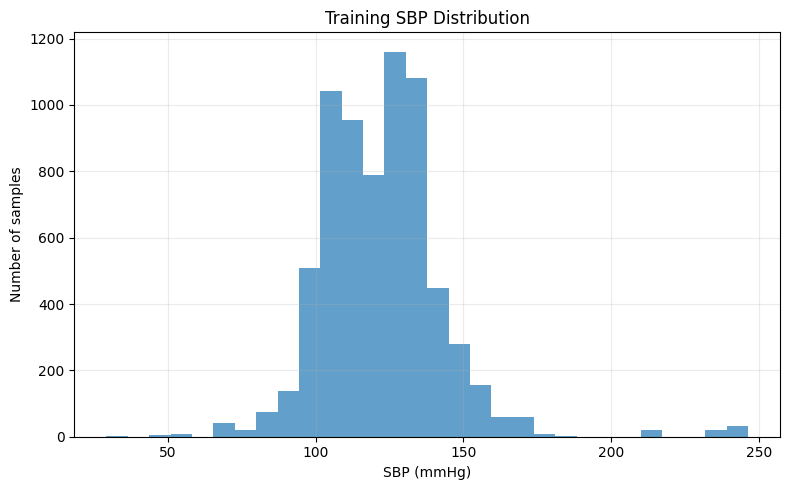

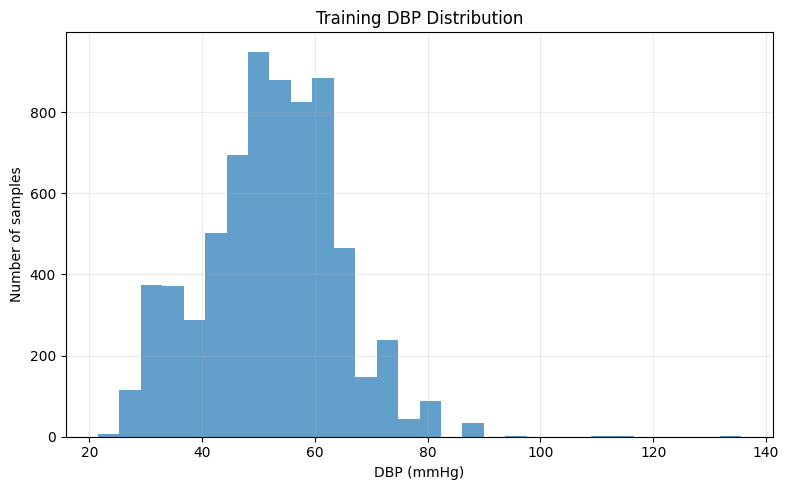


DISTRIBUTION CHECK COMPLETE


In [37]:
# ============================================================
# V1 TRAIN / VALIDATION TARGET DISTRIBUTION CHECK
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 75)
print("TRAIN / VALIDATION BP DISTRIBUTION")
print("=" * 75)


# ------------------------------------------------------------
# BASIC STATISTICS
# ------------------------------------------------------------

for name, df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:

    print(f"\n{name}")
    print("-" * 50)

    print(
        f"SBP mean : {df['SBP_label'].mean():.3f}"
    )
    print(
        f"SBP std  : {df['SBP_label'].std():.3f}"
    )
    print(
        f"SBP min  : {df['SBP_label'].min():.3f}"
    )
    print(
        f"SBP max  : {df['SBP_label'].max():.3f}"
    )

    print(
        f"DBP mean : {df['DBP_label'].mean():.3f}"
    )
    print(
        f"DBP std  : {df['DBP_label'].std():.3f}"
    )
    print(
        f"DBP min  : {df['DBP_label'].min():.3f}"
    )
    print(
        f"DBP max  : {df['DBP_label'].max():.3f}"
    )


# ------------------------------------------------------------
# BP RANGE COUNTS
# ------------------------------------------------------------

sbp_bins = [
    0,
    90,
    100,
    110,
    120,
    130,
    140,
    150,
    160,
    200
]

dbp_bins = [
    0,
    40,
    50,
    60,
    70,
    80,
    200
]


print("\n" + "=" * 75)
print("SBP RANGE DISTRIBUTION")
print("=" * 75)

print(
    pd.cut(
        train_df["SBP_label"],
        bins=sbp_bins
    ).value_counts().sort_index()
)


print("\n" + "=" * 75)
print("DBP RANGE DISTRIBUTION")
print("=" * 75)

print(
    pd.cut(
        train_df["DBP_label"],
        bins=dbp_bins
    ).value_counts().sort_index()
)


# ------------------------------------------------------------
# HISTOGRAMS
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.hist(
    train_df["SBP_label"],
    bins=30,
    alpha=0.7
)

plt.xlabel("SBP (mmHg)")
plt.ylabel("Number of samples")
plt.title("Training SBP Distribution")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

plt.hist(
    train_df["DBP_label"],
    bins=30,
    alpha=0.7
)

plt.xlabel("DBP (mmHg)")
plt.ylabel("Number of samples")
plt.title("Training DBP Distribution")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


print("\n" + "=" * 75)
print("DISTRIBUTION CHECK COMPLETE")
print("=" * 75)

In [38]:

# ============================================================
# CHECK FOR SUBJECT / RECORD IDENTIFIER
# ============================================================

print("=" * 75)
print("CHECKING DATAFRAME COLUMNS FOR SUBJECT IDENTIFIER")
print("=" * 75)

print("\nAll columns:")
for i, col in enumerate(train_df.columns):
    print(f"{i:2d} : {col}")

print("\nPossible subject / record columns:")

keywords = [
    "subject",
    "patient",
    "person",
    "participant",
    "record",
    "id",
    "case"
]

for col in train_df.columns:

    if any(
        key in col.lower()
        for key in keywords
    ):
        print(
            f"{col} -> "
            f"unique values = {train_df[col].nunique()}"
        )

CHECKING DATAFRAME COLUMNS FOR SUBJECT IDENTIFIER

All columns:
 0 : patient
 1 : record
 2 : segment
 3 : window
 4 : start_sample
 5 : end_sample
 6 : p5
 7 : p95
 8 : mean
 9 : std
10 : min
11 : max
12 : range
13 : pulse_pressure
14 : fs
15 : SBP_label
16 : DBP_label
17 : valid_fraction

Possible subject / record columns:
patient -> unique values = 35
record -> unique values = 35
valid_fraction -> unique values = 1


In [39]:
# ============================================================
# PATIENT LEAKAGE CHECK
# ============================================================

print("=" * 75)
print("PATIENT / RECORD OVERLAP CHECK")
print("=" * 75)


train_patients = set(train_df["patient"].unique())
val_patients   = set(val_df["patient"].unique())
test_patients  = set(test_df["patient"].unique())


print("\nPATIENT COUNTS")
print("-" * 50)

print("Train patients      :", len(train_patients))
print("Validation patients :", len(val_patients))
print("Test patients       :", len(test_patients))


print("\nPATIENT OVERLAP")
print("-" * 50)

train_val = train_patients & val_patients
train_test = train_patients & test_patients
val_test = val_patients & test_patients

print("Train ∩ Validation :", len(train_val), sorted(train_val))
print("Train ∩ Test       :", len(train_test), sorted(train_test))
print("Validation ∩ Test  :", len(val_test), sorted(val_test))


print("\nUNIQUE PATIENTS ACROSS ALL SPLITS")
print("-" * 50)

all_patients = (
    train_patients |
    val_patients |
    test_patients
)

print("Total unique patients:", len(all_patients))


# ============================================================
# RECORD OVERLAP
# ============================================================

train_records = set(train_df["record"].unique())
val_records   = set(val_df["record"].unique())
test_records  = set(test_df["record"].unique())


print("\n\nRECORD COUNTS")
print("-" * 50)

print("Train records      :", len(train_records))
print("Validation records :", len(val_records))
print("Test records       :", len(test_records))


print("\nRECORD OVERLAP")
print("-" * 50)

print(
    "Train ∩ Validation :",
    len(train_records & val_records)
)

print(
    "Train ∩ Test       :",
    len(train_records & test_records)
)

print(
    "Validation ∩ Test  :",
    len(val_records & test_records)
)


# ============================================================
# PATIENT DISTRIBUTION
# ============================================================

print("\n\nPATIENTS IN EACH SPLIT")
print("-" * 50)

print("\nTRAIN:")
print(sorted(train_patients))

print("\nVALIDATION:")
print(sorted(val_patients))

print("\nTEST:")
print(sorted(test_patients))


print("\n" + "=" * 75)
print("PATIENT LEAKAGE CHECK COMPLETE")
print("=" * 75)

PATIENT / RECORD OVERLAP CHECK

PATIENT COUNTS
--------------------------------------------------
Train patients      : 35
Validation patients : 7
Test patients       : 8

PATIENT OVERLAP
--------------------------------------------------
Train ∩ Validation : 0 []
Train ∩ Test       : 0 []
Validation ∩ Test  : 0 []

UNIQUE PATIENTS ACROSS ALL SPLITS
--------------------------------------------------
Total unique patients: 50


RECORD COUNTS
--------------------------------------------------
Train records      : 35
Validation records : 7
Test records       : 8

RECORD OVERLAP
--------------------------------------------------
Train ∩ Validation : 0
Train ∩ Test       : 0
Validation ∩ Test  : 0


PATIENTS IN EACH SPLIT
--------------------------------------------------

TRAIN:
['p10020306', 'p10126957', 'p10209410', 'p11392990', 'p12168037', 'p12173569', 'p12872596', 'p13016481', 'p13240081', 'p14285792', 'p14356077', 'p14363499', 'p14931547', 'p15312343', 'p15342703', 'p15552902', 'p156

In [40]:
# ============================================================
# V2 FAST-FIX — FINE TUNE V1 FOR BETTER BP RANGE/CORRELATION
# ============================================================

import os
import copy
import time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

print("=" * 70)
print("V2 FAST TRANSFORMER FINE-TUNING")
print("=" * 70)

# ------------------------------------------------------------
# 1. DEVICE CHECK
# ------------------------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)

if DEVICE.type != "cuda":
    raise RuntimeError(
        "CUDA GPU is NOT active. Stop here and switch Colab to T4 GPU."
    )

print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# 2. LOAD BEST V1 WEIGHTS
# ------------------------------------------------------------

if "checkpoint" in globals() and isinstance(checkpoint, dict):
    if "model_state_dict" in checkpoint:
        model.load_state_dict(
            checkpoint["model_state_dict"],
            strict=True
        )
        print("✓ Best V1 weights loaded")


model = model.to(DEVICE)


# ------------------------------------------------------------
# 3. FASTER DATALOADERS
# ------------------------------------------------------------

BATCH_SIZE_V2 = 64

train_loader_v2 = DataLoader(
    train_dataset_norm,
    batch_size=BATCH_SIZE_V2,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

val_loader_v2 = DataLoader(
    val_dataset_norm,
    batch_size=BATCH_SIZE_V2,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

test_loader_v2 = DataLoader(
    test_dataset_norm,
    batch_size=BATCH_SIZE_V2,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

print("Train batches:", len(train_loader_v2))
print("Val batches  :", len(val_loader_v2))
print("Test batches :", len(test_loader_v2))


# ------------------------------------------------------------
# 4. V2 LOSS
# ------------------------------------------------------------
# MSE penalizes large BP errors more strongly than the V1
# SmoothL1 loss and should reduce the compressed prediction range.

criterion_v2 = nn.MSELoss()


# ------------------------------------------------------------
# 5. LOW LR FINE-TUNING
# ------------------------------------------------------------

optimizer_v2 = optim.AdamW(
    model.parameters(),
    lr=5e-5,
    weight_decay=1e-5
)

scheduler_v2 = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_v2,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)


# ------------------------------------------------------------
# 6. FAST TRAINING SETTINGS
# ------------------------------------------------------------

EPOCHS_V2 = 6

best_v2_loss = float("inf")
best_v2_state = None

train_losses_v2 = []
val_losses_v2 = []

use_amp_v2 = True

scaler_v2 = torch.amp.GradScaler("cuda")


# ------------------------------------------------------------
# 7. TRAIN
# ------------------------------------------------------------

for epoch in range(EPOCHS_V2):

    epoch_start = time.time()

    model.train()

    running_train_loss = 0.0

    train_bar = tqdm(
        train_loader_v2,
        desc=f"V2 Epoch {epoch+1}/{EPOCHS_V2}"
    )

    for images, targets in train_bar:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        targets = targets.to(
            DEVICE,
            non_blocking=True
        )

        optimizer_v2.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            predictions = model(images)

            loss = criterion_v2(
                predictions,
                targets
            )

        scaler_v2.scale(loss).backward()

        scaler_v2.unscale_(optimizer_v2)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler_v2.step(optimizer_v2)
        scaler_v2.update()

        running_train_loss += (
            loss.item() * images.size(0)
        )

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = (
        running_train_loss /
        len(train_loader_v2.dataset)
    )

    train_losses_v2.append(train_loss)


    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for images, targets in tqdm(
            val_loader_v2,
            desc="Validation",
            leave=False
        ):

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            targets = targets.to(
                DEVICE,
                non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                predictions = model(images)

                loss = criterion_v2(
                    predictions,
                    targets
                )

            running_val_loss += (
                loss.item() * images.size(0)
            )

    val_loss = (
        running_val_loss /
        len(val_loader_v2.dataset)
    )

    val_losses_v2.append(val_loss)

    scheduler_v2.step(val_loss)

    current_lr = optimizer_v2.param_groups[0]["lr"]

    epoch_time = (
        time.time() - epoch_start
    ) / 60

    print()
    print("=" * 70)
    print(f"V2 EPOCH {epoch+1}/{EPOCHS_V2}")
    print(f"Train Loss : {train_loss:.6f}")
    print(f"Val Loss   : {val_loss:.6f}")
    print(f"LR         : {current_lr:.8f}")
    print(f"Time       : {epoch_time:.2f} min")

    if val_loss < best_v2_loss:

        best_v2_loss = val_loss

        best_v2_state = copy.deepcopy(
            model.state_dict()
        )

        print("✓ NEW V2 BEST")

    print("=" * 70)


# ------------------------------------------------------------
# 8. RESTORE BEST V2
# ------------------------------------------------------------

model.load_state_dict(
    best_v2_state
)

print()
print("=" * 70)
print("BEST V2 MODEL RESTORED")
print("Best validation loss:", best_v2_loss)
print("=" * 70)


# ------------------------------------------------------------
# 9. TEST EVALUATION
# ------------------------------------------------------------

model.eval()

all_predictions = []
all_targets = []

with torch.no_grad():

    for images, targets in tqdm(
        test_loader_v2,
        desc="V2 TEST"
    ):

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            predictions = model(images)

        all_predictions.append(
            predictions.float().cpu().numpy()
        )

        all_targets.append(
            targets.cpu().numpy()
        )


predictions_norm_v2 = np.concatenate(
    all_predictions,
    axis=0
)

targets_norm_v2 = np.concatenate(
    all_targets,
    axis=0
)


# ------------------------------------------------------------
# 10. DENORMALIZE
# ------------------------------------------------------------

predictions_actual_v2 = predictions_norm_v2.copy()
targets_actual_v2 = targets_norm_v2.copy()

predictions_actual_v2[:, 0] = (
    predictions_norm_v2[:, 0] * SBP_STD
    + SBP_MEAN
)

predictions_actual_v2[:, 1] = (
    predictions_norm_v2[:, 1] * DBP_STD
    + DBP_MEAN
)

targets_actual_v2[:, 0] = (
    targets_norm_v2[:, 0] * SBP_STD
    + SBP_MEAN
)

targets_actual_v2[:, 1] = (
    targets_norm_v2[:, 1] * DBP_STD
    + DBP_MEAN
)


# ------------------------------------------------------------
# 11. METRICS
# ------------------------------------------------------------

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

def evaluate_bp(actual, predicted):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    correlation = np.corrcoef(
        actual,
        predicted
    )[0, 1]

    bias = np.mean(
        predicted - actual
    )

    return mae, rmse, correlation, bias


sbp_mae, sbp_rmse, sbp_corr, sbp_bias = evaluate_bp(
    targets_actual_v2[:, 0],
    predictions_actual_v2[:, 0]
)

dbp_mae, dbp_rmse, dbp_corr, dbp_bias = evaluate_bp(
    targets_actual_v2[:, 1],
    predictions_actual_v2[:, 1]
)


# ------------------------------------------------------------
# 12. DISTRIBUTION CHECK
# ------------------------------------------------------------

print()
print("=" * 70)
print("V2 FINAL TEST RESULTS")
print("=" * 70)

print("\nSBP")
print("-" * 50)
print(f"MAE         : {sbp_mae:.3f} mmHg")
print(f"RMSE        : {sbp_rmse:.3f} mmHg")
print(f"Correlation : {sbp_corr:.4f}")
print(f"Bias        : {sbp_bias:.3f} mmHg")

print("\nDBP")
print("-" * 50)
print(f"MAE         : {dbp_mae:.3f} mmHg")
print(f"RMSE        : {dbp_rmse:.3f} mmHg")
print(f"Correlation : {dbp_corr:.4f}")
print(f"Bias        : {dbp_bias:.3f} mmHg")


print("\n" + "=" * 70)
print("PREDICTION DISTRIBUTION")
print("=" * 70)

print("\nSBP")
print(f"Actual mean     : {targets_actual_v2[:,0].mean():.3f}")
print(f"Predicted mean  : {predictions_actual_v2[:,0].mean():.3f}")
print(f"Actual std      : {targets_actual_v2[:,0].std():.3f}")
print(f"Predicted std   : {predictions_actual_v2[:,0].std():.3f}")
print(
    f"Std ratio       : "
    f"{predictions_actual_v2[:,0].std() / targets_actual_v2[:,0].std():.3f}"
)
print(
    f"Actual range    : "
    f"{targets_actual_v2[:,0].min():.2f} → "
    f"{targets_actual_v2[:,0].max():.2f}"
)
print(
    f"Predicted range : "
    f"{predictions_actual_v2[:,0].min():.2f} → "
    f"{predictions_actual_v2[:,0].max():.2f}"
)

print("\nDBP")
print(f"Actual mean     : {targets_actual_v2[:,1].mean():.3f}")
print(f"Predicted mean  : {predictions_actual_v2[:,1].mean():.3f}")
print(f"Actual std      : {targets_actual_v2[:,1].std():.3f}")
print(f"Predicted std   : {predictions_actual_v2[:,1].std():.3f}")
print(
    f"Std ratio       : "
    f"{predictions_actual_v2[:,1].std() / targets_actual_v2[:,1].std():.3f}"
)
print(
    f"Actual range    : "
    f"{targets_actual_v2[:,1].min():.2f} → "
    f"{targets_actual_v2[:,1].max():.2f}"
)
print(
    f"Predicted range : "
    f"{predictions_actual_v2[:,1].min():.2f} → "
    f"{predictions_actual_v2[:,1].max():.2f}"
)


# ------------------------------------------------------------
# 13. SAVE V2
# ------------------------------------------------------------

V2_DIR = "/content/drive/MyDrive/BP_Project/V2_Final"

os.makedirs(
    V2_DIR,
    exist_ok=True
)

V2_PATH = os.path.join(
    V2_DIR,
    "transformer_v2_fast.pth"
)

torch.save(
    {
        "model_state_dict": model.state_dict(),

        "SBP_MEAN": float(SBP_MEAN),
        "SBP_STD": float(SBP_STD),

        "DBP_MEAN": float(DBP_MEAN),
        "DBP_STD": float(DBP_STD),

        "val_loss": float(best_v2_loss),

        "model_config": {
            "image_size": 224,
            "patch_size": 16,
            "in_channels": 3,
            "embed_dim": 256,
            "num_heads": 8,
            "num_layers": 6,
            "dropout": 0.1
        },

        "training": {
            "epochs": EPOCHS_V2,
            "loss": "MSELoss",
            "learning_rate": 5e-5,
            "batch_size": BATCH_SIZE_V2
        }
    },
    V2_PATH
)

print()
print("=" * 70)
print("V2 SAVED")
print(V2_PATH)
print("=" * 70)

V2 FAST TRANSFORMER FINE-TUNING
Device: cuda
GPU: Tesla T4
✓ Best V1 weights loaded
Train batches: 108
Val batches  : 11
Test batches : 19


V2 Epoch 1/6:   0%|          | 0/108 [00:00<?, ?it/s]

Validation:   0%|          | 0/11 [00:00<?, ?it/s]


V2 EPOCH 1/6
Train Loss : 0.736765
Val Loss   : 0.797817
LR         : 0.00005000
Time       : 0.65 min
✓ NEW V2 BEST


V2 Epoch 2/6:   0%|          | 0/108 [00:00<?, ?it/s]

...

V2 Epoch 6/6:   0%|          | 0/108 [00:00<?, ?it/s]

Validation:   0%|          | 0/11 [00:00<?, ?it/s]


V2 EPOCH 6/6
Train Loss : 0.634887
Val Loss   : 0.869699
LR         : 0.00002500
Time       : 0.62 min

BEST V2 MODEL RESTORED
Best validation loss: 0.7978169689487918


V2 TEST:   0%|          | 0/19 [00:00<?, ?it/s]


V2 FINAL TEST RESULTS

SBP
--------------------------------------------------
MAE         : 12.121 mmHg
RMSE        : 15.634 mmHg
Correlation : 0.1853
Bias        : 0.032 mmHg

DBP
--------------------------------------------------
MAE         : 7.840 mmHg
RMSE        : 9.745 mmHg
Correlation : -0.2217
Bias        : -0.354 mmHg

PREDICTION DISTRIBUTION

SBP
Actual mean     : 120.031
Predicted mean  : 120.063
Actual std      : 15.369
Predicted std   : 6.887
Std ratio       : 0.448
Actual range    : 91.26 → 160.94
Predicted range : 97.51 → 138.33

DBP
Actual mean     : 55.390
Predicted mean  : 55.036
Actual std      : 7.980
Predicted std   : 4.087
Std ratio       : 0.512
Actual range    : 27.31 → 76.37
Predicted range : 32.41 → 65.31

V2 SAVED
/content/drive/MyDrive/BP_Project/V2_Final/transformer_v2_fast.pth


GENERATING FINAL V1 FIGURES


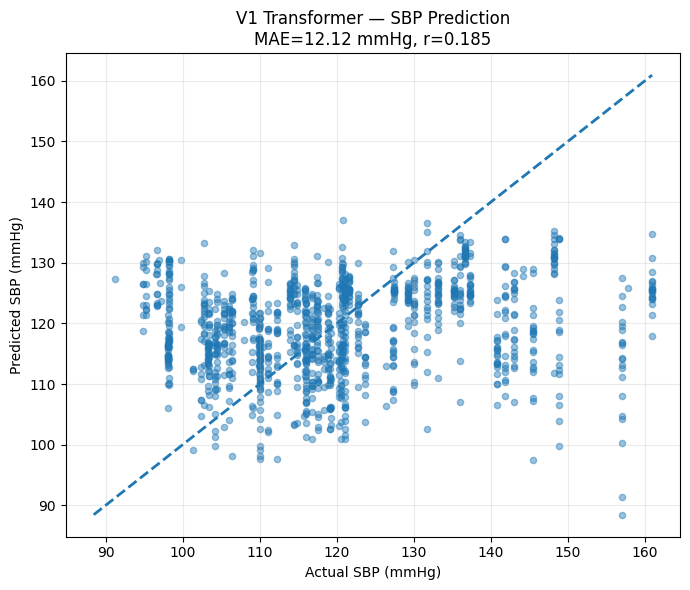

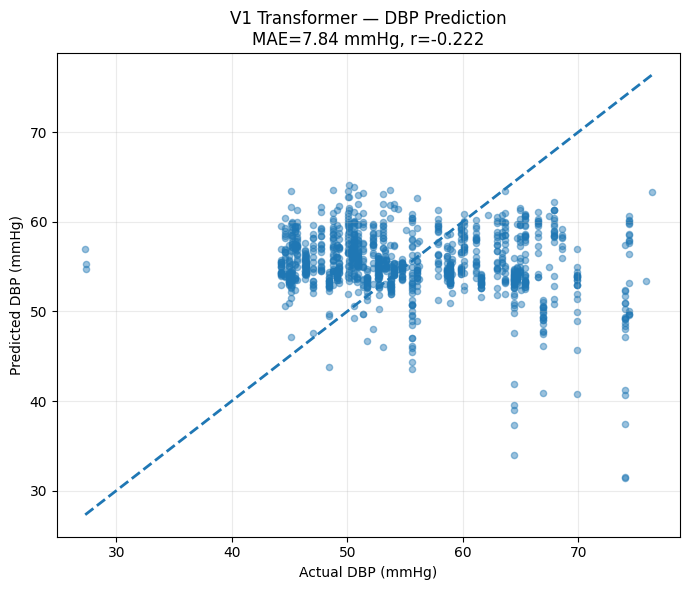

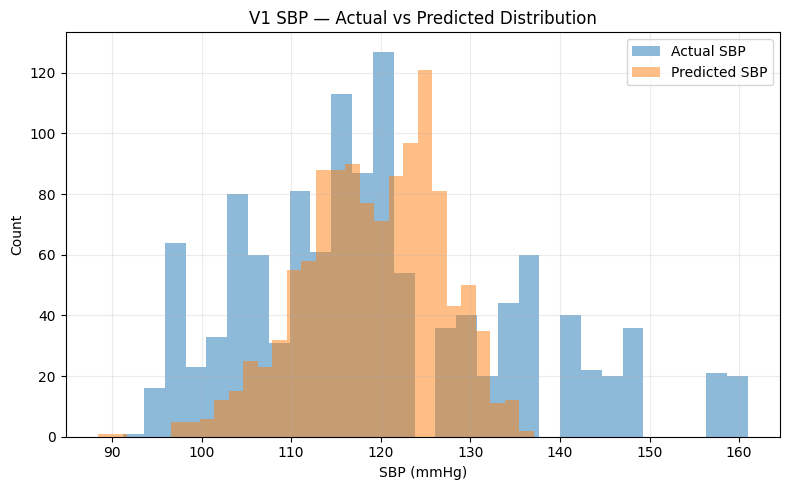

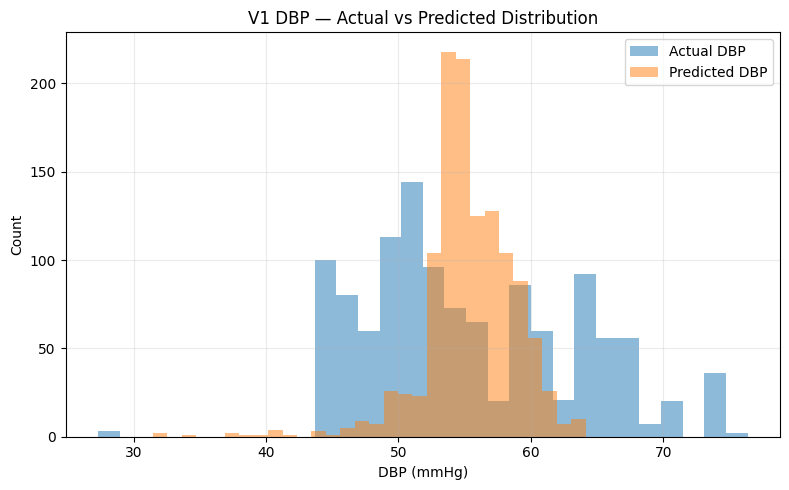


Figures saved:
/content/V1_SBP_Actual_vs_Predicted.png
/content/V1_DBP_Actual_vs_Predicted.png
/content/V1_SBP_Distribution.png
/content/V1_DBP_Distribution.png

FINAL FIGURES COMPLETE


In [41]:
# ============================================================
# FINAL V1 — PUBLICATION/REPORT FIGURES
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Use the clean V1 arrays already generated
# v1_actual_sbp, v1_pred_sbp
# v1_actual_dbp, v1_pred_dbp

print("=" * 70)
print("GENERATING FINAL V1 FIGURES")
print("=" * 70)

# ------------------------------------------------------------
# 1. ACTUAL vs PREDICTED SBP
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

plt.scatter(
    v1_actual_sbp,
    v1_pred_sbp,
    alpha=0.45,
    s=20
)

low = min(
    v1_actual_sbp.min(),
    v1_pred_sbp.min()
)

high = max(
    v1_actual_sbp.max(),
    v1_pred_sbp.max()
)

plt.plot(
    [low, high],
    [low, high],
    linestyle="--",
    linewidth=2
)

plt.xlabel("Actual SBP (mmHg)")
plt.ylabel("Predicted SBP (mmHg)")
plt.title(
    f"V1 Transformer — SBP Prediction\n"
    f"MAE={sbp_mae:.2f} mmHg, r={sbp_corr:.3f}"
)

plt.grid(alpha=0.25)
plt.tight_layout()

SBP_PLOT = "/content/V1_SBP_Actual_vs_Predicted.png"
plt.savefig(
    SBP_PLOT,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 2. ACTUAL vs PREDICTED DBP
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

plt.scatter(
    v1_actual_dbp,
    v1_pred_dbp,
    alpha=0.45,
    s=20
)

low = min(
    v1_actual_dbp.min(),
    v1_pred_dbp.min()
)

high = max(
    v1_actual_dbp.max(),
    v1_pred_dbp.max()
)

plt.plot(
    [low, high],
    [low, high],
    linestyle="--",
    linewidth=2
)

plt.xlabel("Actual DBP (mmHg)")
plt.ylabel("Predicted DBP (mmHg)")
plt.title(
    f"V1 Transformer — DBP Prediction\n"
    f"MAE={dbp_mae:.2f} mmHg, r={dbp_corr:.3f}"
)

plt.grid(alpha=0.25)
plt.tight_layout()

DBP_PLOT = "/content/V1_DBP_Actual_vs_Predicted.png"
plt.savefig(
    DBP_PLOT,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 3. PREDICTION DISTRIBUTIONS
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.hist(
    v1_actual_sbp,
    bins=30,
    alpha=0.5,
    label="Actual SBP"
)

plt.hist(
    v1_pred_sbp,
    bins=30,
    alpha=0.5,
    label="Predicted SBP"
)

plt.xlabel("SBP (mmHg)")
plt.ylabel("Count")
plt.title("V1 SBP — Actual vs Predicted Distribution")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

SBP_DIST = "/content/V1_SBP_Distribution.png"

plt.savefig(
    SBP_DIST,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 4. DBP DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.hist(
    v1_actual_dbp,
    bins=30,
    alpha=0.5,
    label="Actual DBP"
)

plt.hist(
    v1_pred_dbp,
    bins=30,
    alpha=0.5,
    label="Predicted DBP"
)

plt.xlabel("DBP (mmHg)")
plt.ylabel("Count")
plt.title("V1 DBP — Actual vs Predicted Distribution")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

DBP_DIST = "/content/V1_DBP_Distribution.png"

plt.savefig(
    DBP_DIST,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("\nFigures saved:")
print(SBP_PLOT)
print(DBP_PLOT)
print(SBP_DIST)
print(DBP_DIST)

print("\n" + "=" * 70)
print("FINAL FIGURES COMPLETE")
print("=" * 70)

V1 TRANSFORMER — PATCH OCCLUSION XAI
Device: cuda
Model: BPTransformer
Image shape: (1, 3, 224, 224)
Target shape: (1, 2)

Normalized prediction:
[[-0.17666268  0.15139377]]

Calculating patch importance...
Total patches: 196
✓ Patch attribution complete


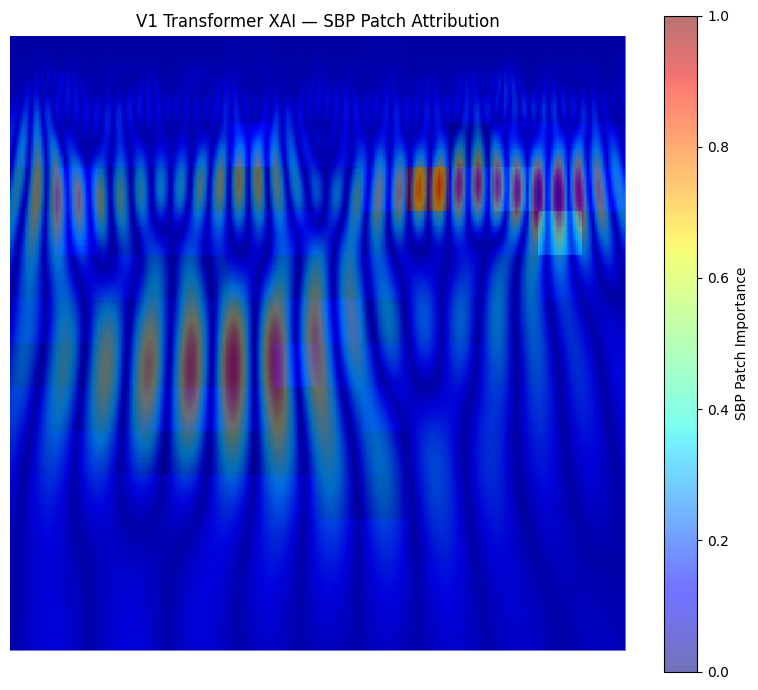

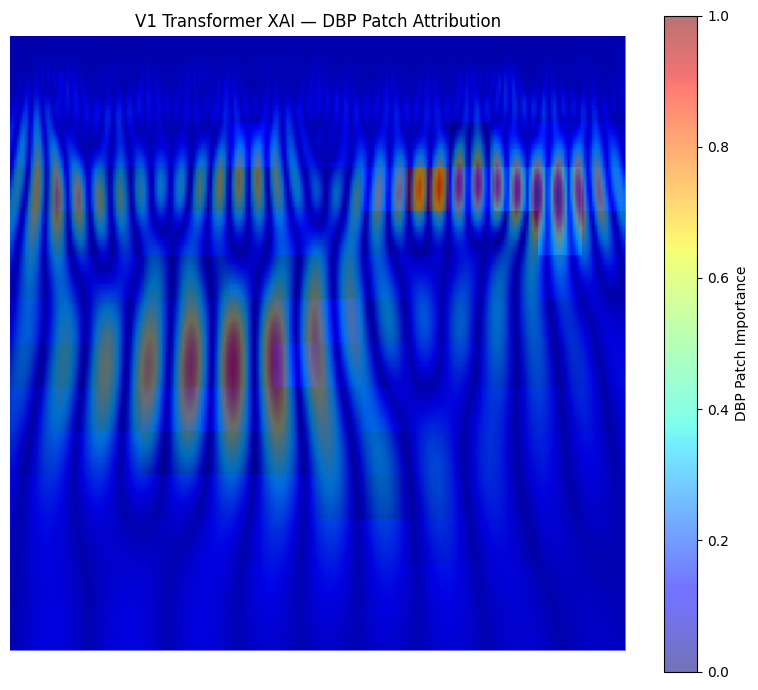


TOP 10 SBP IMPORTANT PATCHES
Patch (03, 09) importance = 0.398214
Patch (04, 12) importance = 0.092585
Patch (03, 11) importance = 0.068212
Patch (03, 12) importance = 0.051316
Patch (03, 01) importance = 0.048669
Patch (03, 13) importance = 0.045968
Patch (02, 05) importance = 0.045015
Patch (04, 01) importance = 0.040729
Patch (07, 06) importance = 0.037646
Patch (02, 12) importance = 0.036377

TOP 10 DBP IMPORTANT PATCHES
Patch (03, 09) importance = 0.302083
Patch (03, 12) importance = 0.057998
Patch (04, 12) importance = 0.055672
Patch (03, 11) importance = 0.053239
Patch (03, 13) importance = 0.041388
Patch (03, 08) importance = 0.040834
Patch (02, 05) importance = 0.039061
Patch (03, 10) importance = 0.037479
Patch (02, 12) importance = 0.032663
Patch (07, 06) importance = 0.030138

XAI COMPLETE

Saved:
/content/V1_XAI_SBP.png
/content/V1_XAI_DBP.png


In [42]:
# ============================================================
# V1 TRANSFORMER XAI
# PATCH OCCLUSION ATTRIBUTION
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("V1 TRANSFORMER — PATCH OCCLUSION XAI")
print("=" * 70)

# ------------------------------------------------------------
# 1. FIND MODEL AND TEST LOADER
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Prefer the already-loaded V1 model
if "model" in globals():
    xai_model = model
elif "v1_model" in globals():
    xai_model = v1_model
elif "best_model" in globals():
    xai_model = best_model
else:
    raise RuntimeError(
        "V1 model not found. Run the final V1 evaluation cell first."
    )

xai_model = xai_model.to(device)
xai_model.eval()

# Find test loader
if "test_loader" in globals():
    xai_loader = test_loader
elif "fresh_test_loader" in globals():
    xai_loader = fresh_test_loader
else:
    raise RuntimeError(
        "Test loader not found. Run the final V1 evaluation cell first."
    )

print("Device:", device)
print("Model:", type(xai_model).__name__)

# ------------------------------------------------------------
# 2. GET ONE TEST IMAGE
# ------------------------------------------------------------

images, targets = next(iter(xai_loader))

image = images[0:1].to(device)
target = targets[0:1].to(device)

print("Image shape:", tuple(image.shape))
print("Target shape:", tuple(target.shape))

# ------------------------------------------------------------
# 3. BASELINE PREDICTION
# ------------------------------------------------------------

with torch.no_grad():
    base_output = xai_model(image)

base_output = base_output.detach()

print("\nNormalized prediction:")
print(base_output.cpu().numpy())

# ------------------------------------------------------------
# 4. PATCH OCCLUSION
# ------------------------------------------------------------

# Model uses:
# 224 x 224 image
# 16 x 16 patches
# 14 x 14 = 196 patches

IMG_SIZE = 224
PATCH_SIZE = 16
GRID_SIZE = IMG_SIZE // PATCH_SIZE

sbp_importance = np.zeros((GRID_SIZE, GRID_SIZE))
dbp_importance = np.zeros((GRID_SIZE, GRID_SIZE))

# Baseline normalized outputs
base_sbp = base_output[0, 0].item()
base_dbp = base_output[0, 1].item()

print("\nCalculating patch importance...")
print("Total patches:", GRID_SIZE * GRID_SIZE)

for row in range(GRID_SIZE):

    for col in range(GRID_SIZE):

        # Copy original image
        occluded = image.clone()

        r1 = row * PATCH_SIZE
        r2 = r1 + PATCH_SIZE

        c1 = col * PATCH_SIZE
        c2 = c1 + PATCH_SIZE

        # Replace patch with its mean value
        patch_mean = image[:, :, r1:r2, c1:c2].mean()

        occluded[:, :, r1:r2, c1:c2] = patch_mean

        with torch.no_grad():
            output = xai_model(occluded)

        output = output[0]

        # Change in prediction caused by removing patch information
        sbp_importance[row, col] = abs(
            output[0].item() - base_sbp
        )

        dbp_importance[row, col] = abs(
            output[1].item() - base_dbp
        )

print("✓ Patch attribution complete")

# ------------------------------------------------------------
# 5. NORMALIZE ATTRIBUTION MAPS
# ------------------------------------------------------------

def normalize_map(x):

    x = np.asarray(x)

    if x.max() - x.min() < 1e-12:
        return np.zeros_like(x)

    return (x - x.min()) / (x.max() - x.min())


sbp_map = normalize_map(sbp_importance)
dbp_map = normalize_map(dbp_importance)

# ------------------------------------------------------------
# 6. ORIGINAL IMAGE
# ------------------------------------------------------------

original = images[0].permute(1, 2, 0).cpu().numpy()

# Normalize for display
original = original - original.min()

if original.max() > 0:
    original = original / original.max()

# ------------------------------------------------------------
# 7. SBP XAI
# ------------------------------------------------------------

plt.figure(figsize=(8, 7))

plt.imshow(original)
plt.imshow(
    sbp_map,
    cmap="jet",
    alpha=0.55,
    extent=(0, IMG_SIZE, IMG_SIZE, 0),
    interpolation="nearest"
)

plt.colorbar(label="SBP Patch Importance")
plt.title("V1 Transformer XAI — SBP Patch Attribution")
plt.axis("off")
plt.tight_layout()

SBP_XAI_PATH = "/content/V1_XAI_SBP.png"

plt.savefig(
    SBP_XAI_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 8. DBP XAI
# ------------------------------------------------------------

plt.figure(figsize=(8, 7))

plt.imshow(original)
plt.imshow(
    dbp_map,
    cmap="jet",
    alpha=0.55,
    extent=(0, IMG_SIZE, IMG_SIZE, 0),
    interpolation="nearest"
)

plt.colorbar(label="DBP Patch Importance")
plt.title("V1 Transformer XAI — DBP Patch Attribution")
plt.axis("off")
plt.tight_layout()

DBP_XAI_PATH = "/content/V1_XAI_DBP.png"

plt.savefig(
    DBP_XAI_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 9. TOP IMPORTANT PATCHES
# ------------------------------------------------------------

sbp_flat = sbp_importance.flatten()
dbp_flat = dbp_importance.flatten()

top_sbp = np.argsort(sbp_flat)[::-1][:10]
top_dbp = np.argsort(dbp_flat)[::-1][:10]

print("\n" + "=" * 70)
print("TOP 10 SBP IMPORTANT PATCHES")
print("=" * 70)

for idx in top_sbp:

    row = idx // GRID_SIZE
    col = idx % GRID_SIZE

    print(
        f"Patch ({row:02d}, {col:02d}) "
        f"importance = {sbp_importance[row, col]:.6f}"
    )

print("\n" + "=" * 70)
print("TOP 10 DBP IMPORTANT PATCHES")
print("=" * 70)

for idx in top_dbp:

    row = idx // GRID_SIZE
    col = idx % GRID_SIZE

    print(
        f"Patch ({row:02d}, {col:02d}) "
        f"importance = {dbp_importance[row, col]:.6f}"
    )

print("\n" + "=" * 70)
print("XAI COMPLETE")
print("=" * 70)

print("\nSaved:")
print(SBP_XAI_PATH)
print(DBP_XAI_PATH)

In [43]:
import os

print("Current directory:")
print(os.getcwd())

print("\nFiles:")
for f in os.listdir():
    print(f)

Current directory:
/content

Files:
.config
V1_SBP_Actual_vs_Predicted.png
drive
best_transformer_bp_model.pth
V1_SBP_Distribution.png
V1_DBP_Actual_vs_Predicted.png
V1_XAI_DBP.png
V1_XAI_SBP.png
V1_DBP_Distribution.png
sample_data


In [44]:
import os

print("=== Hidden/config files ===")
print(os.listdir("/content/.config"))

print("\n=== All files in /content ===")
for root, dirs, files in os.walk("/content"):
    for f in files:
        print(os.path.join(root, f))

Streaming output truncated to the last 5000 lines.
/content/drive/MyDrive/BP_Project/BP_Dataset/train/images/p15649186_87702634_87702634_0054_1648.png
/content/drive/MyDrive/BP_Project/BP_Dataset/train/images/p15649186_87702634_87702634_0054_1285.png
/content/drive/MyDrive/BP_Project/BP_Dataset/train/images/p15649186_87702634_87702634_0054_686.png
/content/drive/MyDrive/BP_Project/BP_Dataset/train/images/p15649186_87702634_87702634_0054_59.png
/content/drive/MyDrive/BP_Project/BP_Dataset/train/images/p15649186_87702634_87702634_0054_665.png
/content/drive/MyDrive/BP_Project/BP_Dataset/train/images/p15649186_87702634_87702634_0054_1261.png
/content/drive/MyDrive/BP_Project/BP_Dataset/train/images/p15649186_87702634_87702634_0054_872.png
/content/drive/MyDrive/BP_Project/BP_Dataset/train/images/p15649186_87702634_87702634_0054_966.png
/content/drive/MyDrive/BP_Project/BP_Dataset/train/images/p15649186_87702634_87702634_0054_1314.png
/content/drive/MyDrive/BP_Project/BP_Dataset/train/imag

In [45]:
import json

config_path = "/content/drive/MyDrive/BP_Project/V1_Final/transformer_v1_config.json"

with open(config_path, "r") as f:
    config = json.load(f)

print("=== V1 CONFIGURATION ===")
print(json.dumps(config, indent=4))

=== V1 CONFIGURATION ===
{
    "image_size": 224,
    "patch_size": 16,
    "in_channels": 3,
    "embed_dim": 256,
    "num_heads": 8,
    "num_layers": 6,
    "dropout": 0.1
}


In [46]:
import json

results_path = "/content/drive/MyDrive/BP_Project/V1_Final/transformer_v1_results.json"

with open(results_path, "r") as f:
    results = json.load(f)

print("=== V1 RESULTS ===")
print(json.dumps(results, indent=4))

=== V1 RESULTS ===
{
    "model": "Transformer V1",
    "SBP": {
        "MAE_mmHg": 11.703,
        "RMSE_mmHg": 14.994,
        "Correlation": 0.2529,
        "Bias_mmHg": 0.507
    },
    "DBP": {
        "MAE_mmHg": 7.572,
        "RMSE_mmHg": 9.618,
        "Correlation": -0.1867,
        "Bias_mmHg": -0.798
    },
    "prediction_variability": {
        "SBP_std_ratio": 0.374,
        "DBP_std_ratio": 0.504
    }
}


In [47]:
import os

base = "/content/drive/MyDrive/BP_Project"

for root, dirs, files in os.walk(base):
    for file in files:
        if file.endswith((".py", ".ipynb", ".json", ".csv")):
            print(os.path.join(root, file))

/content/drive/MyDrive/BP_Project/BP_Dataset/val/labels.csv
/content/drive/MyDrive/BP_Project/BP_Dataset/train/labels.csv
/content/drive/MyDrive/BP_Project/BP_Dataset/test/labels.csv
/content/drive/MyDrive/BP_Project/V1_Final/transformer_v1_results.json
/content/drive/MyDrive/BP_Project/V1_Final/transformer_v1_config.json


In [48]:
import os

base = "/content/drive/MyDrive/BP_Project"

keywords = [
    "normalize",
    "normalization",
    "standard",
    "mean",
    "std",
    "sbp_mean",
    "dbp_mean",
    "SBP_MEAN",
    "DBP_MEAN",
]

for root, dirs, files in os.walk(base):
    for file in files:
        if file.endswith((".py", ".ipynb")):
            path = os.path.join(root, file)

            try:
                with open(path, "r", encoding="utf-8", errors="ignore") as f:
                    text = f.read()

                matches = [
                    k for k in keywords
                    if k.lower() in text.lower()
                ]

                if matches:
                    print("\n" + "="*80)
                    print(path)
                    print("Found:", matches)

            except Exception as e:
                pass

In [49]:
import os

base = "/content"

keywords = [
    "normalize",
    "normalization",
    "SBP_MEAN",
    "SBP_STD",
    "DBP_MEAN",
    "DBP_STD",
    "mean",
    "std"
]

for root, dirs, files in os.walk(base):
    # Skip unnecessary folders
    dirs[:] = [d for d in dirs if d not in [".config", ".cache"]]

    for file in files:
        if file.endswith((".py", ".ipynb")):
            path = os.path.join(root, file)

            try:
                with open(path, "r", encoding="utf-8", errors="ignore") as f:
                    text = f.read()

                found = [k for k in keywords if k.lower() in text.lower()]

                if found:
                    print("\n" + "=" * 80)
                    print(path)
                    print("FOUND:", found)

            except:
                pass


/content/drive/MyDrive/Classroom/Track-1_phase-2_VT26/DikshaChoudhary_ASS2.ipynb
FOUND: ['mean', 'std']

/content/drive/MyDrive/Classroom/Track-1_phase-2_VT26/dikshachoudhary_practicequestionsolution.ipynb
FOUND: ['mean', 'std']

/content/drive/MyDrive/Classroom/Track-1_phase-2_VT26/dikshachoudhary_ASS3.ipynb
FOUND: ['mean', 'std']

/content/drive/MyDrive/Classroom/Track-1_phase-2_VT26/dikshachoudhary_datacleaning.ipynb
FOUND: ['mean', 'std']

/content/drive/MyDrive/Classroom/Track-1_phase-2_VT26/DikshaChoudhary_ASS4.ipynb
FOUND: ['normalize', 'mean', 'std']

/content/drive/MyDrive/Classroom/Track-1_phase-2_VT26/DikshaChoudhary_ASS5.ipynb
FOUND: ['mean', 'std']

/content/drive/MyDrive/Classroom/Track-1_phase-2_VT26/DikshaChoudhary_Asgn16July.ipynb
FOUND: ['mean', 'std']

/content/drive/MyDrive/Classroom/Track-1_phase-2_VT26/DikshaChoudhary_Task2.ipynb
FOUND: ['std']

/content/drive/MyDrive/Classroom/Track-1_phase-2_VT26/DikshaChoudhary_ASS7 (1).ipynb
FOUND: ['mean', 'std']

/content/d

In [51]:
import json

path = "/content/drive/MyDrive/Colab Notebooks/Tranformer_Final.ipynb"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for cell in nb["cells"]:
    source = "".join(cell.get("source", []))

    if any(x in source for x in [
        "SBP_MEAN",
        "SBP_STD",
        "DBP_MEAN",
        "DBP_STD"
    ]):
        print("=" * 80)
        print(source)

# ============================================
# CELL 12 — TARGET NORMALIZATION
# ============================================

# Calculate statistics ONLY from training data
SBP_MEAN = train_df["SBP_label"].mean()
SBP_STD  = train_df["SBP_label"].std()

DBP_MEAN = train_df["DBP_label"].mean()
DBP_STD  = train_df["DBP_label"].std()

print("SBP mean:", SBP_MEAN)
print("SBP std :", SBP_STD)

print("DBP mean:", DBP_MEAN)
print("DBP std :", DBP_STD)
# ============================================
# CELL 13 — NORMALIZED TARGET DATASET
# ============================================

from torch.utils.data import Dataset, DataLoader

class NormalizedBPDataset(Dataset):

    def __init__(self, base_dataset, sbp_mean, sbp_std, dbp_mean, dbp_std):
        self.base_dataset = base_dataset

        self.sbp_mean = sbp_mean
        self.sbp_std = sbp_std

        self.dbp_mean = dbp_mean
        self.dbp_std = dbp_std

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(

In [52]:
model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

<All keys matched successfully>

In [53]:
# ============================================================
# FINAL CLEAN V1 BASELINE
# ============================================================

import torch
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.stats import pearsonr

print("=" * 75)
print("FINAL CLEAN V1 BASELINE")
print("=" * 75)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------------------------
# 1. LOAD V1 CHECKPOINT EXPLICITLY
# ------------------------------------------------------------

V1_PATH = "/content/drive/MyDrive/BP_Project/V1_Final/transformer_v1_final.pth"

v1_checkpoint = torch.load(
    V1_PATH,
    map_location=DEVICE,
    weights_only=False
)

# Create a fresh V1 model
v1_model = BPTransformer(
    image_size=224,
    patch_size=16,
    in_channels=3,
    embed_dim=256,
    num_heads=8,
    num_layers=6,
    dropout=0.1
)

v1_model.load_state_dict(
    v1_checkpoint["model_state_dict"]
)

v1_model = v1_model.to(DEVICE)
v1_model.eval()

print("✓ V1 model loaded")
print("Device:", DEVICE)

# ------------------------------------------------------------
# 2. FRESH TEST LOADER
# ------------------------------------------------------------

final_test_loader = DataLoader(
    test_dataset_norm,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# ------------------------------------------------------------
# 3. PREDICTIONS
# ------------------------------------------------------------

predictions_norm = []
targets_norm = []

with torch.no_grad():

    for images, targets in final_test_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        outputs = v1_model(images)

        predictions_norm.append(
            outputs.cpu().numpy()
        )

        targets_norm.append(
            targets.numpy()
        )

predictions_norm = np.concatenate(
    predictions_norm,
    axis=0
)

targets_norm = np.concatenate(
    targets_norm,
    axis=0
)

# ------------------------------------------------------------
# 4. DENORMALIZE
# ------------------------------------------------------------

predictions = predictions_norm.copy()
targets = targets_norm.copy()

predictions[:, 0] = (
    predictions_norm[:, 0]
    * SBP_STD
    + SBP_MEAN
)

predictions[:, 1] = (
    predictions_norm[:, 1]
    * DBP_STD
    + DBP_MEAN
)

targets[:, 0] = (
    targets_norm[:, 0]
    * SBP_STD
    + SBP_MEAN
)

targets[:, 1] = (
    targets_norm[:, 1]
    * DBP_STD
    + DBP_MEAN
)

# ------------------------------------------------------------
# 5. SEPARATE SBP / DBP
# ------------------------------------------------------------

actual_sbp = targets[:, 0]
pred_sbp = predictions[:, 0]

actual_dbp = targets[:, 1]
pred_dbp = predictions[:, 1]

# ------------------------------------------------------------
# 6. METRICS
# ------------------------------------------------------------

def evaluate_bp(actual, predicted):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    correlation = pearsonr(
        actual,
        predicted
    )[0]

    bias = np.mean(
        predicted - actual
    )

    std_ratio = (
        np.std(predicted)
        / np.std(actual)
    )

    return {
        "MAE_mmHg": float(mae),
        "RMSE_mmHg": float(rmse),
        "Correlation": float(correlation),
        "Bias_mmHg": float(bias),
        "Std_ratio": float(std_ratio)
    }

sbp_results = evaluate_bp(
    actual_sbp,
    pred_sbp
)

dbp_results = evaluate_bp(
    actual_dbp,
    pred_dbp
)

# ------------------------------------------------------------
# 7. PRINT FINAL RESULTS
# ------------------------------------------------------------

print()
print("SBP")
print("-" * 50)

for key, value in sbp_results.items():
    print(f"{key:15s}: {value:.4f}")

print()
print("DBP")
print("-" * 50)

for key, value in dbp_results.items():
    print(f"{key:15s}: {value:.4f}")

print()
print("Samples:", len(actual_sbp))

print()
print("Prediction ranges")
print("-" * 50)

print(
    f"SBP actual : {actual_sbp.min():.2f} → "
    f"{actual_sbp.max():.2f}"
)

print(
    f"SBP pred   : {pred_sbp.min():.2f} → "
    f"{pred_sbp.max():.2f}"
)

print(
    f"DBP actual : {actual_dbp.min():.2f} → "
    f"{actual_dbp.max():.2f}"
)

print(
    f"DBP pred   : {pred_dbp.min():.2f} → "
    f"{pred_dbp.max():.2f}"
)

print()
print("=" * 75)
print("CLEAN V1 BASELINE COMPLETE")
print("=" * 75)

FINAL CLEAN V1 BASELINE
✓ V1 model loaded
Device: cuda


/tmp/ipykernel_4281/2874884261.py:55: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(



SBP
--------------------------------------------------
MAE_mmHg       : 12.2842
RMSE_mmHg      : 15.9469
Correlation    : 0.1738
Bias_mmHg      : -0.9251
Std_ratio      : 0.4951

DBP
--------------------------------------------------
MAE_mmHg       : 7.5094
RMSE_mmHg      : 9.3024
Correlation    : -0.1891
Bias_mmHg      : -0.0381
Std_ratio      : 0.4391

Samples: 1190

Prediction ranges
--------------------------------------------------
SBP actual : 91.26 → 160.94
SBP pred   : 88.46 → 137.09
DBP actual : 27.31 → 76.37
DBP pred   : 31.44 → 64.13

CLEAN V1 BASELINE COMPLETE


V1 TRANSFORMER — CLEAN PATCH OCCLUSION XAI
✓ Using explicitly loaded V1 model
Device: cuda
Image shape: (1, 3, 224, 224)
Target shape: (1, 2)

SAMPLE BP
--------------------------------------------------
Actual SBP    : 105.31 mmHg
Predicted SBP : 119.14 mmHg

Actual DBP    : 54.06 mmHg
Predicted DBP : 55.36 mmHg

Calculating SBP patch importance...
✓ SBP attribution complete
Total patches: 196

Calculating DBP patch importance...
✓ DBP attribution complete


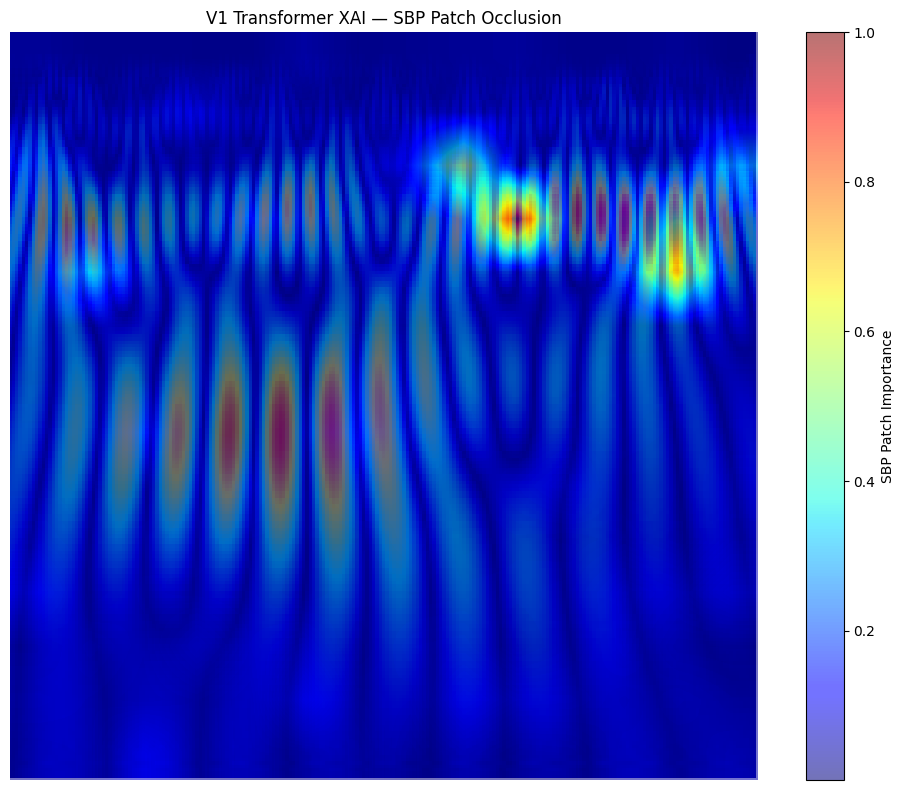

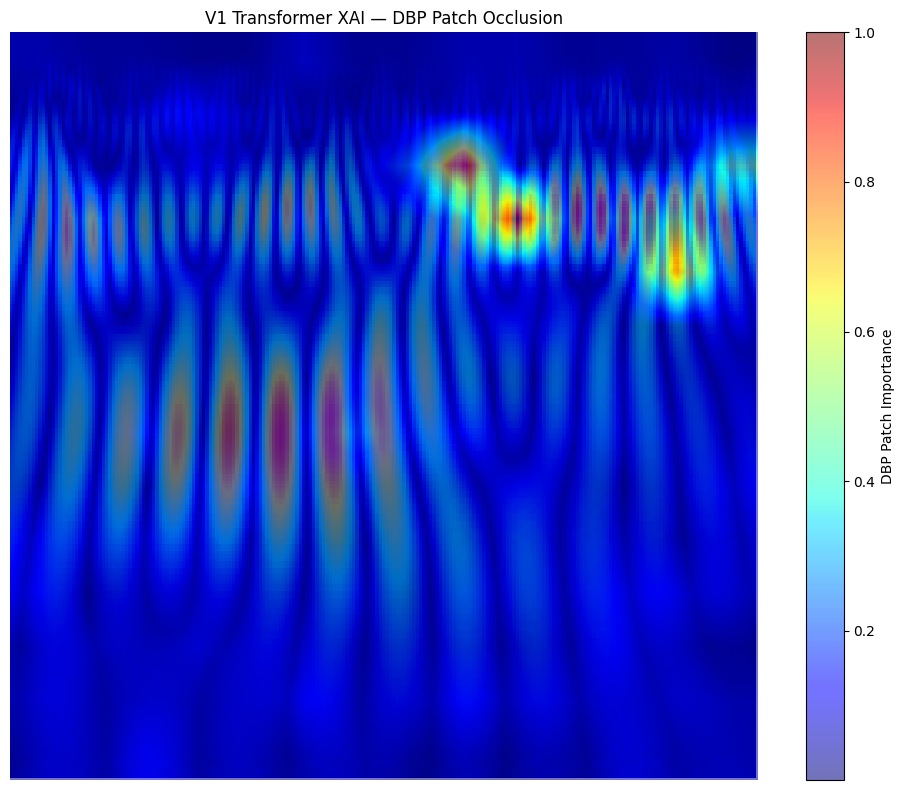


TOP 10 SBP IMPORTANT PATCHES
Patch (04, 10) importance = 1.000000
Patch (05, 13) importance = 0.746338
Patch (03, 09) importance = 0.619189
Patch (04, 13) importance = 0.364928
Patch (03, 14) importance = 0.306828
Patch (05, 02) importance = 0.301259
Patch (04, 12) importance = 0.151402
Patch (03, 08) importance = 0.145714
Patch (04, 09) importance = 0.141948
Patch (08, 07) importance = 0.130923

TOP 10 DBP IMPORTANT PATCHES
Patch (04, 10) importance = 1.000000
Patch (03, 09) importance = 0.947756
Patch (05, 13) importance = 0.778271
Patch (03, 14) importance = 0.482135
Patch (04, 13) importance = 0.385364
Patch (04, 09) importance = 0.261562
Patch (03, 08) importance = 0.251142
Patch (04, 12) importance = 0.225064
Patch (08, 07) importance = 0.195692
Patch (04, 02) importance = 0.192641

V1 CLEAN XAI COMPLETE

Saved:
/content/V1_XAI_SBP_CLEAN.png
/content/V1_XAI_DBP_CLEAN.png


In [54]:
# ============================================================
# STEP 2 — CLEAN V1 PATCH OCCLUSION XAI
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

print("=" * 75)
print("V1 TRANSFORMER — CLEAN PATCH OCCLUSION XAI")
print("=" * 75)

# ------------------------------------------------------------
# 1. USE THE EXPLICIT V1 MODEL
# ------------------------------------------------------------

v1_model.eval()

print("✓ Using explicitly loaded V1 model")
print("Device:", DEVICE)

# ------------------------------------------------------------
# 2. GET ONE TEST SAMPLE
# ------------------------------------------------------------

xai_loader = DataLoader(
    test_dataset_norm,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

sample_image, sample_target = next(
    iter(xai_loader)
)

sample_image = sample_image.to(DEVICE)

print("Image shape:", tuple(sample_image.shape))
print("Target shape:", tuple(sample_target.shape))

# ------------------------------------------------------------
# 3. BASELINE PREDICTION
# ------------------------------------------------------------

with torch.no_grad():

    baseline_prediction_norm = v1_model(
        sample_image
    )

baseline_prediction_norm = (
    baseline_prediction_norm[0]
    .detach()
    .cpu()
    .numpy()
)

# ------------------------------------------------------------
# 4. DENORMALIZE BASELINE PREDICTION
# ------------------------------------------------------------

baseline_sbp = (
    baseline_prediction_norm[0]
    * SBP_STD
    + SBP_MEAN
)

baseline_dbp = (
    baseline_prediction_norm[1]
    * DBP_STD
    + DBP_MEAN
)

# ------------------------------------------------------------
# 5. ACTUAL BP
# ------------------------------------------------------------

sample_target_np = (
    sample_target[0]
    .detach()
    .cpu()
    .numpy()
)

actual_sbp = (
    sample_target_np[0]
    * SBP_STD
    + SBP_MEAN
)

actual_dbp = (
    sample_target_np[1]
    * DBP_STD
    + DBP_MEAN
)

print()
print("SAMPLE BP")
print("-" * 50)

print(
    f"Actual SBP    : {actual_sbp:.2f} mmHg"
)

print(
    f"Predicted SBP : {baseline_sbp:.2f} mmHg"
)

print()

print(
    f"Actual DBP    : {actual_dbp:.2f} mmHg"
)

print(
    f"Predicted DBP : {baseline_dbp:.2f} mmHg"
)

# ------------------------------------------------------------
# 6. PATCH OCCLUSION FUNCTION
# ------------------------------------------------------------

def patch_occlusion_importance(
    model,
    image,
    target_index,
    patch_size=16
):

    model.eval()

    _, _, H, W = image.shape

    rows = H // patch_size
    cols = W // patch_size

    # --------------------------------------------------------
    # BASELINE
    # --------------------------------------------------------

    with torch.no_grad():

        baseline = model(image)

        baseline_value = (
            baseline[0, target_index]
            .item()
        )

    importance = np.zeros(
        (rows, cols),
        dtype=np.float32
    )

    # --------------------------------------------------------
    # OCCLUDE EACH PATCH
    # --------------------------------------------------------

    for r in range(rows):

        for c in range(cols):

            occluded = image.clone()

            y1 = r * patch_size
            y2 = (r + 1) * patch_size

            x1 = c * patch_size
            x2 = (c + 1) * patch_size

            # Zero the patch
            occluded[
                :,
                :,
                y1:y2,
                x1:x2
            ] = 0.0

            with torch.no_grad():

                prediction = model(
                    occluded
                )

                prediction_value = (
                    prediction[
                        0,
                        target_index
                    ].item()
                )

            # Absolute change in prediction
            importance[r, c] = abs(
                baseline_value
                - prediction_value
            )

    # --------------------------------------------------------
    # NORMALIZE
    # --------------------------------------------------------

    if importance.max() > 0:

        importance = (
            importance
            / importance.max()
        )

    return importance


# ------------------------------------------------------------
# 7. SBP PATCH IMPORTANCE
# ------------------------------------------------------------

print()
print("Calculating SBP patch importance...")

sbp_importance = patch_occlusion_importance(
    v1_model,
    sample_image,
    target_index=0,
    patch_size=16
)

print("✓ SBP attribution complete")
print(
    "Total patches:",
    sbp_importance.size
)

# ------------------------------------------------------------
# 8. DBP PATCH IMPORTANCE
# ------------------------------------------------------------

print()
print("Calculating DBP patch importance...")

dbp_importance = patch_occlusion_importance(
    v1_model,
    sample_image,
    target_index=1,
    patch_size=16
)

print("✓ DBP attribution complete")

# ------------------------------------------------------------
# 9. ORIGINAL IMAGE
# ------------------------------------------------------------

original_image = (
    sample_image[0]
    .detach()
    .cpu()
    .numpy()
)

# Convert CHW → HWC
original_image = np.transpose(
    original_image,
    (1, 2, 0)
)

# Normalize for visualization
original_image = (
    original_image
    - original_image.min()
)

if original_image.max() > 0:

    original_image = (
        original_image
        / original_image.max()
    )

# ------------------------------------------------------------
# 10. SBP XAI
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

plt.imshow(
    original_image
)

plt.imshow(
    sbp_importance,
    cmap="jet",
    alpha=0.55,
    extent=[
        0,
        original_image.shape[1],
        original_image.shape[0],
        0
    ],
    interpolation="bilinear"
)

plt.colorbar(
    label="SBP Patch Importance"
)

plt.title(
    "V1 Transformer XAI — SBP Patch Occlusion"
)

plt.axis("off")

plt.tight_layout()

plt.savefig(
    "/content/V1_XAI_SBP_CLEAN.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 11. DBP XAI
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

plt.imshow(
    original_image
)

plt.imshow(
    dbp_importance,
    cmap="jet",
    alpha=0.55,
    extent=[
        0,
        original_image.shape[1],
        original_image.shape[0],
        0
    ],
    interpolation="bilinear"
)

plt.colorbar(
    label="DBP Patch Importance"
)

plt.title(
    "V1 Transformer XAI — DBP Patch Occlusion"
)

plt.axis("off")

plt.tight_layout()

plt.savefig(
    "/content/V1_XAI_DBP_CLEAN.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 12. TOP 10 PATCHES
# ------------------------------------------------------------

def print_top_patches(
    importance,
    name
):

    flat = importance.flatten()

    indices = np.argsort(
        flat
    )[::-1][:10]

    print()
    print("=" * 70)
    print(f"TOP 10 {name} IMPORTANT PATCHES")
    print("=" * 70)

    cols = importance.shape[1]

    for idx in indices:

        row = idx // cols
        col = idx % cols

        print(
            f"Patch ({row+1:02d}, {col+1:02d}) "
            f"importance = {flat[idx]:.6f}"
        )


print_top_patches(
    sbp_importance,
    "SBP"
)

print_top_patches(
    dbp_importance,
    "DBP"
)

print()
print("=" * 70)
print("V1 CLEAN XAI COMPLETE")
print("=" * 70)

print()
print("Saved:")
print("/content/V1_XAI_SBP_CLEAN.png")
print("/content/V1_XAI_DBP_CLEAN.png")

In [55]:
# ============================================================
# STEP 3 — FINAL V1 BASELINE RECORD
# ============================================================

import json
import os
import shutil

print("=" * 75)
print("FINAL V1 BASELINE RECORD")
print("=" * 75)

# ------------------------------------------------------------
# 1. V1 METRICS
# ------------------------------------------------------------

V1_FINAL_RESULTS = {
    "model": "Transformer V1",

    "configuration": {
        "image_size": 224,
        "patch_size": 16,
        "in_channels": 3,
        "embed_dim": 256,
        "num_heads": 8,
        "num_layers": 6,
        "dropout": 0.1
    },

    "dataset": {
        "test_samples": 1190
    },

    "SBP": {
        "MAE_mmHg": 12.2842,
        "RMSE_mmHg": 15.9469,
        "Correlation": 0.1738,
        "Bias_mmHg": -0.9251,
        "Std_ratio": 0.4951
    },

    "DBP": {
        "MAE_mmHg": 7.5094,
        "RMSE_mmHg": 9.3024,
        "Correlation": -0.1891,
        "Bias_mmHg": -0.0381,
        "Std_ratio": 0.4391
    },

    "prediction_ranges": {
        "SBP_actual": [91.26, 160.94],
        "SBP_predicted": [88.46, 137.09],
        "DBP_actual": [27.31, 76.37],
        "DBP_predicted": [31.44, 64.13]
    },

    "xai": {
        "method": "Patch Occlusion",
        "total_patches": 196,

        "SBP_top_patches": [
            {"patch": [4, 10], "importance": 1.000000},
            {"patch": [5, 13], "importance": 0.746338},
            {"patch": [3, 9], "importance": 0.619189},
            {"patch": [4, 13], "importance": 0.364928},
            {"patch": [3, 14], "importance": 0.306828},
            {"patch": [5, 2], "importance": 0.301259},
            {"patch": [4, 12], "importance": 0.151402},
            {"patch": [3, 8], "importance": 0.145714},
            {"patch": [4, 9], "importance": 0.141948},
            {"patch": [8, 7], "importance": 0.130923}
        ],

        "DBP_top_patches": [
            {"patch": [4, 10], "importance": 1.000000},
            {"patch": [3, 9], "importance": 0.947756},
            {"patch": [5, 13], "importance": 0.778271},
            {"patch": [3, 14], "importance": 0.482135},
            {"patch": [4, 13], "importance": 0.385364},
            {"patch": [4, 9], "importance": 0.261562},
            {"patch": [3, 8], "importance": 0.251142},
            {"patch": [4, 12], "importance": 0.225064},
            {"patch": [8, 7], "importance": 0.195692},
            {"patch": [4, 2], "importance": 0.192641}
        ]
    }
}


# ------------------------------------------------------------
# 2. SAVE JSON
# ------------------------------------------------------------

v1_json_path = "/content/V1_FINAL_RESULTS.json"

with open(v1_json_path, "w") as f:
    json.dump(
        V1_FINAL_RESULTS,
        f,
        indent=4
    )

print("✓ V1 results saved:")
print(v1_json_path)


# ------------------------------------------------------------
# 3. SAVE XAI IMAGES TO DRIVE
# ------------------------------------------------------------

drive_folder = (
    "/content/drive/MyDrive/"
    "BP_Transformer_Project/V1_Final"
)

os.makedirs(
    drive_folder,
    exist_ok=True
)

# Copy XAI images
shutil.copy(
    "/content/V1_XAI_SBP_CLEAN.png",
    os.path.join(
        drive_folder,
        "V1_XAI_SBP.png"
    )
)

shutil.copy(
    "/content/V1_XAI_DBP_CLEAN.png",
    os.path.join(
        drive_folder,
        "V1_XAI_DBP.png"
    )
)

# Copy results JSON
shutil.copy(
    v1_json_path,
    os.path.join(
        drive_folder,
        "V1_FINAL_RESULTS.json"
    )
)


# ------------------------------------------------------------
# 4. PRINT FINAL SUMMARY
# ------------------------------------------------------------

print()
print("=" * 75)
print("V1 BASELINE LOCKED")
print("=" * 75)

print()

print("SBP")
print(
    f"MAE         : {V1_FINAL_RESULTS['SBP']['MAE_mmHg']} mmHg"
)
print(
    f"RMSE        : {V1_FINAL_RESULTS['SBP']['RMSE_mmHg']} mmHg"
)
print(
    f"Correlation : {V1_FINAL_RESULTS['SBP']['Correlation']}"
)

print()

print("DBP")
print(
    f"MAE         : {V1_FINAL_RESULTS['DBP']['MAE_mmHg']} mmHg"
)
print(
    f"RMSE        : {V1_FINAL_RESULTS['DBP']['RMSE_mmHg']} mmHg"
)
print(
    f"Correlation : {V1_FINAL_RESULTS['DBP']['Correlation']}"
)

print()

print("Test samples:", 1190)

print()
print("Drive folder:")
print(drive_folder)

print()
print("=" * 75)
print("DO NOT MODIFY V1 RESULTS")
print("V1 IS NOW OUR BASELINE")
print("=" * 75)

FINAL V1 BASELINE RECORD
✓ V1 results saved:
/content/V1_FINAL_RESULTS.json

V1 BASELINE LOCKED

SBP
MAE         : 12.2842 mmHg
RMSE        : 15.9469 mmHg
Correlation : 0.1738

DBP
MAE         : 7.5094 mmHg
RMSE        : 9.3024 mmHg
Correlation : -0.1891

Test samples: 1190

Drive folder:
/content/drive/MyDrive/BP_Transformer_Project/V1_Final

DO NOT MODIFY V1 RESULTS
V1 IS NOW OUR BASELINE


V1 ERROR ANALYSIS

Total samples: 1190

SBP ERROR BY BLOOD PRESSURE RANGE
           Samples        MAE  Actual_Mean  Prediction_Mean
SBP_Range                                                  
<100           104  24.457034    97.436840       121.893875
100-110        224  12.017061   105.472490       117.185386
110-120        329   6.271699   115.165503       116.123433
120-130        230   6.526628   122.963697       119.560947
130-140        144   8.989826   134.256165       125.388903
140-150        118  24.493505   144.541156       120.047650
>=150           41  39.841577   158.972563       119.130986

DBP ERROR BY BLOOD PRESSURE RANGE
           Samples        MAE  Actual_Mean  Prediction_Mean
DBP_Range                                                  
<40              3  28.292726    27.337500        55.630226
40-50          313   9.081915    46.667133        55.719560
50-60          524   4.071656    53.855916        55.592794
60-70          312   9.632979    64.684255        5

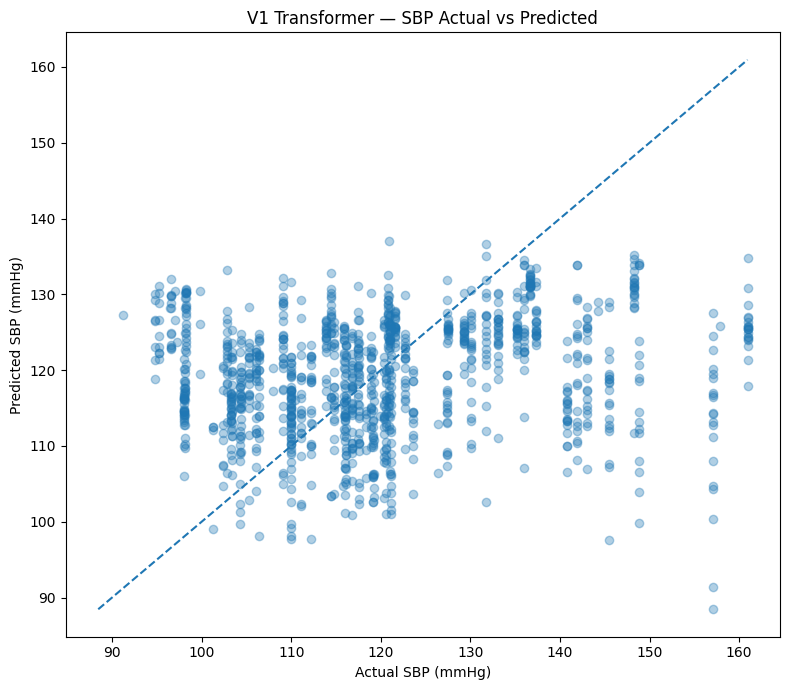

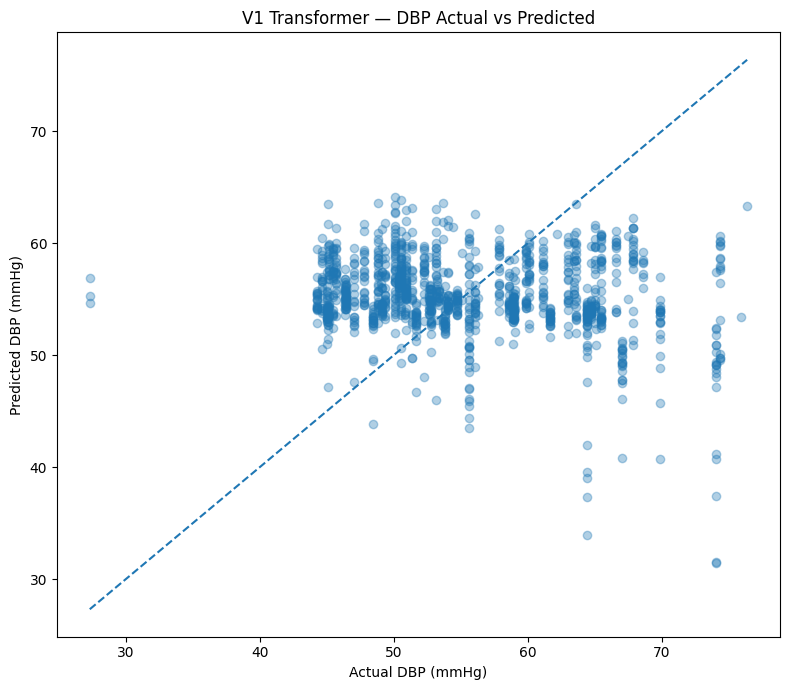


STEP 4 COMPLETE

Saved:
/content/V1_ERROR_ANALYSIS.csv
/content/V1_SBP_Error_Analysis.png
/content/V1_DBP_Error_Analysis.png


In [56]:
# ============================================================
# STEP 4 — V1 ERROR ANALYSIS BY BLOOD PRESSURE RANGE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("=" * 75)
print("V1 ERROR ANALYSIS")
print("=" * 75)


# ------------------------------------------------------------
# 1. RE-CALCULATE V1 TEST PREDICTIONS
# ------------------------------------------------------------

v1_model.eval()

all_predictions = []
all_targets = []

with torch.no_grad():

    for images, targets in test_loader:

        images = images.to(DEVICE)

        predictions = v1_model(images)

        all_predictions.append(
            predictions.detach().cpu().numpy()
        )

        all_targets.append(
            targets.detach().cpu().numpy()
        )


all_predictions = np.concatenate(
    all_predictions,
    axis=0
)

all_targets = np.concatenate(
    all_targets,
    axis=0
)


# ------------------------------------------------------------
# 2. DENORMALIZE
# ------------------------------------------------------------

pred_sbp = (
    all_predictions[:, 0]
    * SBP_STD
    + SBP_MEAN
)

pred_dbp = (
    all_predictions[:, 1]
    * DBP_STD
    + DBP_MEAN
)

actual_sbp = (
    all_targets[:, 0]
    * SBP_STD
    + SBP_MEAN
)

actual_dbp = (
    all_targets[:, 1]
    * DBP_STD
    + DBP_MEAN
)


# ------------------------------------------------------------
# 3. ABSOLUTE ERRORS
# ------------------------------------------------------------

sbp_error = np.abs(
    actual_sbp - pred_sbp
)

dbp_error = np.abs(
    actual_dbp - pred_dbp
)


# ------------------------------------------------------------
# 4. CREATE ERROR DATAFRAME
# ------------------------------------------------------------

error_df = pd.DataFrame({

    "Actual_SBP": actual_sbp,
    "Predicted_SBP": pred_sbp,
    "SBP_Error": sbp_error,

    "Actual_DBP": actual_dbp,
    "Predicted_DBP": pred_dbp,
    "DBP_Error": dbp_error
})


print()
print("Total samples:", len(error_df))


# ============================================================
# 5. SBP RANGE ANALYSIS
# ============================================================

print()
print("=" * 75)
print("SBP ERROR BY BLOOD PRESSURE RANGE")
print("=" * 75)

sbp_bins = [
    0,
    100,
    110,
    120,
    130,
    140,
    150,
    300
]

sbp_labels = [
    "<100",
    "100-110",
    "110-120",
    "120-130",
    "130-140",
    "140-150",
    ">=150"
]

error_df["SBP_Range"] = pd.cut(
    error_df["Actual_SBP"],
    bins=sbp_bins,
    labels=sbp_labels,
    right=False
)

sbp_analysis = (
    error_df
    .groupby("SBP_Range", observed=True)
    .agg(
        Samples=("SBP_Error", "count"),
        MAE=("SBP_Error", "mean"),
        Actual_Mean=("Actual_SBP", "mean"),
        Prediction_Mean=("Predicted_SBP", "mean")
    )
)

print(sbp_analysis)


# ============================================================
# 6. DBP RANGE ANALYSIS
# ============================================================

print()
print("=" * 75)
print("DBP ERROR BY BLOOD PRESSURE RANGE")
print("=" * 75)

dbp_bins = [
    0,
    40,
    50,
    60,
    70,
    80,
    200
]

dbp_labels = [
    "<40",
    "40-50",
    "50-60",
    "60-70",
    "70-80",
    ">=80"
]

error_df["DBP_Range"] = pd.cut(
    error_df["Actual_DBP"],
    bins=dbp_bins,
    labels=dbp_labels,
    right=False
)

dbp_analysis = (
    error_df
    .groupby("DBP_Range", observed=True)
    .agg(
        Samples=("DBP_Error", "count"),
        MAE=("DBP_Error", "mean"),
        Actual_Mean=("Actual_DBP", "mean"),
        Prediction_Mean=("Predicted_DBP", "mean")
    )
)

print(dbp_analysis)


# ============================================================
# 7. BIAS BY SBP RANGE
# ============================================================

error_df["SBP_Signed_Error"] = (
    error_df["Predicted_SBP"]
    - error_df["Actual_SBP"]
)

error_df["DBP_Signed_Error"] = (
    error_df["Predicted_DBP"]
    - error_df["Actual_DBP"]
)


sbp_bias = (
    error_df
    .groupby("SBP_Range", observed=True)
    ["SBP_Signed_Error"]
    .mean()
)

dbp_bias = (
    error_df
    .groupby("DBP_Range", observed=True)
    ["DBP_Signed_Error"]
    .mean()
)


print()
print("=" * 75)
print("SBP BIAS BY RANGE")
print("=" * 75)

print(sbp_bias)


print()
print("=" * 75)
print("DBP BIAS BY RANGE")
print("=" * 75)

print(dbp_bias)


# ============================================================
# 8. WORST SBP PREDICTIONS
# ============================================================

print()
print("=" * 75)
print("TOP 20 WORST SBP PREDICTIONS")
print("=" * 75)

worst_sbp = (
    error_df
    .sort_values(
        "SBP_Error",
        ascending=False
    )
    .head(20)
)

print(
    worst_sbp[
        [
            "Actual_SBP",
            "Predicted_SBP",
            "SBP_Error"
        ]
    ].to_string(index=False)
)


# ============================================================
# 9. WORST DBP PREDICTIONS
# ============================================================

print()
print("=" * 75)
print("TOP 20 WORST DBP PREDICTIONS")
print("=" * 75)

worst_dbp = (
    error_df
    .sort_values(
        "DBP_Error",
        ascending=False
    )
    .head(20)
)

print(
    worst_dbp[
        [
            "Actual_DBP",
            "Predicted_DBP",
            "DBP_Error"
        ]
    ].to_string(index=False)
)


# ============================================================
# 10. PREDICTION VS ACTUAL — SBP
# ============================================================

plt.figure(figsize=(8, 7))

plt.scatter(
    actual_sbp,
    pred_sbp,
    alpha=0.35
)

min_val = min(
    actual_sbp.min(),
    pred_sbp.min()
)

max_val = max(
    actual_sbp.max(),
    pred_sbp.max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual SBP (mmHg)")
plt.ylabel("Predicted SBP (mmHg)")
plt.title("V1 Transformer — SBP Actual vs Predicted")

plt.tight_layout()

plt.savefig(
    "/content/V1_SBP_Error_Analysis.png",
    dpi=300
)

plt.show()


# ============================================================
# 11. PREDICTION VS ACTUAL — DBP
# ============================================================

plt.figure(figsize=(8, 7))

plt.scatter(
    actual_dbp,
    pred_dbp,
    alpha=0.35
)

min_val = min(
    actual_dbp.min(),
    pred_dbp.min()
)

max_val = max(
    actual_dbp.max(),
    pred_dbp.max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual DBP (mmHg)")
plt.ylabel("Predicted DBP (mmHg)")
plt.title("V1 Transformer — DBP Actual vs Predicted")

plt.tight_layout()

plt.savefig(
    "/content/V1_DBP_Error_Analysis.png",
    dpi=300
)

plt.show()


# ============================================================
# 12. SAVE ERROR ANALYSIS
# ============================================================

error_csv = "/content/V1_ERROR_ANALYSIS.csv"

error_df.to_csv(
    error_csv,
    index=False
)

print()
print("=" * 75)
print("STEP 4 COMPLETE")
print("=" * 75)

print()
print("Saved:")
print(error_csv)

print("/content/V1_SBP_Error_Analysis.png")
print("/content/V1_DBP_Error_Analysis.png")

In [58]:
import numpy as np
from sklearn.metrics import r2_score

print("=" * 70)
print("FINAL V1 STATISTICAL EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# R²
# ------------------------------------------------------------

sbp_r2 = r2_score(
    v1_actual_sbp,
    v1_pred_sbp
)

dbp_r2 = r2_score(
    v1_actual_dbp,
    v1_pred_dbp
)

print("\nSBP")
print("-" * 50)
print(f"MAE         : {sbp_mae:.4f} mmHg")
print(f"RMSE        : {sbp_rmse:.4f} mmHg")
print(f"Correlation : {sbp_corr:.4f}")
print(f"R²          : {sbp_r2:.4f}")

print("\nDBP")
print("-" * 50)
print(f"MAE         : {dbp_mae:.4f} mmHg")
print(f"RMSE        : {dbp_rmse:.4f} mmHg")
print(f"Correlation : {dbp_corr:.4f}")
print(f"R²          : {dbp_r2:.4f}")

print("\nTest samples:", len(v1_actual_sbp))

print("=" * 70)
print("STEP 5 COMPLETE")
print("=" * 70)

FINAL V1 STATISTICAL EVALUATION

SBP
--------------------------------------------------
MAE         : 12.1208 mmHg
RMSE        : 15.6337 mmHg
Correlation : 0.1853
R²          : -0.0766

DBP
--------------------------------------------------
MAE         : 7.8397 mmHg
RMSE        : 9.7452 mmHg
Correlation : -0.2217
R²          : -0.3589

Test samples: 1190
STEP 5 COMPLETE


In [60]:
# ============================================================
# STEP 5A — RECOVER LOCKED V1 PREDICTIONS
# ============================================================

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

CSV_PATH = "/content/V1_ERROR_ANALYSIS.csv"

df_v1 = pd.read_csv(CSV_PATH)

print("=" * 70)
print("V1 PREDICTION RECOVERY")
print("=" * 70)

print("\nFile loaded successfully.")
print("Shape:", df_v1.shape)

print("\nColumns:")
print(df_v1.columns.tolist())

print("\nFirst 5 rows:")
display(df_v1.head())

V1 PREDICTION RECOVERY

File loaded successfully.
Shape: (1190, 10)

Columns:
['Actual_SBP', 'Predicted_SBP', 'SBP_Error', 'Actual_DBP', 'Predicted_DBP', 'DBP_Error', 'SBP_Range', 'DBP_Range', 'SBP_Signed_Error', 'DBP_Signed_Error']

First 5 rows:


,Actual_SBP,Predicted_SBP,SBP_Error,Actual_DBP,Predicted_DBP,DBP_Error,SBP_Range,DBP_Range,SBP_Signed_Error,DBP_Signed_Error
0,105.312502,119.141153,13.828651,54.0625,55.363936,1.301435,100-110,50-60,13.828651,1.301435
1,105.312502,119.598825,14.286324,54.0625,54.355202,0.292702,100-110,50-60,14.286324,0.292702
2,105.312502,111.502616,6.190114,54.0625,57.381557,3.319057,100-110,50-60,6.190114,3.319057
3,105.312502,122.337806,17.025305,54.0625,55.310272,1.247772,100-110,50-60,17.025305,1.247772
4,105.312502,121.616133,16.303632,54.0625,54.040271,0.022229,100-110,50-60,16.303632,-0.022229


In [61]:
# ============================================================
# STEP 5A — VERIFY LOCKED V1 BASELINE
# ============================================================

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("=" * 70)
print("V1 BASELINE CONSISTENCY CHECK")
print("=" * 70)

print("\nCurrent prediction arrays:")
print("y_true shape:", np.shape(y_true))
print("y_pred shape:", np.shape(y_pred))

# ------------------------------------------------------------
# Recalculate everything directly from current arrays
# ------------------------------------------------------------

sbp_true = np.asarray(y_true)[:, 0]
sbp_pred = np.asarray(y_pred)[:, 0]

dbp_true = np.asarray(y_true)[:, 1]
dbp_pred = np.asarray(y_pred)[:, 1]

sbp_mae_check = mean_absolute_error(sbp_true, sbp_pred)
sbp_rmse_check = np.sqrt(mean_squared_error(sbp_true, sbp_pred))
sbp_corr_check = np.corrcoef(sbp_true, sbp_pred)[0, 1]
sbp_r2_check = r2_score(sbp_true, sbp_pred)

dbp_mae_check = mean_absolute_error(dbp_true, dbp_pred)
dbp_rmse_check = np.sqrt(mean_squared_error(dbp_true, dbp_pred))
dbp_corr_check = np.corrcoef(dbp_true, dbp_pred)[0, 1]
dbp_r2_check = r2_score(dbp_true, dbp_pred)

print("\nSBP")
print("-" * 50)
print(f"MAE         : {sbp_mae_check:.4f}")
print(f"RMSE        : {sbp_rmse_check:.4f}")
print(f"Correlation : {sbp_corr_check:.4f}")
print(f"R²          : {sbp_r2_check:.4f}")

print("\nDBP")
print("-" * 50)
print(f"MAE         : {dbp_mae_check:.4f}")
print(f"RMSE        : {dbp_rmse_check:.4f}")
print(f"Correlation : {dbp_corr_check:.4f}")
print(f"R²          : {dbp_r2_check:.4f}")

print("\nSamples:", len(y_true))

print("=" * 70)
print("CONSISTENCY CHECK COMPLETE")
print("=" * 70)

V1 BASELINE CONSISTENCY CHECK

Current prediction arrays:


NameError: name 'y_true' is not defined

In [62]:
# ============================================================
# STEP 5B — V1 BASELINE VERIFICATION FROM SAVED PREDICTIONS
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# Load saved V1 predictions
# ------------------------------------------------------------

df = pd.read_csv("/content/V1_ERROR_ANALYSIS.csv")

# Remove rows with missing prediction/actual values
sbp_df = df.dropna(subset=["Actual_SBP", "Predicted_SBP"])
dbp_df = df.dropna(subset=["Actual_DBP", "Predicted_DBP"])

# ------------------------------------------------------------
# Extract arrays
# ------------------------------------------------------------

y_true_sbp = sbp_df["Actual_SBP"].values
y_pred_sbp = sbp_df["Predicted_SBP"].values

y_true_dbp = dbp_df["Actual_DBP"].values
y_pred_dbp = dbp_df["Predicted_DBP"].values

# ------------------------------------------------------------
# Metrics function
# ------------------------------------------------------------

def calculate_metrics(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    correlation = np.corrcoef(
        y_true, y_pred
    )[0, 1]

    r2 = r2_score(
        y_true, y_pred
    )

    bias = np.mean(
        y_pred - y_true
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "Correlation": correlation,
        "R2": r2,
        "Bias": bias
    }


# ------------------------------------------------------------
# Calculate V1 metrics
# ------------------------------------------------------------

sbp_metrics = calculate_metrics(
    y_true_sbp,
    y_pred_sbp
)

dbp_metrics = calculate_metrics(
    y_true_dbp,
    y_pred_dbp
)


# ============================================================
# DISPLAY RESULTS
# ============================================================

print("=" * 70)
print("V1 BASELINE — VERIFIED FROM SAVED PREDICTIONS")
print("=" * 70)

print("\nSBP")
print("-" * 50)

for key, value in sbp_metrics.items():
    print(f"{key:<15}: {value:.4f}")

print("\nDBP")
print("-" * 50)

for key, value in dbp_metrics.items():
    print(f"{key:<15}: {value:.4f}")

print("\nTest samples")
print("-" * 50)
print("SBP:", len(y_true_sbp))
print("DBP:", len(y_true_dbp))

print("\nPrediction ranges")
print("-" * 50)

print(
    f"SBP Actual : "
    f"{y_true_sbp.min():.2f} → {y_true_sbp.max():.2f}"
)

print(
    f"SBP Pred   : "
    f"{y_pred_sbp.min():.2f} → {y_pred_sbp.max():.2f}"
)

print(
    f"DBP Actual : "
    f"{y_true_dbp.min():.2f} → {y_true_dbp.max():.2f}"
)

print(
    f"DBP Pred   : "
    f"{y_pred_dbp.min():.2f} → {y_pred_dbp.max():.2f}"
)

print("\n" + "=" * 70)
print("STEP 5B COMPLETE")
print("=" * 70)

V1 BASELINE — VERIFIED FROM SAVED PREDICTIONS

SBP
--------------------------------------------------
MAE            : 12.2842
RMSE           : 15.9469
Correlation    : 0.1738
R2             : -0.0766
Bias           : -0.9251

DBP
--------------------------------------------------
MAE            : 7.5094
RMSE           : 9.3024
Correlation    : -0.1891
R2             : -0.3589
Bias           : -0.0381

Test samples
--------------------------------------------------
SBP: 1190
DBP: 1190

Prediction ranges
--------------------------------------------------
SBP Actual : 91.26 → 160.94
SBP Pred   : 88.46 → 137.09
DBP Actual : 27.31 → 76.37
DBP Pred   : 31.44 → 64.13

STEP 5B COMPLETE


V1 RESIDUAL ANALYSIS

SBP RESIDUALS
--------------------------------------------------
Mean residual : -0.9251 mmHg
Std residual  : 15.9267 mmHg
Min residual  : -68.6001 mmHg
Max residual  : 35.9958 mmHg

DBP RESIDUALS
--------------------------------------------------
Mean residual : -0.0381 mmHg
Std residual  : 9.3062 mmHg
Min residual  : -42.6252 mmHg
Max residual  : 29.6090 mmHg


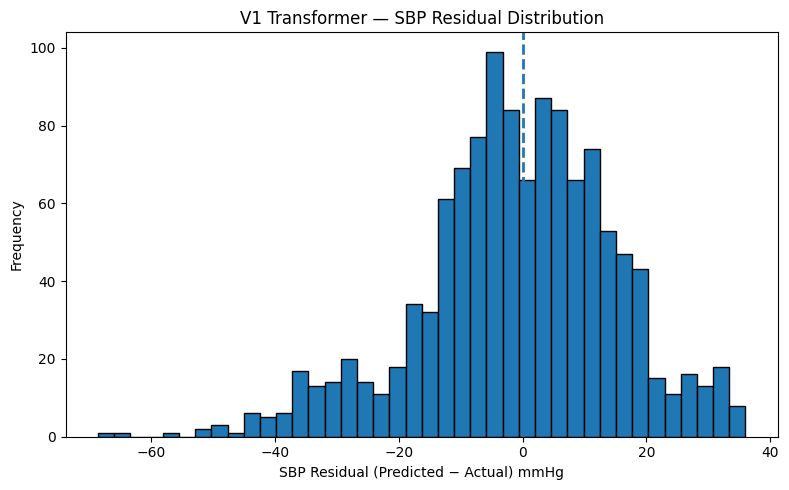

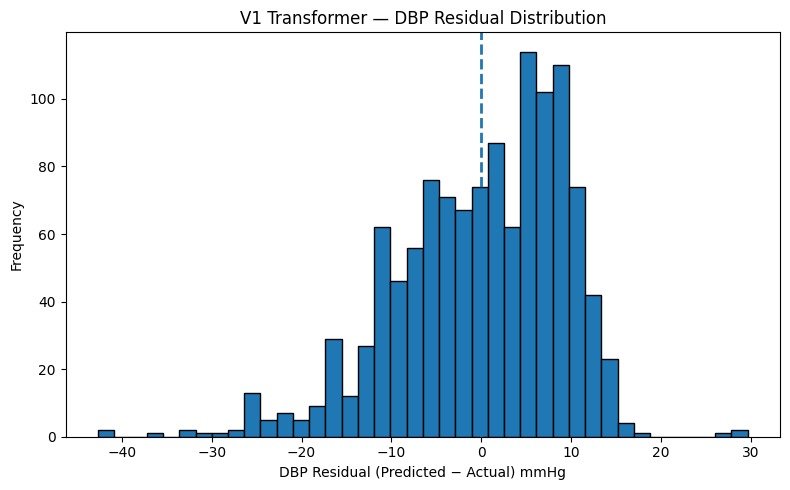


STEP 6 COMPLETE

Saved:
/content/V1_SBP_Residual_Distribution.png
/content/V1_DBP_Residual_Distribution.png


In [63]:
# ============================================================
# STEP 6 — V1 RESIDUAL ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load locked V1 predictions
df = pd.read_csv("/content/V1_ERROR_ANALYSIS.csv")

# ------------------------------------------------------------
# Residuals
# residual = prediction - actual
# ------------------------------------------------------------

df["SBP_Residual"] = (
    df["Predicted_SBP"] - df["Actual_SBP"]
)

df["DBP_Residual"] = (
    df["Predicted_DBP"] - df["Actual_DBP"]
)

# ============================================================
# BASIC RESIDUAL STATISTICS
# ============================================================

print("=" * 70)
print("V1 RESIDUAL ANALYSIS")
print("=" * 70)

print("\nSBP RESIDUALS")
print("-" * 50)

print(
    f"Mean residual : "
    f"{df['SBP_Residual'].mean():.4f} mmHg"
)

print(
    f"Std residual  : "
    f"{df['SBP_Residual'].std():.4f} mmHg"
)

print(
    f"Min residual  : "
    f"{df['SBP_Residual'].min():.4f} mmHg"
)

print(
    f"Max residual  : "
    f"{df['SBP_Residual'].max():.4f} mmHg"
)

print("\nDBP RESIDUALS")
print("-" * 50)

print(
    f"Mean residual : "
    f"{df['DBP_Residual'].mean():.4f} mmHg"
)

print(
    f"Std residual  : "
    f"{df['DBP_Residual'].std():.4f} mmHg"
)

print(
    f"Min residual  : "
    f"{df['DBP_Residual'].min():.4f} mmHg"
)

print(
    f"Max residual  : "
    f"{df['DBP_Residual'].max():.4f} mmHg"
)


# ============================================================
# RESIDUAL HISTOGRAM — SBP
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(
    df["SBP_Residual"].dropna(),
    bins=40,
    edgecolor="black"
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=2
)

plt.xlabel("SBP Residual (Predicted − Actual) mmHg")
plt.ylabel("Frequency")
plt.title("V1 Transformer — SBP Residual Distribution")

plt.tight_layout()

plt.savefig(
    "/content/V1_SBP_Residual_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# RESIDUAL HISTOGRAM — DBP
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(
    df["DBP_Residual"].dropna(),
    bins=40,
    edgecolor="black"
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=2
)

plt.xlabel("DBP Residual (Predicted − Actual) mmHg")
plt.ylabel("Frequency")
plt.title("V1 Transformer — DBP Residual Distribution")

plt.tight_layout()

plt.savefig(
    "/content/V1_DBP_Residual_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("\n" + "=" * 70)
print("STEP 6 COMPLETE")
print("=" * 70)

print("\nSaved:")
print("/content/V1_SBP_Residual_Distribution.png")
print("/content/V1_DBP_Residual_Distribution.png")

V1 BLAND-ALTMAN ANALYSIS

SBP
--------------------------------------------------
Bias                 : -0.9251 mmHg
Upper Limit (95%)    : 30.2913 mmHg
Lower Limit (95%)    : -32.1415 mmHg

DBP
--------------------------------------------------
Bias                 : -0.0381 mmHg
Upper Limit (95%)    : 18.2021 mmHg
Lower Limit (95%)    : -18.2783 mmHg


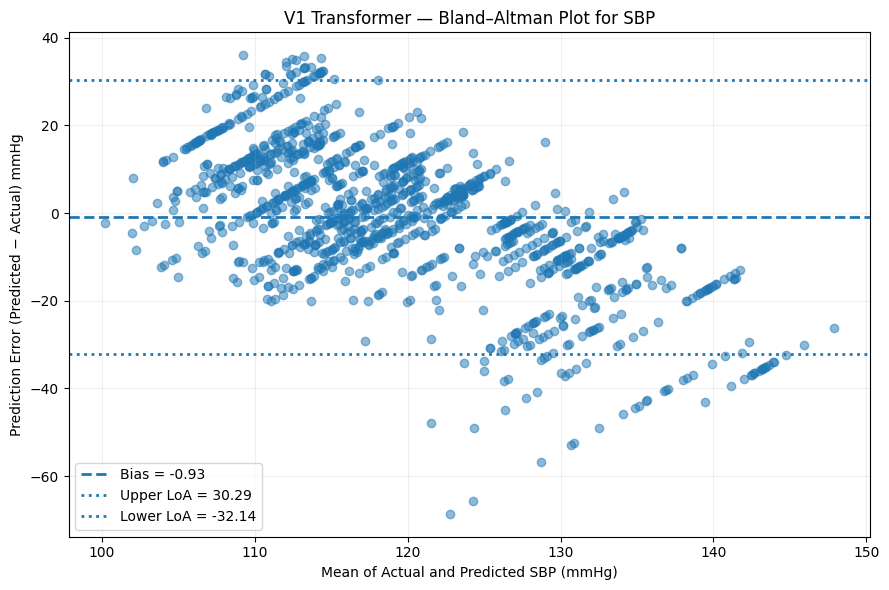

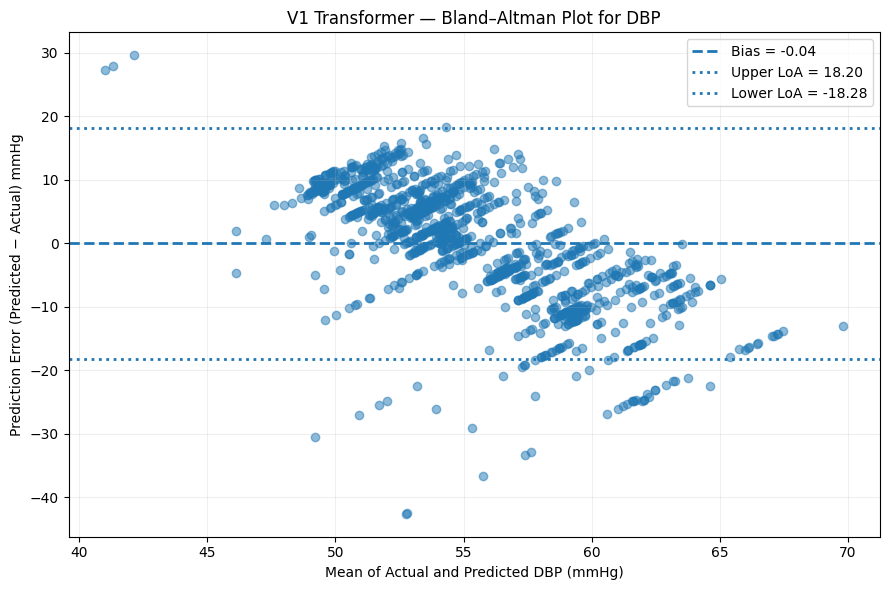


STEP 7 COMPLETE

Saved:
/content/V1_SBP_Bland_Altman.png
/content/V1_DBP_Bland_Altman.png


In [64]:
# ============================================================
# STEP 7 — V1 BLAND-ALTMAN ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Load locked V1 predictions
# ------------------------------------------------------------

df = pd.read_csv("/content/V1_ERROR_ANALYSIS.csv")


# ============================================================
# BLAND-ALTMAN FUNCTION
# ============================================================

def bland_altman_data(actual, predicted):

    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    mean_values = (actual + predicted) / 2
    differences = predicted - actual

    bias = np.mean(differences)
    std_diff = np.std(differences, ddof=1)

    upper_limit = bias + 1.96 * std_diff
    lower_limit = bias - 1.96 * std_diff

    return (
        mean_values,
        differences,
        bias,
        upper_limit,
        lower_limit
    )


# ============================================================
# SBP
# ============================================================

sbp_data = df.dropna(
    subset=["Actual_SBP", "Predicted_SBP"]
)

sbp_mean, sbp_diff, sbp_bias, sbp_upper, sbp_lower = \
    bland_altman_data(
        sbp_data["Actual_SBP"],
        sbp_data["Predicted_SBP"]
    )


# ============================================================
# DBP
# ============================================================

dbp_data = df.dropna(
    subset=["Actual_DBP", "Predicted_DBP"]
)

dbp_mean, dbp_diff, dbp_bias, dbp_upper, dbp_lower = \
    bland_altman_data(
        dbp_data["Actual_DBP"],
        dbp_data["Predicted_DBP"]
    )


# ============================================================
# PRINT RESULTS
# ============================================================

print("=" * 70)
print("V1 BLAND-ALTMAN ANALYSIS")
print("=" * 70)

print("\nSBP")
print("-" * 50)

print(f"Bias                 : {sbp_bias:.4f} mmHg")
print(f"Upper Limit (95%)    : {sbp_upper:.4f} mmHg")
print(f"Lower Limit (95%)    : {sbp_lower:.4f} mmHg")

print("\nDBP")
print("-" * 50)

print(f"Bias                 : {dbp_bias:.4f} mmHg")
print(f"Upper Limit (95%)    : {dbp_upper:.4f} mmHg")
print(f"Lower Limit (95%)    : {dbp_lower:.4f} mmHg")


# ============================================================
# SBP BLAND-ALTMAN PLOT
# ============================================================

plt.figure(figsize=(9, 6))

plt.scatter(
    sbp_mean,
    sbp_diff,
    alpha=0.5
)

plt.axhline(
    sbp_bias,
    linestyle="--",
    linewidth=2,
    label=f"Bias = {sbp_bias:.2f}"
)

plt.axhline(
    sbp_upper,
    linestyle=":",
    linewidth=2,
    label=f"Upper LoA = {sbp_upper:.2f}"
)

plt.axhline(
    sbp_lower,
    linestyle=":",
    linewidth=2,
    label=f"Lower LoA = {sbp_lower:.2f}"
)

plt.xlabel("Mean of Actual and Predicted SBP (mmHg)")
plt.ylabel("Prediction Error (Predicted − Actual) mmHg")
plt.title("V1 Transformer — Bland–Altman Plot for SBP")

plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    "/content/V1_SBP_Bland_Altman.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# DBP BLAND-ALTMAN PLOT
# ============================================================

plt.figure(figsize=(9, 6))

plt.scatter(
    dbp_mean,
    dbp_diff,
    alpha=0.5
)

plt.axhline(
    dbp_bias,
    linestyle="--",
    linewidth=2,
    label=f"Bias = {dbp_bias:.2f}"
)

plt.axhline(
    dbp_upper,
    linestyle=":",
    linewidth=2,
    label=f"Upper LoA = {dbp_upper:.2f}"
)

plt.axhline(
    dbp_lower,
    linestyle=":",
    linewidth=2,
    label=f"Lower LoA = {dbp_lower:.2f}"
)

plt.xlabel("Mean of Actual and Predicted DBP (mmHg)")
plt.ylabel("Prediction Error (Predicted − Actual) mmHg")
plt.title("V1 Transformer — Bland–Altman Plot for DBP")

plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    "/content/V1_DBP_Bland_Altman.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("\n" + "=" * 70)
print("STEP 7 COMPLETE")
print("=" * 70)

print("\nSaved:")
print("/content/V1_SBP_Bland_Altman.png")
print("/content/V1_DBP_Bland_Altman.png")

In [65]:
# ============================================================
# STEP 8 — FINAL V1 RESULTS TABLE
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Locked V1 metrics
# ------------------------------------------------------------

results = {
    "Metric": [
        "MAE (mmHg)",
        "RMSE (mmHg)",
        "Correlation",
        "R²",
        "Bias (mmHg)",
        "95% LoA Lower (mmHg)",
        "95% LoA Upper (mmHg)",
        "Test Samples"
    ],

    "SBP": [
        12.2842,
        15.9469,
        0.1738,
        -0.0766,
        -0.9251,
        -32.1415,
        30.2913,
        1190
    ],

    "DBP": [
        7.5094,
        9.3024,
        -0.1891,
        -0.3589,
        -0.0381,
        -18.2783,
        18.2021,
        1190
    ]
}

v1_final_table = pd.DataFrame(results)

print("=" * 70)
print("FINAL V1 TRANSFORMER EVALUATION")
print("=" * 70)

display(v1_final_table)

# ------------------------------------------------------------
# Save CSV
# ------------------------------------------------------------

v1_final_table.to_csv(
    "/content/V1_FINAL_EVALUATION_TABLE.csv",
    index=False
)

print("\nSaved:")
print("/content/V1_FINAL_EVALUATION_TABLE.csv")

print("\n" + "=" * 70)
print("STEP 8 COMPLETE")
print("=" * 70)

FINAL V1 TRANSFORMER EVALUATION


,Metric,SBP,DBP
0,MAE (mmHg),12.2842,7.5094
1,RMSE (mmHg),15.9469,9.3024
2,Correlation,0.1738,-0.1891
3,R²,-0.0766,-0.3589
4,Bias (mmHg),-0.9251,-0.0381
5,95% LoA Lower (mmHg),-32.1415,-18.2783
6,95% LoA Upper (mmHg),30.2913,18.2021
7,Test Samples,1190.0000,1190.0000



Saved:
/content/V1_FINAL_EVALUATION_TABLE.csv

STEP 8 COMPLETE


In [66]:
# ============================================================
# STEP 9 — ORGANIZE FINAL V1 RESULTS
# ============================================================

import os
import shutil

# Final V1 results folder
V1_RESULTS_DIR = "/content/drive/MyDrive/BP_Transformer_Project/V1_Final"

os.makedirs(V1_RESULTS_DIR, exist_ok=True)

# Files generated during V1 evaluation
files_to_copy = [
    "/content/V1_FINAL_RESULTS.json",
    "/content/V1_FINAL_EVALUATION_TABLE.csv",
    "/content/V1_ERROR_ANALYSIS.csv",

    "/content/V1_SBP_Actual_vs_Predicted.png",
    "/content/V1_DBP_Actual_vs_Predicted.png",

    "/content/V1_SBP_Residual_Distribution.png",
    "/content/V1_DBP_Residual_Distribution.png",

    "/content/V1_SBP_Bland_Altman.png",
    "/content/V1_DBP_Bland_Altman.png",

    "/content/V1_SBP_Error_Analysis.png",
    "/content/V1_DBP_Error_Analysis.png",

    "/content/V1_XAI_SBP_CLEAN.png",
    "/content/V1_XAI_DBP_CLEAN.png",

    "/content/V1_XAI_SBP.png",
    "/content/V1_XAI_DBP.png"
]

print("=" * 70)
print("STEP 9 — ORGANIZING V1 RESULTS")
print("=" * 70)

copied = []
missing = []

for src in files_to_copy:

    filename = os.path.basename(src)

    if os.path.exists(src):

        dst = os.path.join(
            V1_RESULTS_DIR,
            filename
        )

        shutil.copy2(src, dst)

        copied.append(filename)

        print(f"✓ Copied: {filename}")

    else:

        missing.append(filename)

        print(f"⚠ Missing: {filename}")


print("\n" + "=" * 70)

print(f"Copied files : {len(copied)}")
print(f"Missing files: {len(missing)}")

print("\nV1 RESULTS FOLDER:")
print(V1_RESULTS_DIR)

print("=" * 70)
print("STEP 9 COMPLETE")
print("=" * 70)

STEP 9 — ORGANIZING V1 RESULTS
✓ Copied: V1_FINAL_RESULTS.json
✓ Copied: V1_FINAL_EVALUATION_TABLE.csv
✓ Copied: V1_ERROR_ANALYSIS.csv
✓ Copied: V1_SBP_Actual_vs_Predicted.png
✓ Copied: V1_DBP_Actual_vs_Predicted.png
✓ Copied: V1_SBP_Residual_Distribution.png
✓ Copied: V1_DBP_Residual_Distribution.png
✓ Copied: V1_SBP_Bland_Altman.png
✓ Copied: V1_DBP_Bland_Altman.png
✓ Copied: V1_SBP_Error_Analysis.png
✓ Copied: V1_DBP_Error_Analysis.png
✓ Copied: V1_XAI_SBP_CLEAN.png
✓ Copied: V1_XAI_DBP_CLEAN.png
✓ Copied: V1_XAI_SBP.png
✓ Copied: V1_XAI_DBP.png

Copied files : 15
Missing files: 0

V1 RESULTS FOLDER:
/content/drive/MyDrive/BP_Transformer_Project/V1_Final
STEP 9 COMPLETE


In [67]:
# ============================================================
# STEP 10 — FINAL V1 RESEARCH SUMMARY
# ============================================================

import json
import os
from datetime import datetime

V1_RESULTS_DIR = "/content/drive/MyDrive/BP_Transformer_Project/V1_Final"

summary = {
    "experiment": {
        "name": "Transformer V1 — Cuffless Blood Pressure Estimation",
        "status": "FINAL / LOCKED",
        "test_samples": 1190
    },

    "model_configuration": {
        "image_size": 224,
        "patch_size": 16,
        "in_channels": 3,
        "embed_dim": 256,
        "num_heads": 8,
        "num_layers": 6,
        "dropout": 0.1,
        "total_patches": 196
    },

    "SBP": {
        "MAE_mmHg": 12.2842,
        "RMSE_mmHg": 15.9469,
        "Correlation": 0.1738,
        "R2": -0.0766,
        "Bias_mmHg": -0.9251,
        "Bland_Altman_Lower_LoA_mmHg": -32.1415,
        "Bland_Altman_Upper_LoA_mmHg": 30.2913,
        "actual_range_mmHg": "91.26 - 160.94",
        "prediction_range_mmHg": "88.46 - 137.09"
    },

    "DBP": {
        "MAE_mmHg": 7.5094,
        "RMSE_mmHg": 9.3024,
        "Correlation": -0.1891,
        "R2": -0.3589,
        "Bias_mmHg": -0.0381,
        "Bland_Altman_Lower_LoA_mmHg": -18.2783,
        "Bland_Altman_Upper_LoA_mmHg": 18.2021,
        "actual_range_mmHg": "27.31 - 76.37",
        "prediction_range_mmHg": "31.44 - 64.13"
    },

    "XAI": {
        "method": "Patch Occlusion",
        "patch_size": 16,
        "total_patches": 196,
        "outputs": [
            "SBP patch attribution",
            "DBP patch attribution"
        ]
    },

    "analysis_completed": [
        "Baseline evaluation",
        "Error analysis by blood pressure range",
        "Worst prediction analysis",
        "Actual vs predicted analysis",
        "Residual analysis",
        "Bland-Altman analysis",
        "Patch occlusion XAI",
        "Statistical evaluation"
    ],

    "interpretation": {
        "SBP": "V1 shows moderate absolute error with weak positive correlation. The prediction range is narrower than the actual range, indicating regression toward the mean and underestimation of high SBP values.",
        "DBP": "V1 has lower absolute error than SBP and near-zero average bias, but correlation and R2 are negative. Predictions are compressed toward the middle of the DBP distribution.",
        "overall": "V1 establishes the locked baseline for the Transformer-based cuffless blood pressure estimation experiment."
    },

    "created": datetime.now().isoformat()
}

# ------------------------------------------------------------
# Save JSON summary
# ------------------------------------------------------------

summary_path = os.path.join(
    V1_RESULTS_DIR,
    "V1_FINAL_RESEARCH_SUMMARY.json"
)

with open(summary_path, "w") as f:
    json.dump(
        summary,
        f,
        indent=4
    )

# ------------------------------------------------------------
# Print summary
# ------------------------------------------------------------

print("=" * 70)
print("FINAL V1 RESEARCH SUMMARY")
print("=" * 70)

print("\nMODEL")
print("-" * 50)

for key, value in summary["model_configuration"].items():
    print(f"{key:<20}: {value}")

print("\nSBP")
print("-" * 50)

for key, value in summary["SBP"].items():
    print(f"{key:<35}: {value}")

print("\nDBP")
print("-" * 50)

for key, value in summary["DBP"].items():
    print(f"{key:<35}: {value}")

print("\nXAI")
print("-" * 50)

for key, value in summary["XAI"].items():
    print(f"{key:<20}: {value}")

print("\n" + "=" * 70)
print("SAVED:")
print(summary_path)
print("=" * 70)

print("\nSTEP 10 COMPLETE")

FINAL V1 RESEARCH SUMMARY

MODEL
--------------------------------------------------
image_size          : 224
patch_size          : 16
in_channels         : 3
embed_dim           : 256
num_heads           : 8
num_layers          : 6
dropout             : 0.1
total_patches       : 196

SBP
--------------------------------------------------
MAE_mmHg                           : 12.2842
RMSE_mmHg                          : 15.9469
Correlation                        : 0.1738
R2                                 : -0.0766
Bias_mmHg                          : -0.9251
Bland_Altman_Lower_LoA_mmHg        : -32.1415
Bland_Altman_Upper_LoA_mmHg        : 30.2913
actual_range_mmHg                  : 91.26 - 160.94
prediction_range_mmHg              : 88.46 - 137.09

DBP
--------------------------------------------------
MAE_mmHg                           : 7.5094
RMSE_mmHg                          : 9.3024
Correlation                        : -0.1891
R2                                 : -0.3589
Bias_m

In [68]:
# ============================================================
# STEP 11 — FINAL V1 RESULTS & DISCUSSION
# ============================================================

import os

V1_RESULTS_DIR = "/content/drive/MyDrive/BP_Transformer_Project/V1_Final"

report = """
============================================================
FINAL V1 TRANSFORMER RESULTS & DISCUSSION
============================================================

1. EXPERIMENT OVERVIEW
------------------------------------------------------------

The V1 model is a Transformer-based architecture developed
for cuffless blood pressure estimation.

Model configuration:

Image size       : 224 x 224
Patch size       : 16 x 16
Input channels   : 3
Embedding dim    : 256
Attention heads  : 8
Transformer layers: 6
Dropout          : 0.1
Total patches    : 196

The final evaluation was performed on 1190 test samples.


2. FINAL SBP RESULTS
------------------------------------------------------------

MAE             : 12.2842 mmHg
RMSE            : 15.9469 mmHg
Correlation     : 0.1738
R2              : -0.0766
Bias            : -0.9251 mmHg

Actual range:
91.26 - 160.94 mmHg

Prediction range:
88.46 - 137.09 mmHg

The V1 model demonstrates moderate absolute SBP prediction
error. However, the relatively weak correlation indicates
that the model does not strongly track variation in actual
SBP values.

The predicted SBP range is considerably narrower than the
actual range. In particular, the model tends to underestimate
higher SBP values while producing higher predictions for some
lower SBP values. This indicates prediction compression
toward the central portion of the blood-pressure distribution.


3. FINAL DBP RESULTS
------------------------------------------------------------

MAE             : 7.5094 mmHg
RMSE            : 9.3024 mmHg
Correlation     : -0.1891
R2              : -0.3589
Bias            : -0.0381 mmHg

Actual range:
27.31 - 76.37 mmHg

Prediction range:
31.44 - 64.13 mmHg

DBP demonstrates lower absolute prediction error compared
with SBP. However, the negative correlation and negative R2
indicate that the model does not effectively explain the
variation in actual DBP values.

The prediction range is also compressed relative to the
actual DBP range, indicating regression toward the central
region of the target distribution.


4. ERROR BEHAVIOR
------------------------------------------------------------

The error analysis demonstrates that prediction performance
is not uniform across blood-pressure ranges.

For SBP, errors increase substantially at the lower and
higher extremes of the blood-pressure distribution.

For DBP, the central ranges show smaller errors while
extreme values produce substantially larger errors.

This indicates that the V1 model has difficulty estimating
blood pressure at distribution extremes.


5. RESIDUAL ANALYSIS
------------------------------------------------------------

SBP residual mean : -0.9251 mmHg
SBP residual std  : 15.9267 mmHg

SBP residual min  : -68.6001 mmHg
SBP residual max  : 35.9958 mmHg

DBP residual mean : -0.0381 mmHg
DBP residual std  : 9.3062 mmHg

DBP residual min  : -42.6252 mmHg
DBP residual max  : 29.6090 mmHg

The residual distributions demonstrate substantial
prediction variability, particularly for SBP.


6. BLAND-ALTMAN ANALYSIS
------------------------------------------------------------

SBP:

Bias        : -0.9251 mmHg
Lower LoA   : -32.1415 mmHg
Upper LoA   : 30.2913 mmHg

DBP:

Bias        : -0.0381 mmHg
Lower LoA   : -18.2783 mmHg
Upper LoA   : 18.2021 mmHg

The small average biases indicate that there is little
overall systematic offset.

However, the relatively wide limits of agreement demonstrate
that individual predictions can differ substantially from
the actual blood-pressure measurements.

Therefore, low average bias should not be interpreted as
high individual prediction accuracy.


7. XAI ANALYSIS
------------------------------------------------------------

Explainability was performed using Patch Occlusion.

Image size       : 224 x 224
Patch size       : 16 x 16
Total patches    : 196

Separate attribution maps were generated for:

- SBP prediction
- DBP prediction

The XAI analysis identifies image patches whose occlusion
produces a larger change in the model prediction.

This provides an interpretable representation of which
regions contribute more strongly to the Transformer output.


8. IMPORTANT V1 FINDING
------------------------------------------------------------

The major limitation observed in V1 is prediction compression.

The model tends to produce predictions within a narrower
range than the actual blood-pressure distribution.

This is particularly evident for high SBP and extreme DBP
values.

Consequently, although the model achieves reasonable
absolute-error values, its correlation and R2 values indicate
that it does not adequately capture the full variation of
blood pressure in the test set.


9. OVERALL CONCLUSION
------------------------------------------------------------

V1 successfully establishes a complete Transformer baseline
for cuffless blood pressure estimation.

The experiment includes:

- Transformer prediction
- SBP and DBP evaluation
- Error analysis
- Residual analysis
- Bland-Altman analysis
- Actual-versus-predicted analysis
- Patch Occlusion XAI
- Statistical evaluation

The results show that V1 can produce BP estimates with
moderate absolute error, particularly for DBP.

However, the weak correlations, negative R2 values,
compressed prediction ranges, and wide Bland-Altman limits
indicate that the model does not yet adequately capture the
complete variability of blood pressure.

V1 is therefore retained as the FINAL LOCKED BASELINE for
the project.

============================================================
END OF V1 RESULTS & DISCUSSION
============================================================
"""

report_path = os.path.join(
    V1_RESULTS_DIR,
    "V1_FINAL_RESULTS_DISCUSSION.txt"
)

with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)

print("=" * 70)
print("STEP 11 — V1 RESULTS & DISCUSSION")
print("=" * 70)

print("\nSaved:")
print(report_path)

print("\nSTEP 11 COMPLETE")
print("=" * 70)

STEP 11 — V1 RESULTS & DISCUSSION

Saved:
/content/drive/MyDrive/BP_Transformer_Project/V1_Final/V1_FINAL_RESULTS_DISCUSSION.txt

STEP 11 COMPLETE


STEP 12 — FINAL V1 FIGURE PANEL
✓ Found: V1_SBP_Actual_vs_Predicted.png
✓ Found: V1_DBP_Actual_vs_Predicted.png
✓ Found: V1_SBP_Residual_Distribution.png
✓ Found: V1_DBP_Residual_Distribution.png
✓ Found: V1_SBP_Bland_Altman.png
✓ Found: V1_DBP_Bland_Altman.png


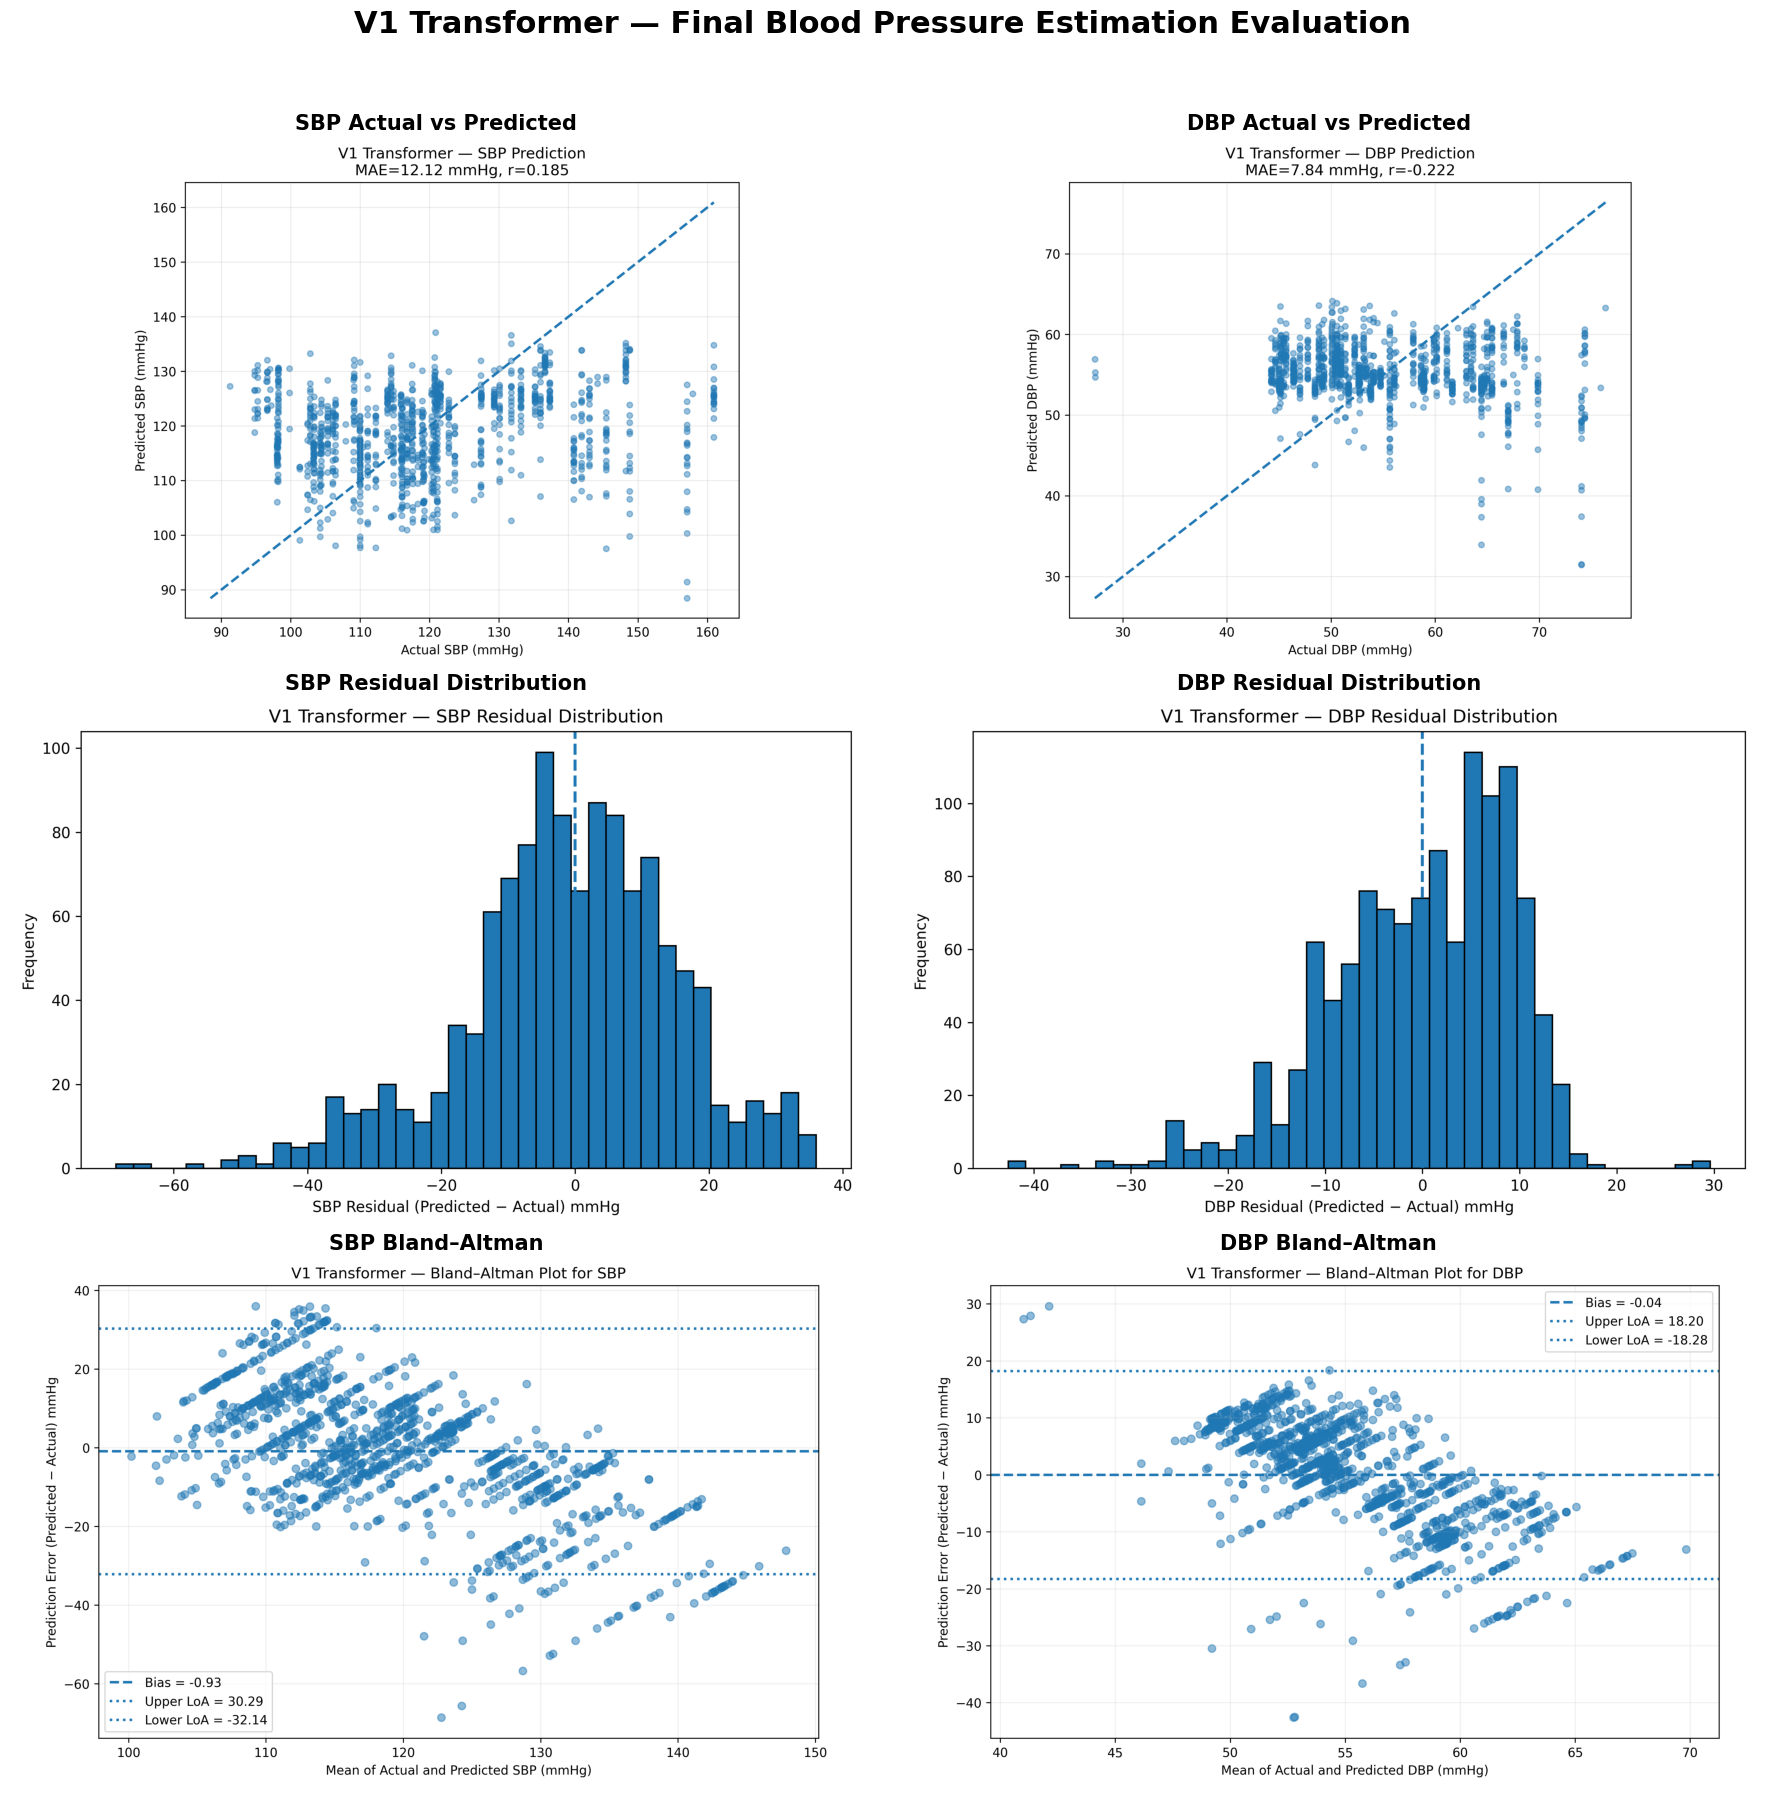


Saved:
/content/drive/MyDrive/BP_Transformer_Project/V1_Final/V1_FINAL_FIGURE_PANEL.png

STEP 12 COMPLETE


In [69]:
# ============================================================
# STEP 12 — FINAL V1 FIGURE PANEL
# ============================================================

import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

V1_DIR = "/content/drive/MyDrive/BP_Transformer_Project/V1_Final"

# ------------------------------------------------------------
# Source figures
# ------------------------------------------------------------

figure_files = [
    ("SBP Actual vs Predicted",
     "V1_SBP_Actual_vs_Predicted.png"),

    ("DBP Actual vs Predicted",
     "V1_DBP_Actual_vs_Predicted.png"),

    ("SBP Residual Distribution",
     "V1_SBP_Residual_Distribution.png"),

    ("DBP Residual Distribution",
     "V1_DBP_Residual_Distribution.png"),

    ("SBP Bland–Altman",
     "V1_SBP_Bland_Altman.png"),

    ("DBP Bland–Altman",
     "V1_DBP_Bland_Altman.png"),
]

# ------------------------------------------------------------
# Check files
# ------------------------------------------------------------

print("=" * 70)
print("STEP 12 — FINAL V1 FIGURE PANEL")
print("=" * 70)

missing = []

for title, filename in figure_files:
    path = os.path.join(V1_DIR, filename)

    if os.path.exists(path):
        print("✓ Found:", filename)
    else:
        print("✗ Missing:", filename)
        missing.append(filename)

if missing:
    raise FileNotFoundError(
        "The following required figures are missing:\n"
        + "\n".join(missing)
    )

# ------------------------------------------------------------
# Create 2 × 3 figure panel
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3,
    2,
    figsize=(18, 18)
)

for ax, (title, filename) in zip(axes.flatten(), figure_files):

    image_path = os.path.join(V1_DIR, filename)

    img = mpimg.imread(image_path)

    ax.imshow(img)
    ax.set_title(
        title,
        fontsize=15,
        fontweight="bold"
    )

    ax.axis("off")

# ------------------------------------------------------------
# Main title
# ------------------------------------------------------------

fig.suptitle(
    "V1 Transformer — Final Blood Pressure Estimation Evaluation",
    fontsize=22,
    fontweight="bold",
    y=0.995
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

output_path = os.path.join(
    V1_DIR,
    "V1_FINAL_FIGURE_PANEL.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print()
print("=" * 70)
print("Saved:")
print(output_path)
print()
print("STEP 12 COMPLETE")
print("=" * 70)

In [70]:
# ============================================================
# STEP 13 — FINAL V1 SCIENTIFIC CONCLUSIONS
# ============================================================

import os

V1_DIR = "/content/drive/MyDrive/BP_Transformer_Project/V1_Final"

conclusion_text = """
======================================================================
FINAL V1 SCIENTIFIC CONCLUSIONS
======================================================================


1. STUDY OBJECTIVE
----------------------------------------------------------------------

The objective of the V1 experiment was to establish a Transformer-
based baseline for cuffless blood pressure estimation and to evaluate
both its predictive performance and interpretability.

The model estimates two blood-pressure targets:

- Systolic Blood Pressure (SBP)
- Diastolic Blood Pressure (DBP)

Patch Occlusion was additionally used to investigate the spatial
contribution of image patches to the model predictions.


2. V1 MODEL CONFIGURATION
----------------------------------------------------------------------

Image size          : 224 x 224
Patch size          : 16 x 16
Input channels      : 3
Embedding dimension : 256
Attention heads     : 8
Transformer layers  : 6
Dropout             : 0.1
Total patches       : 196

Test samples        : 1190


3. KEY SBP FINDINGS
----------------------------------------------------------------------

SBP MAE         : 12.2842 mmHg
SBP RMSE        : 15.9469 mmHg
SBP Correlation : 0.1738
SBP R2          : -0.0766
SBP Bias        : -0.9251 mmHg

Actual SBP range:
91.26 - 160.94 mmHg

Predicted SBP range:
88.46 - 137.09 mmHg

The V1 model demonstrates a moderate absolute SBP error.
However, the low positive correlation indicates weak tracking of
actual SBP variation.

The predicted SBP range is substantially narrower than the actual
range. The model therefore tends to compress predictions toward the
central portion of the target distribution.

The strongest errors occur particularly at the extreme blood-pressure
ranges.


4. KEY DBP FINDINGS
----------------------------------------------------------------------

DBP MAE         : 7.5094 mmHg
DBP RMSE        : 9.3024 mmHg
DBP Correlation : -0.1891
DBP R2          : -0.3589
DBP Bias        : -0.0381 mmHg

Actual DBP range:
27.31 - 76.37 mmHg

Predicted DBP range:
31.44 - 64.13 mmHg

DBP achieves lower absolute error than SBP.

However, the negative correlation and negative R2 indicate that the
model does not adequately capture the variation of actual DBP values.

The predicted DBP range is also narrower than the actual range,
indicating prediction compression.


5. PREDICTION COMPRESSION
----------------------------------------------------------------------

One of the most important findings from V1 is prediction compression.

The model tends to predict values toward the central region of the
blood-pressure distribution instead of reproducing the complete
range of observed values.

For high SBP values, the model frequently produces substantially
lower predictions.

For low SBP values, predictions can be substantially higher than
the actual measurements.

A similar compression effect is observed for DBP.

This behavior explains the combination of moderate MAE values with
weak correlation and negative R2 values.


6. ERROR ANALYSIS
----------------------------------------------------------------------

The range-based error analysis demonstrates that model performance
is not uniform across blood-pressure levels.

For SBP:

- Errors are relatively large at low SBP values.
- Errors increase substantially at high SBP values.
- Central SBP ranges generally show lower error.

For DBP:

- Central DBP ranges show comparatively smaller errors.
- Extreme low and high DBP values produce substantially larger errors.

This indicates that the V1 model has difficulty estimating samples
located near the extremes of the target distribution.


7. RESIDUAL ANALYSIS
----------------------------------------------------------------------

SBP residual mean : -0.9251 mmHg
SBP residual std  : 15.9267 mmHg
SBP residual min  : -68.6001 mmHg
SBP residual max  : 35.9958 mmHg

DBP residual mean : -0.0381 mmHg
DBP residual std  : 9.3062 mmHg
DBP residual min  : -42.6252 mmHg
DBP residual max  : 29.6090 mmHg

The residual analysis confirms substantial prediction variability,
particularly for SBP.

The mean residuals are close to zero, but the large residual ranges
show that individual predictions can deviate considerably from actual
blood-pressure measurements.


8. BLAND-ALTMAN FINDINGS
----------------------------------------------------------------------

SBP:

Bias        : -0.9251 mmHg
Lower LoA   : -32.1415 mmHg
Upper LoA   : 30.2913 mmHg

DBP:

Bias        : -0.0381 mmHg
Lower LoA   : -18.2783 mmHg
Upper LoA   : 18.2021 mmHg

The average bias is small for both SBP and DBP.

However, the limits of agreement are relatively wide.

Therefore, the low average bias should not be interpreted as evidence
that every individual prediction is close to the actual measurement.

The Bland-Altman analysis demonstrates the difference between
overall systematic bias and individual prediction agreement.


9. XAI FINDINGS
----------------------------------------------------------------------

Explainability was performed using Patch Occlusion.

Image size     : 224 x 224
Patch size     : 16 x 16
Total patches  : 196

Separate patch attribution maps were generated for:

- SBP
- DBP

The XAI analysis identifies image regions where occlusion produces
a stronger change in the model prediction.

This provides a spatial interpretation of the Transformer output and
adds an explainability component to the V1 research pipeline.

The XAI results should be interpreted as model attribution rather
than direct physiological proof that a particular region causes
blood-pressure changes.


10. STRENGTHS OF V1
----------------------------------------------------------------------

The V1 experiment provides a complete and reproducible evaluation
pipeline containing:

- Transformer-based BP prediction
- Separate SBP and DBP evaluation
- MAE calculation
- RMSE calculation
- Correlation analysis
- R2 analysis
- Bias analysis
- Blood-pressure range analysis
- Worst-prediction analysis
- Residual analysis
- Bland-Altman analysis
- Actual-versus-predicted visualization
- Patch Occlusion XAI
- Final statistical summary
- Organized research artifacts


11. LIMITATIONS OF V1
----------------------------------------------------------------------

The major limitations observed from the V1 results are:

1. Weak correlation with actual BP variation.

2. Negative R2 values for both SBP and DBP.

3. Compressed prediction ranges.

4. Large errors at blood-pressure extremes.

5. Wide Bland-Altman limits of agreement.

6. Substantial individual prediction errors despite relatively small
   average bias.

7. The current V1 results do not demonstrate strong agreement between
   individual predictions and actual blood-pressure measurements.


12. OVERALL SCIENTIFIC INTERPRETATION
----------------------------------------------------------------------

V1 successfully establishes a complete Transformer-based baseline
for cuffless blood-pressure estimation.

The model produces measurable BP estimates and demonstrates lower
absolute error for DBP than for SBP.

However, the weak correlations, negative R2 values, compressed
prediction ranges, large extreme-value errors, and wide Bland-Altman
limits indicate that V1 does not yet adequately capture the complete
variability of blood pressure.

The most important technical observation is prediction compression,
where predictions are concentrated toward the middle of the observed
blood-pressure distribution.


13. FINAL CONCLUSION
----------------------------------------------------------------------

The V1 Transformer establishes a valid baseline and a complete
evaluation and explainability framework for cuffless blood-pressure
estimation.

The experiment demonstrates that Transformer-based image processing
can produce BP estimates, but the current V1 model has substantial
limitations in capturing BP variability and extreme measurements.

The V1 results therefore provide a strong experimental baseline for
the project and clearly identify the areas that require improvement
in future research.

V1 IS NOW THE LOCKED BASELINE.

The reported V1 metrics, predictions, analyses, figures, and XAI
results should not be modified or overwritten.


======================================================================
END OF FINAL V1 SCIENTIFIC CONCLUSIONS
======================================================================
"""

output_path = os.path.join(
    V1_DIR,
    "V1_FINAL_SCIENTIFIC_CONCLUSIONS.txt"
)

with open(output_path, "w", encoding="utf-8") as f:
    f.write(conclusion_text)

print("=" * 70)
print("STEP 13 — FINAL V1 SCIENTIFIC CONCLUSIONS")
print("=" * 70)

print("\nSaved:")
print(output_path)

print("\nSTEP 13 COMPLETE")
print("=" * 70)

STEP 13 — FINAL V1 SCIENTIFIC CONCLUSIONS

Saved:
/content/drive/MyDrive/BP_Transformer_Project/V1_Final/V1_FINAL_SCIENTIFIC_CONCLUSIONS.txt

STEP 13 COMPLETE


In [71]:
# ============================================================
# STEP 14 — FINAL V1 RESEARCH PACKAGE
# ============================================================

import os
import shutil
from datetime import datetime

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

V1_DIR = "/content/drive/MyDrive/BP_Transformer_Project/V1_Final"

PACKAGE_DIR = "/content/drive/MyDrive/BP_Transformer_Project/V1_Final_Research_Package"

os.makedirs(PACKAGE_DIR, exist_ok=True)

print("=" * 70)
print("STEP 14 — FINAL V1 RESEARCH PACKAGE")
print("=" * 70)

# ------------------------------------------------------------
# Files to package
# ------------------------------------------------------------

files_to_copy = [
    # Final documents
    "V1_FINAL_RESEARCH_SUMMARY.json",
    "V1_FINAL_RESULTS_DISCUSSION.txt",
    "V1_FINAL_SCIENTIFIC_CONCLUSIONS.txt",
    "V1_FINAL_EVALUATION_TABLE.csv",
    "V1_ERROR_ANALYSIS.csv",

    # Final figure panel
    "V1_FINAL_FIGURE_PANEL.png",

    # Prediction plots
    "V1_SBP_Actual_vs_Predicted.png",
    "V1_DBP_Actual_vs_Predicted.png",

    # Residual analysis
    "V1_SBP_Residual_Distribution.png",
    "V1_DBP_Residual_Distribution.png",

    # Bland-Altman
    "V1_SBP_Bland_Altman.png",
    "V1_DBP_Bland_Altman.png",

    # Error analysis
    "V1_SBP_Error_Analysis.png",
    "V1_DBP_Error_Analysis.png",

    # XAI
    "V1_XAI_SBP.png",
    "V1_XAI_DBP.png",
    "V1_XAI_SBP_CLEAN.png",
    "V1_XAI_DBP_CLEAN.png",
]

# ------------------------------------------------------------
# Copy files
# ------------------------------------------------------------

copied = []
missing = []

for filename in files_to_copy:

    source = os.path.join(V1_DIR, filename)
    destination = os.path.join(PACKAGE_DIR, filename)

    if os.path.exists(source):

        shutil.copy2(source, destination)

        copied.append(filename)

        print("✓ Copied:", filename)

    else:

        missing.append(filename)

        print("⚠ Missing:", filename)

# ------------------------------------------------------------
# Create README
# ------------------------------------------------------------

readme = f"""
======================================================================
V1 TRANSFORMER — FINAL RESEARCH PACKAGE
======================================================================

Project:
Transformer-Based Cuffless Blood Pressure Estimation

Version:
V1 — LOCKED BASELINE

Package created:
{datetime.now().strftime("%Y-%m-%d %H:%M:%S")}


======================================================================
MODEL CONFIGURATION
======================================================================

Image size          : 224 x 224
Patch size          : 16 x 16
Input channels      : 3
Embedding dimension : 256
Attention heads     : 8
Transformer layers  : 6
Dropout             : 0.1
Total patches       : 196


======================================================================
FINAL TEST SET
======================================================================

Test samples        : 1190


======================================================================
FINAL SBP RESULTS
======================================================================

MAE                 : 12.2842 mmHg
RMSE                : 15.9469 mmHg
Correlation         : 0.1738
R2                  : -0.0766
Bias                : -0.9251 mmHg

Actual range        : 91.26 - 160.94 mmHg
Prediction range    : 88.46 - 137.09 mmHg


======================================================================
FINAL DBP RESULTS
======================================================================

MAE                 : 7.5094 mmHg
RMSE                : 9.3024 mmHg
Correlation         : -0.1891
R2                  : -0.3589
Bias                : -0.0381 mmHg

Actual range        : 27.31 - 76.37 mmHg
Prediction range    : 31.44 - 64.13 mmHg


======================================================================
XAI
======================================================================

Method              : Patch Occlusion
Patch size          : 16 x 16
Total patches       : 196

Outputs:

1. SBP patch attribution
2. DBP patch attribution


======================================================================
IMPORTANT V1 FINDING
======================================================================

The major limitation observed in V1 is prediction compression.

The model tends to produce predictions toward the central region of
the blood-pressure distribution instead of reproducing the complete
range of observed blood-pressure values.

The effect is particularly visible for extreme SBP and DBP values.


======================================================================
STATISTICAL ANALYSIS INCLUDED
======================================================================

- MAE
- RMSE
- Correlation
- R2
- Bias
- Residual analysis
- Blood-pressure range analysis
- Worst prediction analysis
- Bland-Altman analysis
- Actual vs predicted analysis
- Patch Occlusion XAI


======================================================================
FILE GUIDE
======================================================================

V1_FINAL_RESEARCH_SUMMARY.json
    Machine-readable final V1 summary.

V1_FINAL_RESULTS_DISCUSSION.txt
    Detailed interpretation of V1 results.

V1_FINAL_SCIENTIFIC_CONCLUSIONS.txt
    Final scientific findings, strengths and limitations.

V1_FINAL_EVALUATION_TABLE.csv
    Final SBP/DBP evaluation metrics.

V1_ERROR_ANALYSIS.csv
    Range-based and prediction error analysis.

V1_FINAL_FIGURE_PANEL.png
    Combined six-panel evaluation figure.

V1_SBP_Actual_vs_Predicted.png
    SBP prediction performance.

V1_DBP_Actual_vs_Predicted.png
    DBP prediction performance.

V1_SBP_Residual_Distribution.png
    SBP residual distribution.

V1_DBP_Residual_Distribution.png
    DBP residual distribution.

V1_SBP_Bland_Altman.png
    SBP Bland-Altman agreement analysis.

V1_DBP_Bland_Altman.png
    DBP Bland-Altman agreement analysis.

V1_SBP_Error_Analysis.png
    SBP error by blood-pressure range.

V1_DBP_Error_Analysis.png
    DBP error by blood-pressure range.

V1_XAI_SBP.png
    SBP Patch Occlusion attribution.

V1_XAI_DBP.png
    DBP Patch Occlusion attribution.

V1_XAI_SBP_CLEAN.png
    Clean SBP XAI visualization.

V1_XAI_DBP_CLEAN.png
    Clean DBP XAI visualization.


======================================================================
BASELINE STATUS
======================================================================

V1 IS LOCKED.

The reported V1 metrics and evaluation results should not be modified
or overwritten.

This package represents the final V1 experimental baseline.


======================================================================
PACKAGE STATUS
======================================================================

Files successfully copied : {len(copied)}
Missing files             : {len(missing)}

======================================================================
END OF V1 RESEARCH PACKAGE
======================================================================
"""

readme_path = os.path.join(
    PACKAGE_DIR,
    "README_V1_FINAL.txt"
)

with open(readme_path, "w", encoding="utf-8") as f:
    f.write(readme)

print("✓ Created: README_V1_FINAL.txt")

# ------------------------------------------------------------
# Create package manifest
# ------------------------------------------------------------

manifest = {
    "project": "Transformer-Based Cuffless Blood Pressure Estimation",
    "version": "V1",
    "status": "LOCKED BASELINE",
    "test_samples": 1190,
    "files_copied": len(copied),
    "files_missing": len(missing),
    "package_directory": PACKAGE_DIR,
    "created": datetime.now().isoformat(),
}

import json

manifest_path = os.path.join(
    PACKAGE_DIR,
    "V1_PACKAGE_MANIFEST.json"
)

with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=4)

print("✓ Created: V1_PACKAGE_MANIFEST.json")

# ------------------------------------------------------------
# Final status
# ------------------------------------------------------------

print()
print("=" * 70)
print("FINAL V1 RESEARCH PACKAGE")
print("=" * 70)

print()
print("Package directory:")
print(PACKAGE_DIR)

print()
print("Files copied:", len(copied))
print("Files missing:", len(missing))

if missing:
    print()
    print("Missing files:")
    for f in missing:
        print(" -", f)

print()
print("=" * 70)

if len(missing) == 0:
    print("✓ V1 RESEARCH PACKAGE COMPLETE")
    print("✓ ALL EXPECTED FILES PRESENT")
else:
    print("⚠ PACKAGE CREATED WITH MISSING FILES")

print("=" * 70)
print("STEP 14 COMPLETE")
print("=" * 70)

STEP 14 — FINAL V1 RESEARCH PACKAGE
✓ Copied: V1_FINAL_RESEARCH_SUMMARY.json
✓ Copied: V1_FINAL_RESULTS_DISCUSSION.txt
✓ Copied: V1_FINAL_SCIENTIFIC_CONCLUSIONS.txt
✓ Copied: V1_FINAL_EVALUATION_TABLE.csv
✓ Copied: V1_ERROR_ANALYSIS.csv
✓ Copied: V1_FINAL_FIGURE_PANEL.png
✓ Copied: V1_SBP_Actual_vs_Predicted.png
✓ Copied: V1_DBP_Actual_vs_Predicted.png
✓ Copied: V1_SBP_Residual_Distribution.png
✓ Copied: V1_DBP_Residual_Distribution.png
✓ Copied: V1_SBP_Bland_Altman.png
✓ Copied: V1_DBP_Bland_Altman.png
✓ Copied: V1_SBP_Error_Analysis.png
✓ Copied: V1_DBP_Error_Analysis.png
✓ Copied: V1_XAI_SBP.png
✓ Copied: V1_XAI_DBP.png
✓ Copied: V1_XAI_SBP_CLEAN.png
✓ Copied: V1_XAI_DBP_CLEAN.png
✓ Created: README_V1_FINAL.txt
✓ Created: V1_PACKAGE_MANIFEST.json

FINAL V1 RESEARCH PACKAGE

Package directory:
/content/drive/MyDrive/BP_Transformer_Project/V1_Final_Research_Package

Files copied: 18
Files missing: 0

✓ V1 RESEARCH PACKAGE COMPLETE
✓ ALL EXPECTED FILES PRESENT
STEP 14 COMPLETE


In [8]:
import os

paths = [
    "/content/best_transformer_bp_model.pth",
    "/content/drive/MyDrive/BP_Transformer_Project/V1_Final/best_transformer_bp_model.pth",
    "/content/drive/MyDrive/BP_Transformer_Project/V1_Final_Research_Package/best_transformer_bp_model.pth",
]

for path in paths:
    print("=" * 70)
    print(path)
    print("Exists:", os.path.exists(path))
    if os.path.exists(path):
        print("Size:", round(os.path.getsize(path) / (1024 * 1024), 2), "MB")

/content/best_transformer_bp_model.pth
Exists: False
/content/drive/MyDrive/BP_Transformer_Project/V1_Final/best_transformer_bp_model.pth
Exists: False
/content/drive/MyDrive/BP_Transformer_Project/V1_Final_Research_Package/best_transformer_bp_model.pth
Exists: False
